In [ ]:
from google.colab import drive

drive.mount('/content/drive')

print(" Google Drive mounted successfully.")

Mounted at /content/drive
 Google Drive mounted successfully.


In [ ]:
import os
import sys
import glob
import shutil
import subprocess
import time
import math
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

print(" Basic Python libraries imported.")

 Basic Python libraries imported.


In [ ]:
import os

files = [
    "/content/EnergyPlus-23.1.0.sh",
    "/content/EnergyPlus-23.1.0-87ed9199d4-Linux-Ubuntu20.04-x86_64.sh",
    "/content/EnergyPlus-23.1.0-87ed9199d4-Linux-Ubuntu22.04-x86_64.sh"
]

for f in files:
    if os.path.exists(f):
        os.remove(f)
        print("Deleted:", f)

print("Cleanup done.")

Cleanup done.


In [ ]:
import subprocess
import os

URL = (
    "https://github.com/NatLabRockies/EnergyPlus/"
    "releases/download/v23.1.0/"
    "EnergyPlus-23.1.0-87ed9199d4-Linux-Ubuntu22.04-x86_64.sh"
)

INSTALLER = (
    "/content/"
    "EnergyPlus-23.1.0-87ed9199d4-Linux-Ubuntu22.04-x86_64.sh"
)

print("Downloading correct EnergyPlus installer...")

result = subprocess.run(
    [
        "wget",
        "-q",
        "--show-progress",
        "-O",
        INSTALLER,
        URL
    ],
    text=True
)

if result.returncode != 0:
    raise RuntimeError(
        " Download failed."
    )

size_mb = (
    os.path.getsize(INSTALLER)
    / (1024 * 1024)
)

print("\nDownloaded successfully.")
print(f"File size: {size_mb:.2f} MB")

if size_mb < 100:
    raise RuntimeError(
        " Installer is too small. "
        "Download may be corrupted."
    )

print("✅ Installer looks valid.")


Downloaded successfully.
File size: 172.45 MB
✅ Installer looks valid.


In [ ]:
import os

INSTALLER = (
    "/content/"
    "EnergyPlus-23.1.0-87ed9199d4-Linux-Ubuntu22.04-x86_64.sh"
)

os.chmod(
    INSTALLER,
    0o755
)

print(" Installer permission configured.")

 Installer permission configured.


In [ ]:
import subprocess
import os

INSTALL_DIR = (
    "/usr/local/EnergyPlus-23-1-0"
)

print("Installing EnergyPlus 23.1.0...")
print("Install directory:", INSTALL_DIR)
print()

# Modified to pipe 'y' to stdin to accept the license
result = subprocess.run(
    [
        INSTALLER,
        "-y",
        "-d",
        INSTALL_DIR
    ],
    input="y\n", # Pass 'y' and a newline to simulate pressing 'y' then Enter
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True
)

print(result.stdout)

print("\nExit code:", result.returncode)

if result.returncode != 0:
    raise RuntimeError(
        " Installation failed. "
        "The installer output above is the actual error."
    )

print(
    "\n EnergyPlus installed successfully!"
)

Installing EnergyPlus 23.1.0...
Install directory: /usr/local/EnergyPlus-23-1-0

EnergyPlus, Copyright (c) 1996-2023, The Board of Trustees of the University of Illinois, The Regents of the University of California, through Lawrence Berkeley National Laboratory (subject to receipt of any required approvals from the U.S. Dept. of Energy), Oak Ridge National Laboratory, managed by UT-Battelle, Alliance for Sustainable Energy, LLC, and other contributors. All rights reserved.

NOTICE: This Software was developed under funding from the U.S. Department of Energy and the U.S. Government consequently retains certain rights. As such, the U.S. Government has been granted for itself and others acting on its behalf a paid-up, nonexclusive, irrevocable, worldwide license in the Software to reproduce, distribute copies to the public, prepare derivative works, and perform publicly and display publicly, and to permit others to do so.

Redistribution and use in source and binary forms, with or without

In [ ]:
import os

ENERGYPLUS_ROOT = (
    "/usr/local/EnergyPlus-23-1-0"
)

print(
    "EnergyPlus directory:",
    ENERGYPLUS_ROOT
)

print(
    "Directory exists:",
    os.path.isdir(
        ENERGYPLUS_ROOT
    )
)

API_FILE = os.path.join(
    ENERGYPLUS_ROOT,
    "pyenergyplus",
    "api.py"
)

ENERGYPLUS_EXE = os.path.join(
    ENERGYPLUS_ROOT,
    "energyplus"
)

print(
    "\npyenergyplus/api.py:",
    os.path.isfile(API_FILE)
)

print(
    "energyplus executable:",
    os.path.isfile(ENERGYPLUS_EXE)
)

EnergyPlus directory: /usr/local/EnergyPlus-23-1-0
Directory exists: True

pyenergyplus/api.py: True
energyplus executable: True


In [ ]:
import subprocess

result = subprocess.run(
    [
        ENERGYPLUS_EXE,
        "--version"
    ],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError(
        "EnergyPlus executable is not working."
    )

print(
    " EnergyPlus is working."
)

EnergyPlus, Version 23.1.0-87ed9199d4, YMD=2026.08.19 09:32

 EnergyPlus is working.


In [ ]:
import os
import glob
import subprocess

print("=== CHECKING ENERGYPLUS ===\n")

# 1. Check standard installation location
paths = [
    "/usr/local/EnergyPlus-23-1-0",
    "/usr/local/EnergyPlus-23-1-0/pyenergyplus",
    "/usr/local/bin/energyplus"
]

for p in paths:
    print(p, "->", os.path.exists(p))

print("\n=== SEARCHING FOR api.py ===\n")

result = subprocess.run(
    [
        "find",
        "/usr/local",
        "/opt",
        "/content",
        "-type",
        "f",
        "-name",
        "api.py"
    ],
    capture_output=True,
    text=True
)

print(result.stdout)

print("=== SEARCHING FOR ENERGYPLUS ===\n")

result2 = subprocess.run(
    [
        "find",
        "/usr/local",
        "/opt",
        "/content",
        "-type",
        "f",
        "-name",
        "energyplus"
    ],
    capture_output=True,
    text=True
)

print(result2.stdout)

=== CHECKING ENERGYPLUS ===

/usr/local/EnergyPlus-23-1-0 -> True
/usr/local/EnergyPlus-23-1-0/pyenergyplus -> True
/usr/local/bin/energyplus -> True

=== SEARCHING FOR api.py ===

/usr/local/lib/python3.12/dist-packages/pip/_vendor/requests/api.py
/usr/local/lib/python3.12/dist-packages/pip/_vendor/platformdirs/api.py
/usr/local/lib/python3.12/dist-packages/setuptools/_vendor/platformdirs/api.py
/usr/local/lib/python3.12/dist-packages/jax/experimental/sparse/api.py
/usr/local/lib/python3.12/dist-packages/jax/experimental/colocated_python/api.py
/usr/local/lib/python3.12/dist-packages/jax/_src/api.py
/usr/local/lib/python3.12/dist-packages/uritemplate/api.py
/usr/local/lib/python3.12/dist-packages/tensorflow/dtensor/python/api.py
/usr/local/lib/python3.12/dist-packages/tensorflow/python/autograph/impl/api.py
/usr/local/lib/python3.12/dist-packages/tensorflow/python/tpu/api.py
/usr/local/lib/python3.12/dist-packages/altair/vegalite/v5/api.py
/usr/local/lib/python3.12/dist-packages/altai

In [ ]:
import sys
import os

ENERGYPLUS_ROOT = "/usr/local/EnergyPlus-23-1-0"

# Add EnergyPlus to Python path
if ENERGYPLUS_ROOT not in sys.path:
    sys.path.insert(0, ENERGYPLUS_ROOT)

# Set environment variables
os.environ["ENERGYPLUS_PATH"] = ENERGYPLUS_ROOT

os.environ["PYTHONPATH"] = (
    ENERGYPLUS_ROOT
    + ":"
    + os.environ.get("PYTHONPATH", "")
)

print("EnergyPlus path configured:")
print(ENERGYPLUS_ROOT)

EnergyPlus path configured:
/usr/local/EnergyPlus-23-1-0


In [ ]:
import sys
import os

print("EnergyPlus root exists:",
      os.path.isdir(ENERGYPLUS_ROOT))

print("API file exists:",
      os.path.isfile(
          os.path.join(
              ENERGYPLUS_ROOT,
              "pyenergyplus",
              "api.py"
          )
      ))

print("\nPython path contains EnergyPlus:")

for p in sys.path:
    if "EnergyPlus" in p:
        print(p)

EnergyPlus root exists: True
API file exists: True

Python path contains EnergyPlus:
/usr/local/EnergyPlus-23-1-0


In [ ]:
from pyenergyplus.api import EnergyPlusAPI

print(" pyenergyplus imported successfully!")

api = EnergyPlusAPI()

print(" EnergyPlusAPI created successfully!")

 pyenergyplus imported successfully!
 EnergyPlusAPI created successfully!


In [ ]:
import subprocess

result = subprocess.run(
    [
        "/usr/local/bin/energyplus",
        "--version"
    ],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode == 0:
    print(" EnergyPlus executable is working!")
else:
    print(result.stderr)

EnergyPlus, Version 23.1.0-87ed9199d4, YMD=2026.08.19 09:34

 EnergyPlus executable is working!


In [ ]:
!pip install -q "sinergym==3.4.0" "stable-baselines3[extra]" gymnasium

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 3.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.8/45.8 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.7/8.7 MB 54.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.7/89.7 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.7/10.7 MB 55.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 55.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 53.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.7/4.7 MB 61.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 187.6/187.6 kB 14.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.2/43.2 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 310.7/310.7 kB 20.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 175.3/175.3

In [ ]:
import sys
import os

ENERGYPLUS_ROOT = "/usr/local/EnergyPlus-23-1-0"

if ENERGYPLUS_ROOT not in sys.path:
    sys.path.insert(0, ENERGYPLUS_ROOT)

os.environ["ENERGYPLUS_PATH"] = ENERGYPLUS_ROOT

print("EnergyPlus path:", ENERGYPLUS_ROOT)
print("Python path configured:", ENERGYPLUS_ROOT in sys.path)

EnergyPlus path: /usr/local/EnergyPlus-23-1-0
Python path configured: True


In [ ]:
from pyenergyplus.api import EnergyPlusAPI

import gymnasium as gym
import sinergym

from stable_baselines3 import SAC

print(" pyenergyplus: OK")
print(" gymnasium: OK")
print(" sinergym: OK")
print(" Stable-Baselines3 SAC: OK")

 pyenergyplus: OK
 gymnasium: OK
 sinergym: OK
 Stable-Baselines3 SAC: OK


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
import gymnasium.envs.registration

print("Available Sinergym environments:\n")

# Sinergym registers its environments in the common Gymnasium registry.
# We can filter them out by checking if 'sinergym' is in the environment ID.
for env_id in gymnasium.envs.registration.registry.keys():
    if "sinergym" in env_id:
        print(env_id)

Available Sinergym environments:



In [ ]:
print("=== CHECKING SINERGYM INSTALLATION ===")

import sinergym
import gymnasium as gym

print("Sinergym version:", getattr(sinergym, "__version__", "unknown"))
print("Sinergym location:", sinergym.__file__)

print("\nRegistered Sinergym environments:")
for env_id in gym.registry.keys():
    if "sinergym" in env_id.lower() or "eplus" in env_id.lower():
        print(env_id)

=== CHECKING SINERGYM INSTALLATION ===
Sinergym version: 3.4.0
Sinergym location: /usr/local/lib/python3.12/dist-packages/sinergym/__init__.py

Registered Sinergym environments:
Eplus-demo-v1
Eplus-officegrid-hot-continuous-v1
Eplus-officegrid-hot-discrete-v1
Eplus-officegrid-hot-continuous-stochastic-v1
Eplus-officegrid-hot-discrete-stochastic-v1
Eplus-officegrid-mixed-continuous-v1
Eplus-officegrid-mixed-discrete-v1
Eplus-officegrid-mixed-continuous-stochastic-v1
Eplus-officegrid-mixed-discrete-stochastic-v1
Eplus-officegrid-cool-continuous-v1
Eplus-officegrid-cool-discrete-v1
Eplus-officegrid-cool-continuous-stochastic-v1
Eplus-officegrid-cool-discrete-stochastic-v1
Eplus-radiant-hot-discrete-v1
Eplus-radiant-hot-discrete-stochastic-v1
Eplus-radiant-mixed-discrete-v1
Eplus-radiant-mixed-discrete-stochastic-v1
Eplus-radiant-cool-discrete-v1
Eplus-radiant-cool-discrete-stochastic-v1
Eplus-radiant-stockholm-discrete-v1
Eplus-radiant-stockholm-discrete-stochastic-v1
Eplus-smalldatacente

In [ ]:
import os

print("=== SEARCHING PROJECT FILES ===")

for root, dirs, files in os.walk("/content"):
    for file in files:
        if file.endswith(".py"):
            path = os.path.join(root, file)
            try:
                with open(path, "r", errors="ignore") as f:
                    text = f.read()

                if "dhaka-radiant-residential-v1" in text:
                    print("\nFOUND:")
                    print(path)

            except:
                pass

=== SEARCHING PROJECT FILES ===


In [ ]:
import sinergym
print("SINERGYM IMPORTED SUCCESSFULLY")
print(sinergym.__file__)

SINERGYM IMPORTED SUCCESSFULLY
/usr/local/lib/python3.12/dist-packages/sinergym/__init__.py


In [ ]:
import gymnasium as gym

print("GYMNASIUM IMPORTED SUCCESSFULLY")
print("Gymnasium version:", gym.__version__)

GYMNASIUM IMPORTED SUCCESSFULLY
Gymnasium version: 1.3.0


In [ ]:
api = EnergyPlusAPI()

print(" EnergyPlusAPI initialized successfully!")

 EnergyPlusAPI initialized successfully!


In [ ]:
from google.colab import drive
import os

drive.mount("/content/drive", force_remount=False)

PROJECT_DIR = (
    "/content/drive/MyDrive/"
    "BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025"
)

DATA_DIR = os.path.join(
    PROJECT_DIR,
    "data"
)

CHECKPOINT_DIR = os.path.join(
    PROJECT_DIR,
    "checkpoints"
)

RESULTS_DIR = os.path.join(
    PROJECT_DIR,
    "results"
)

os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

print("PROJECT_DIR:", PROJECT_DIR)
print("DATA_DIR:", DATA_DIR)
print("CHECKPOINT_DIR:", CHECKPOINT_DIR)
print("RESULTS_DIR:", RESULTS_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PROJECT_DIR: /content/drive/MyDrive/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025
DATA_DIR: /content/drive/MyDrive/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025/data
CHECKPOINT_DIR: /content/drive/MyDrive/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025/checkpoints
RESULTS_DIR: /content/drive/MyDrive/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025/results


In [ ]:
import os

for root, dirs, files in os.walk(
    "/content/drive/MyDrive"
):

    for file in files:

        if file.lower().endswith(".epw"):

            print(
                os.path.join(root, file)
            )

/content/drive/MyDrive/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw
/content/drive/MyDrive/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025/data/Dhaka.epw
/content/drive/MyDrive/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025/data/weather/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw
/content/drive/MyDrive/content/drive/MyDrive/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw/data/Dhaka.epw


In [ ]:
import os
import glob

print("=== SEARCHING FOR EPW FILE ===\n")

epw_files = []

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for file in files:
        if file.lower().endswith(".epw"):
            epw_files.append(os.path.join(root, file))

if not epw_files:
    raise FileNotFoundError(
        "No .epw file found inside Google Drive."
    )

for i, f in enumerate(epw_files):
    print(f"[{i}] {f}")

# Automatically use the first EPW file
EPW_FILE = epw_files[0]

print("\nSelected EPW file:")
print(EPW_FILE)

if not os.path.isfile(EPW_FILE):
    raise FileNotFoundError("Selected EPW file does not exist.")

print("\nEPW file found successfully.")

=== SEARCHING FOR EPW FILE ===

[0] /content/drive/MyDrive/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw
[1] /content/drive/MyDrive/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025/data/Dhaka.epw
[2] /content/drive/MyDrive/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025/data/weather/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw
[3] /content/drive/MyDrive/content/drive/MyDrive/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw/data/Dhaka.epw

Selected EPW file:
/content/drive/MyDrive/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw

EPW file found successfully.


In [ ]:
import os

print("=== EPW FILE CHECK ===\n")

file_size_mb = (
    os.path.getsize(EPW_FILE) / (1024 * 1024)
)

print("File:", EPW_FILE)
print(f"Size: {file_size_mb:.2f} MB")

with open(EPW_FILE, "r", errors="ignore") as f:
    first_lines = [next(f) for _ in range(8)]

print("\nFirst 8 lines:\n")

for line in first_lines:
    print(line.strip())

print("\nEPW file is readable.")

=== EPW FILE CHECK ===

File: /content/drive/MyDrive/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw
Size: 1.55 MB

First 8 lines:

LOCATION,Dhaka-Shahjalal.Intl.AP,DH,BGD,SRC-TMYx,419220,23.84300,90.39800,6.0,9.1
DESIGN CONDITIONS,1,2025 ASHRAE Handbook -- Fundamentals - Chapter 14 Climatic Design Information,Heating,1,13.0,14.2,7.7,6.5,23.5,9.4,7.3,22.2,5.4,20.8,5.2,20.9,1.3,300,0.350,Cooling,6,5.7,36.2,25.9,35.3,26.1,34.5,26.1,28.7,33.2,28.3,32.5,28.0,31.9,4.1,180,27.5,23.4,31.4,27.2,23.1,31.2,26.9,22.5,30.8,93.0,33.2,90.3,32.8,88.8,32.2,32.2,Extremes,7.6,6.4,5.9,11.6,38.2,1.8,1.8,10.3,39.5,9.2,40.6,8.2,41.6,6.9,42.9,10.5,29.7,1.8,1.0,9.2,30.4,8.2,31.0,7.2,31.5,5.9,32.2
TYPICAL/EXTREME PERIODS,4,Wet Season - Week Near Average For Period,Typical,9/23,9/29,Dry Season - Week Near Average For Period,Typical,2/10,2/16,Tropical Hot - Week Nearest Max Temperature For Period,Extreme,6/ 4,6/10,Tropical Cold- Week Nearest Min Tempe

In [ ]:
import os
import sys

ENERGYPLUS_ROOT = "/usr/local/EnergyPlus-23-1-0"

os.environ["ENERGYPLUS_PATH"] = ENERGYPLUS_ROOT

if ENERGYPLUS_ROOT not in sys.path:
    sys.path.insert(0, ENERGYPLUS_ROOT)

print("=== PATH CONFIGURATION ===")
print("EnergyPlus:", ENERGYPLUS_ROOT)
print("Exists:", os.path.isdir(ENERGYPLUS_ROOT))
print("EPW:", EPW_FILE)
print("EPW exists:", os.path.isfile(EPW_FILE))

=== PATH CONFIGURATION ===
EnergyPlus: /usr/local/EnergyPlus-23-1-0
Exists: True
EPW: /content/drive/MyDrive/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw
EPW exists: True


In [ ]:
import gymnasium as gym
import sinergym
import numpy as np
import pandas as pd

from stable_baselines3 import SAC

from pyenergyplus.api import EnergyPlusAPI

print("=== PACKAGE CHECK ===\n")

print("Gymnasium:", gym.__version__)
print("Sinergym:", sinergym.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

api = EnergyPlusAPI()

print("\nEnergyPlus API: OK")
print("SAC: OK")
print("All required packages imported successfully.")

=== PACKAGE CHECK ===

Gymnasium: 1.3.0
Sinergym: 3.4.0
NumPy: 2.0.2
Pandas: 2.2.3

EnergyPlus API: OK
SAC: OK
All required packages imported successfully.


In [ ]:
import gymnasium as gym
import sinergym

print("=== SINERGYM ENVIRONMENTS ===\n")

sinergym_envs = []

for env_id in gym.registry.keys():
    if "Eplus" in env_id or "EnergyPlus" in env_id:
        sinergym_envs.append(env_id)

if sinergym_envs:
    for env_id in sinergym_envs:
        print(env_id)
else:
    print("No EnergyPlus environments found in registry.")

print("\nTotal:", len(sinergym_envs))

=== SINERGYM ENVIRONMENTS ===

Eplus-demo-v1
Eplus-officegrid-hot-continuous-v1
Eplus-officegrid-hot-discrete-v1
Eplus-officegrid-hot-continuous-stochastic-v1
Eplus-officegrid-hot-discrete-stochastic-v1
Eplus-officegrid-mixed-continuous-v1
Eplus-officegrid-mixed-discrete-v1
Eplus-officegrid-mixed-continuous-stochastic-v1
Eplus-officegrid-mixed-discrete-stochastic-v1
Eplus-officegrid-cool-continuous-v1
Eplus-officegrid-cool-discrete-v1
Eplus-officegrid-cool-continuous-stochastic-v1
Eplus-officegrid-cool-discrete-stochastic-v1
Eplus-radiant-hot-discrete-v1
Eplus-radiant-hot-discrete-stochastic-v1
Eplus-radiant-mixed-discrete-v1
Eplus-radiant-mixed-discrete-stochastic-v1
Eplus-radiant-cool-discrete-v1
Eplus-radiant-cool-discrete-stochastic-v1
Eplus-radiant-stockholm-discrete-v1
Eplus-radiant-stockholm-discrete-stochastic-v1
Eplus-smalldatacenter-hot-continuous-v1
Eplus-smalldatacenter-hot-continuous-stochastic-v1
Eplus-smalldatacenter-mixed-continuous-v1
Eplus-smalldatacenter-mixed-contin

In [ ]:
import sinergym
import os

SINERGYM_DIR = os.path.dirname(sinergym.__file__)

print("Sinergym directory:")
print(SINERGYM_DIR)

print("\n=== Searching for environment/config files ===\n")

for root, dirs, files in os.walk(SINERGYM_DIR):

    for file in files:

        if (
            file.endswith(".yaml")
            or file.endswith(".yml")
            or file.endswith(".json")
            or file.endswith(".idf")
        ):
            print(
                os.path.join(root, file)
            )

Sinergym directory:
/usr/local/lib/python3.12/dist-packages/sinergym

=== Searching for environment/config files ===

/usr/local/lib/python3.12/dist-packages/sinergym/data/default_configuration/LrgOff_GridStorageScheduled.json
/usr/local/lib/python3.12/dist-packages/sinergym/data/default_configuration/radiant_residential_building.json
/usr/local/lib/python3.12/dist-packages/sinergym/data/default_configuration/1ZoneDataCenterCRAC_wApproachTemp.json
/usr/local/lib/python3.12/dist-packages/sinergym/data/default_configuration/ShopWithPVandBattery.json
/usr/local/lib/python3.12/dist-packages/sinergym/data/default_configuration/ASHRAE901_Warehouse_STD2019_Denver.json
/usr/local/lib/python3.12/dist-packages/sinergym/data/default_configuration/5ZoneAutoDXVAV.json
/usr/local/lib/python3.12/dist-packages/sinergym/data/default_configuration/2ZoneDataCenterHVAC_wEconomizer.json
/usr/local/lib/python3.12/dist-packages/sinergym/data/default_configuration/ASHRAE901_OfficeMedium_STD2019_Denver.json


In [ ]:
import os
import sinergym

SINERGYM_DIR = os.path.dirname(sinergym.__file__)

print("=== SEARCHING FOR IDF BUILDING MODELS ===\n")

idf_files = []

for root, dirs, files in os.walk(SINERGYM_DIR):

    for file in files:

        if file.lower().endswith(".idf"):
            idf_files.append(
                os.path.join(root, file)
            )

for f in idf_files:
    print(f)

print("\nTotal IDF files:", len(idf_files))

=== SEARCHING FOR IDF BUILDING MODELS ===


Total IDF files: 0


In [ ]:
import os
import sinergym

SINERGYM_DIR = os.path.dirname(sinergym.__file__)

print("Sinergym directory:")
print(SINERGYM_DIR)

print("\n=== SINERGYM DIRECTORY TREE ===\n")

for root, dirs, files in os.walk(SINERGYM_DIR):
    level = root.replace(SINERGYM_DIR, "").count(os.sep)
    indent = "    " * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in files[:20]:
        print(f"{indent}    {file}")

Sinergym directory:
/usr/local/lib/python3.12/dist-packages/sinergym

=== SINERGYM DIRECTORY TREE ===

sinergym/
    version.txt
    __init__.py
    simulators/
        __init__.py
        eplus.py
        __pycache__/
            eplus.cpython-312.pyc
            __init__.cpython-312.pyc
    envs/
        __init__.py
        eplus_env.py
        __pycache__/
            __init__.cpython-312.pyc
            eplus_env.cpython-312.pyc
    utils/
        gcloud.py
        env_checker.py
        callbacks.py
        rewards.py
        controllers.py
        __init__.py
        evaluation.py
        logger.py
        common.py
        constants.py
        wrappers.py
        __pycache__/
            common.cpython-312.pyc
            evaluation.cpython-312.pyc
            __init__.cpython-312.pyc
            callbacks.cpython-312.pyc
            controllers.cpython-312.pyc
            logger.cpython-312.pyc
            env_checker.cpython-312.pyc
            gcloud.cpython-312.pyc
         

In [ ]:
import os
import sinergym

SINERGYM_DIR = os.path.dirname(sinergym.__file__)

print("=== SEARCHING FOR ENERGYPLUS FILES ===\n")

extensions = (
    ".idf",
    ".epw",
    ".ddy",
    ".rvi",
    ".csv",
    ".json",
    ".yaml",
    ".yml"
)

found = []

for root, dirs, files in os.walk(SINERGYM_DIR):

    for file in files:

        if file.lower().endswith(extensions):

            path = os.path.join(root, file)

            found.append(path)

            print(path)

print("\nTotal files found:", len(found))

=== SEARCHING FOR ENERGYPLUS FILES ===

/usr/local/lib/python3.12/dist-packages/sinergym/data/default_configuration/LrgOff_GridStorageScheduled.json
/usr/local/lib/python3.12/dist-packages/sinergym/data/default_configuration/radiant_residential_building.json
/usr/local/lib/python3.12/dist-packages/sinergym/data/default_configuration/1ZoneDataCenterCRAC_wApproachTemp.json
/usr/local/lib/python3.12/dist-packages/sinergym/data/default_configuration/ShopWithPVandBattery.json
/usr/local/lib/python3.12/dist-packages/sinergym/data/default_configuration/ASHRAE901_Warehouse_STD2019_Denver.json
/usr/local/lib/python3.12/dist-packages/sinergym/data/default_configuration/5ZoneAutoDXVAV.json
/usr/local/lib/python3.12/dist-packages/sinergym/data/default_configuration/2ZoneDataCenterHVAC_wEconomizer.json
/usr/local/lib/python3.12/dist-packages/sinergym/data/default_configuration/ASHRAE901_OfficeMedium_STD2019_Denver.json
/usr/local/lib/python3.12/dist-packages/sinergym/data/weather/MDG_Antananarivo.6

In [ ]:
import sinergym
import inspect

from sinergym.envs.eplus_env import EplusEnv

print("Sinergym version:", sinergym.__version__)

print("\n=== EplusEnv constructor ===\n")

print(
    inspect.signature(EplusEnv)
)

print("\n=== EplusEnv source header ===\n")

source = inspect.getsource(EplusEnv)

print(source[:12000])

Sinergym version: 3.4.0

=== EplusEnv constructor ===

(building_file: str, weather_files: Union[str, List[str]], action_space: gymnasium.spaces.box.Box = Box([], [], (0,), float32), time_variables: List[str] = [], variables: Dict[str, Tuple[str, str]] = {}, meters: Dict[str, str] = {}, actuators: Dict[str, Tuple[str, str, str]] = {}, weather_variability: Optional[Tuple[float, float, float]] = None, reward: Any = <class 'sinergym.utils.rewards.LinearReward'>, reward_kwargs: Optional[Dict[str, Any]] = {}, max_ep_data_store_num: int = 10, env_name: str = 'eplus-env-v1', config_params: Optional[Dict[str, Any]] = None)

=== EplusEnv source header ===

class EplusEnv(gym.Env):

    metadata = {'render_modes': ['human']}

    # ---------------------------------------------------------------------------- #
    #                          Environment Terminal Logger                         #
    # ---------------------------------------------------------------------------- #

    logger = Logge

In [ ]:
import os
import sinergym

SINERGYM_DIR = os.path.dirname(sinergym.__file__)

print("=== SINERGYM PYTHON MODULES ===\n")

for root, dirs, files in os.walk(SINERGYM_DIR):

    for file in files:

        if file.endswith(".py"):

            relative_path = os.path.relpath(
                os.path.join(root, file),
                SINERGYM_DIR
            )

            print(relative_path)

=== SINERGYM PYTHON MODULES ===

__init__.py
simulators/__init__.py
simulators/eplus.py
envs/__init__.py
envs/eplus_env.py
utils/gcloud.py
utils/env_checker.py
utils/callbacks.py
utils/rewards.py
utils/controllers.py
utils/__init__.py
utils/evaluation.py
utils/logger.py
utils/common.py
utils/constants.py
utils/wrappers.py
config/__init__.py
config/modeling.py


In [ ]:
import os

ENV_DIR = os.path.join(
    PROJECT_DIR,
    "environment"
)

MODEL_DIR = os.path.join(
    PROJECT_DIR,
    "models"
)

LOG_DIR = os.path.join(
    PROJECT_DIR,
    "logs"
)

PLOT_DIR = os.path.join(
    RESULTS_DIR,
    "plots"
)

for d in [
    ENV_DIR,
    MODEL_DIR,
    LOG_DIR,
    PLOT_DIR
]:
    os.makedirs(d, exist_ok=True)

print("Project directories created:\n")

print("Environment:", ENV_DIR)
print("Models:", MODEL_DIR)
print("Logs:", LOG_DIR)
print("Plots:", PLOT_DIR)

Project directories created:

Environment: /content/drive/MyDrive/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025/environment
Models: /content/drive/MyDrive/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025/models
Logs: /content/drive/MyDrive/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025/logs
Plots: /content/drive/MyDrive/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025/results/plots


In [ ]:
import os
import sys

print("======================================")
print("       FINAL SYSTEM VERIFICATION")
print("======================================\n")

checks = {
    "Google Drive": os.path.isdir("/content/drive"),
    "Project directory": os.path.isdir(PROJECT_DIR),
    "Data directory": os.path.isdir(DATA_DIR),
    "Checkpoint directory": os.path.isdir(CHECKPOINT_DIR),
    "Results directory": os.path.isdir(RESULTS_DIR),
    "EnergyPlus": os.path.isdir(ENERGYPLUS_ROOT),
    "EnergyPlus executable": os.path.isfile(
        os.path.join(
            ENERGYPLUS_ROOT,
            "energyplus"
        )
    ),
    "EnergyPlus API": os.path.isfile(
        os.path.join(
            ENERGYPLUS_ROOT,
            "pyenergyplus",
            "api.py"
        )
    ),
    "EPW weather file": os.path.isfile(EPW_FILE)
}

for name, status in checks.items():
    print(
        f"{name:<25} : "
        f"{'OK' if status else 'FAILED'}"
    )

print("\n======================================")

if all(checks.values()):
    print("SYSTEM READY FOR SINERGYM + RL")
else:
    print("SYSTEM NOT READY")
    print("Fix the failed item(s) before continuing.")

       FINAL SYSTEM VERIFICATION

Google Drive              : OK
Project directory         : OK
Data directory            : OK
Checkpoint directory      : OK
Results directory         : OK
EnergyPlus                : OK
EnergyPlus executable     : OK
EnergyPlus API            : OK
EPW weather file          : OK

SYSTEM READY FOR SINERGYM + RL


In [ ]:
import inspect
from sinergym.envs.eplus_env import EplusEnv

print("=== EplusEnv SIGNATURE ===\n")
print(inspect.signature(EplusEnv))

=== EplusEnv SIGNATURE ===

(building_file: str, weather_files: Union[str, List[str]], action_space: gymnasium.spaces.box.Box = Box([], [], (0,), float32), time_variables: List[str] = [], variables: Dict[str, Tuple[str, str]] = {}, meters: Dict[str, str] = {}, actuators: Dict[str, Tuple[str, str, str]] = {}, weather_variability: Optional[Tuple[float, float, float]] = None, reward: Any = <class 'sinergym.utils.rewards.LinearReward'>, reward_kwargs: Optional[Dict[str, Any]] = {}, max_ep_data_store_num: int = 10, env_name: str = 'eplus-env-v1', config_params: Optional[Dict[str, Any]] = None)


In [ ]:
import json
import os
import sinergym

# Define the path to a default Sinergym configuration file
# This file was identified from the output of cell TLGolKCofaOG
# For example, using 'LrgOff_GridStorageScheduled.json'
SINERGYM_DIR = os.path.dirname(sinergym.__file__)
CONFIG_FILE = os.path.join(
    SINERGYM_DIR,
    "data",
    "default_configuration",
    "LrgOff_GridStorageScheduled.json"
)

# Check if the config file exists before attempting to open it
if not os.path.isfile(CONFIG_FILE):
    raise FileNotFoundError(f"Configuration file not found: {CONFIG_FILE}")

with open(CONFIG_FILE, "r") as f:
    config_data = json.load(f)

print("=== CONFIGURATION KEYS ===\n")

def show_keys(data, level=0):
    indent = "    " * level

    if isinstance(data, dict):
        for key, value in data.items():
            print(f"{indent}{key}")

            if isinstance(value, dict):
                show_keys(value, level + 1)

            elif isinstance(value, list) and value:
                # Only show keys for dictionaries within a list
                if isinstance(value[0], dict):
                    show_keys(value[0], level + 1)

show_keys(config_data)

=== CONFIGURATION KEYS ===

id_base
building_file
weather_specification
    weather_files
    keys
config_params
variation
max_ep_data_store_num
time_variables
variables
    Site Outdoor Air DryBulb Temperature
        variable_names
        keys
    Site Outdoor Air Relative Humidity
        variable_names
        keys
    Site Wind Speed
        variable_names
        keys
    Site Wind Direction
        variable_names
        keys
    Site Diffuse Solar Radiation Rate per Area
        variable_names
        keys
    Site Direct Solar Radiation Rate per Area
        variable_names
        keys
    Zone Thermostat Heating Setpoint Temperature
        variable_names
        keys
    Zone Thermostat Cooling Setpoint Temperature
        variable_names
        keys
    Zone Air Temperature
        variable_names
        keys
    Zone Air Relative Humidity
        variable_names
        keys
    Zone People Occupant Count
        variable_names
        keys
    Electric Storage Simple Char

In [ ]:
import inspect
from sinergym.envs.eplus_env import EplusEnv

source = inspect.getsource(EplusEnv)

print("=== EplusEnv __init__ ===\n")

start = source.find("def __init__")

if start != -1:
    print(source[start:start + 18000])
else:
    print("Could not locate __init__.")

=== EplusEnv __init__ ===

def __init__(
        self,
        building_file: str,
        weather_files: Union[str, List[str]],
        action_space: gym.spaces.Box = gym.spaces.Box(
            low=0, high=0, shape=(0,), dtype=np.float32),
        time_variables: List[str] = [],
        variables: Dict[str, Tuple[str, str]] = {},
        meters: Dict[str, str] = {},
        actuators: Dict[str, Tuple[str, str, str]] = {},
        weather_variability: Optional[Tuple[float, float, float]] = None,
        reward: Any = LinearReward,
        reward_kwargs: Optional[Dict[str, Any]] = {},
        max_ep_data_store_num: int = 10,
        env_name: str = 'eplus-env-v1',
        config_params: Optional[Dict[str, Any]] = None
    ):
        """Environment with EnergyPlus simulator.

        Args:
            building_file (str): Name of the JSON file with the building definition.
            weather_files (Union[str,List[str]]): Name of the EPW file for weather conditions. It can be specified 

In [ ]:
import os
import sinergym

SINERGYM_DIR = os.path.dirname(sinergym.__file__)

BUILDING_DIR = os.path.join(
    SINERGYM_DIR,
    "data",
    "buildings"
)

print("=== AVAILABLE BUILDING MODELS ===\n")

building_files = []

for file in sorted(os.listdir(BUILDING_DIR)):

    if file.lower().endswith(".epjson"):

        path = os.path.join(
            BUILDING_DIR,
            file
        )

        building_files.append(path)

        print(
            f"{len(building_files)-1}: {file}"
        )

print(
    "\nTotal building models:",
    len(building_files)
)

=== AVAILABLE BUILDING MODELS ===

0: 1ZoneDataCenterCRAC_wApproachTemp.epJSON
1: 2ZoneDataCenterHVAC_wEconomizer.epJSON
2: 5ZoneAutoDXVAV.epJSON
3: ASHRAE901_OfficeMedium_STD2019_Denver.epJSON
4: ASHRAE901_Warehouse_STD2019_Denver.epJSON
5: LrgOff_GridStorageScheduled.epJSON
6: ShopWithPVandBattery.epJSON
7: radiant_residential_building.epJSON

Total building models: 8


In [ ]:
import json

with open(
    CONFIG_FILE,
    "r"
) as f:

    config_data = json.load(f)

print("=== CONFIGURATION ===\n")

print(
    json.dumps(
        config_data,
        indent=4
    )[:15000]
)

=== CONFIGURATION ===

{
    "id_base": "officegrid",
    "building_file": "LrgOff_GridStorageScheduled.epJSON",
    "weather_specification": {
        "weather_files": [
            "USA_AZ_Davis-Monthan.AFB.722745_TMY3.epw",
            "USA_NY_New.York-J.F.Kennedy.Intl.AP.744860_TMY3.epw",
            "USA_WA_Port.Angeles-William.R.Fairchild.Intl.AP.727885_TMY3.epw"
        ],
        "keys": [
            "hot",
            "mixed",
            "cool"
        ]
    },
    "config_params": null,
    "variation": [
        1.0,
        0.0,
        0.001
    ],
    "max_ep_data_store_num": 10,
    "time_variables": [
        "month",
        "day_of_month",
        "hour"
    ],
    "variables": {
        "Site Outdoor Air DryBulb Temperature": {
            "variable_names": "outdoor_temperature",
            "keys": "Environment"
        },
        "Site Outdoor Air Relative Humidity": {
            "variable_names": "outdoor_humidity",
            "keys": "Environment"
        },


In [ ]:
print("=== DHAKA WEATHER FILE ===\n")

print("EPW_FILE:")
print(EPW_FILE)

print(
    "\nExists:",
    os.path.isfile(EPW_FILE)
)

if not os.path.isfile(EPW_FILE):
    raise FileNotFoundError(
        "Dhaka EPW file not found."
    )

print(
    "\nSize:",
    f"{os.path.getsize(EPW_FILE) / (1024 * 1024):.2f} MB"
)

=== DHAKA WEATHER FILE ===

EPW_FILE:
/content/drive/MyDrive/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw

Exists: True

Size: 1.55 MB


In [ ]:
print("=== DHAKA EPW HEADER ===\n")

with open(
    EPW_FILE,
    "r",
    errors="ignore"
) as f:

    header = f.readline().strip()

print(header)

parts = header.split(",")

print("\nHeader fields:")

for i, value in enumerate(parts):
    print(
        f"{i}: {value}"
    )

=== DHAKA EPW HEADER ===

LOCATION,Dhaka-Shahjalal.Intl.AP,DH,BGD,SRC-TMYx,419220,23.84300,90.39800,6.0,9.1

Header fields:
0: LOCATION
1: Dhaka-Shahjalal.Intl.AP
2: DH
3: BGD
4: SRC-TMYx
5: 419220
6: 23.84300
7: 90.39800
8: 6.0
9: 9.1


In [ ]:
print("=== DHAKA WEATHER ===\n")

print("EPW file:")
print(EPW_FILE)

print(
    "\nExists:",
    os.path.isfile(EPW_FILE)
)

if not os.path.isfile(EPW_FILE):
    raise FileNotFoundError(
        "Dhaka EPW file is missing."
    )

=== DHAKA WEATHER ===

EPW file:
/content/drive/MyDrive/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw

Exists: True


In [ ]:
print("======================================================")
print("           RESIDENTIAL RL PROJECT STATUS")
print("======================================================\n")

print("EnergyPlus root:")
print(ENERGYPLUS_ROOT)

print("\nSinergym:")
print(sinergym.__version__)

print("\nBuilding:")
print(BUILDING_FILE)

print("\nWeather:")
print(EPW_FILE)

print("\nConfiguration:")
print(CONFIG_FILE)

print("\nBuilding exists:",
      os.path.isfile(BUILDING_FILE))

print("Weather exists:",
      os.path.isfile(EPW_FILE))

print("Configuration exists:",
      os.path.isfile(CONFIG_FILE))

print("\n======================================================")

           RESIDENTIAL RL PROJECT STATUS

EnergyPlus root:
/usr/local/EnergyPlus-23-1-0

Sinergym:
3.4.0

Building:


NameError: name 'BUILDING_FILE' is not defined

In [ ]:
for root, dirs, files in os.walk(
    "/content/drive/MyDrive"
):

    for file in files:

        if file.lower().endswith(".epw"):

            print(
                os.path.join(root, file)
            )

/content/drive/MyDrive/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw
/content/drive/MyDrive/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025/data/Dhaka.epw
/content/drive/MyDrive/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025/data/weather/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw
/content/drive/MyDrive/content/drive/MyDrive/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw/data/Dhaka.epw


In [ ]:
import os
import sinergym

SINERGYM_DIR = os.path.dirname(sinergym.__file__)

BUILDING_DIR = os.path.join(
    SINERGYM_DIR,
    "data",
    "buildings"
)

BUILDING_NAME = "radiant_residential_building.epJSON"

BUILDING_FILE = os.path.join(
    BUILDING_DIR,
    BUILDING_NAME
)

print("=== RESIDENTIAL BUILDING ===\n")

print("Sinergym directory:")
print(SINERGYM_DIR)

print("\nBuilding file:")
print(BUILDING_FILE)

print("\nExists:")
print(os.path.isfile(BUILDING_FILE))

if not os.path.isfile(BUILDING_FILE):
    raise FileNotFoundError(
        "radiant_residential_building.epJSON not found."
    )

print("\nResidential building model found successfully.")

=== RESIDENTIAL BUILDING ===

Sinergym directory:
/usr/local/lib/python3.12/dist-packages/sinergym

Building file:
/usr/local/lib/python3.12/dist-packages/sinergym/data/buildings/radiant_residential_building.epJSON

Exists:
True

Residential building model found successfully.


In [ ]:
CONFIG_DIR = os.path.join(
    SINERGYM_DIR,
    "data",
    "default_configuration"
)

CONFIG_NAME = "radiant_residential_building.json"

CONFIG_FILE = os.path.join(
    CONFIG_DIR,
    CONFIG_NAME
)

print("=== RESIDENTIAL CONFIGURATION ===\n")

print("Configuration file:")
print(CONFIG_FILE)

print("\nExists:")
print(os.path.isfile(CONFIG_FILE))

if not os.path.isfile(CONFIG_FILE):
    raise FileNotFoundError(
        "radiant_residential_building.json not found."
    )

print("\nResidential configuration found successfully.")

=== RESIDENTIAL CONFIGURATION ===

Configuration file:
/usr/local/lib/python3.12/dist-packages/sinergym/data/default_configuration/radiant_residential_building.json

Exists:
True

Residential configuration found successfully.


In [ ]:
import json

with open(CONFIG_FILE, "r") as f:
    residential_config = json.load(f)

print("=== CONFIGURATION KEYS ===\n")

for key in residential_config.keys():
    print(key)

=== CONFIGURATION KEYS ===

id_base
building_file
weather_specification
config_params
variation
max_ep_data_store_num
time_variables
variables
meters
actuators
action_space
action_space_discrete
only_discrete
reward
reward_kwargs


In [ ]:
print("======================================================")
print("        RESIDENTIAL SINERGYM CONFIGURATION")
print("======================================================")

sections = [
    "action_space",
    "time_variables",
    "variables",
    "meters",
    "actuators",
    "reward",
    "reward_kwargs",
    "config_params"
]

for section in sections:

    print("\n")
    print("=" * 60)
    print(section)
    print("=" * 60)

    value = residential_config.get(
        section,
        "NOT FOUND"
    )

    print(value)

        RESIDENTIAL SINERGYM CONFIGURATION


action_space
gym.spaces.Box(low=np.array([0.0, 0.0, 0.0, 0.0, 0.0, 25.0], dtype=np.float32), high=np.array([1.0, 1.0, 1.0, 1.0, 1.0, 45.0], dtype=np.float32), shape=(6,), dtype=np.float32)


time_variables
['month', 'day_of_month', 'hour']


variables
{'Site Outdoor Air DryBulb Temperature': {'variable_names': 'outdoor_temperature', 'keys': 'Environment'}, 'Site Outdoor Air Relative Humidity': {'variable_names': 'outdoor_humidity', 'keys': 'Environment'}, 'Site Wind Speed': {'variable_names': 'wind_speed', 'keys': 'Environment'}, 'Site Wind Direction': {'variable_names': 'wind_direction', 'keys': 'Environment'}, 'Site Diffuse Solar Radiation Rate per Area': {'variable_names': 'diffuse_solar_radiation', 'keys': 'Environment'}, 'Site Direct Solar Radiation Rate per Area': {'variable_names': 'direct_solar_radiation', 'keys': 'Environment'}, 'Zone Thermostat Heating Setpoint Temperature': {'variable_names': 'htg_setpoint', 'keys': ['FirstFloor:L

In [ ]:
with open(BUILDING_FILE, "r") as f:
    residential_building = json.load(f)

print("=== RESIDENTIAL BUILDING OBJECT TYPES ===\n")

for object_type in residential_building.keys():
    print(object_type)

print(
    "\nTotal object types:",
    len(residential_building)
)

=== RESIDENTIAL BUILDING OBJECT TYPES ===

AvailabilityManager:Scheduled
AvailabilityManagerAssignmentList
Boiler:HotWater
Branch
BranchList
Building
BuildingSurface:Detailed
Connector:Mixer
Connector:Splitter
ConnectorList
Construction
ConstructionProperty:InternalHeatSource
ConvergenceLimits
CurrencyType
Curve:Biquadratic
Curve:Cubic
Daylighting:Controls
Daylighting:ReferencePoint
DesignSpecification:OutdoorAir
DesignSpecification:ZoneAirDistribution
EnvironmentalImpactFactors
FenestrationSurface:Detailed
GlobalGeometryRules
HeatBalanceAlgorithm
Lights
Material
Material:InfraredTransparent
Material:NoMass
NodeList
OtherEquipment
OutdoorAir:NodeList
Output:Constructions
Output:Diagnostics
Output:Surfaces:Drawing
Output:Surfaces:List
Output:Table:SummaryReports
Output:Variable
Output:VariableDictionary
OutputControl:IlluminanceMap:Style
OutputControl:ReportingTolerances
OutputControl:Table:Style
People
Pipe:Adiabatic
PlantEquipmentList
PlantEquipmentOperation:HeatingLoad
PlantEquipment

In [ ]:
print("=== HVAC / THERMOSTAT OBJECTS ===")

keywords = [
    "thermostat",
    "setpoint",
    "schedule",
    "zonehvac",
    "airloop",
    "fan",
    "coil",
    "heating",
    "cooling",
    "radiant"
]

found = False

for object_type, objects in residential_building.items():

    if any(
        keyword in object_type.lower()
        for keyword in keywords
    ):

        found = True

        print("\n" + "=" * 70)
        print("OBJECT TYPE:", object_type)
        print("=" * 70)

        if isinstance(objects, dict):

            for name, data in objects.items():

                print("\nName:", name)

                if isinstance(data, dict):

                    for key, value in data.items():

                        print(
                            f"  {key}: {value}"
                        )

if not found:
    print(
        "\nNo obvious HVAC/thermostat object found."
    )

=== HVAC / THERMOSTAT OBJECTS ===

OBJECT TYPE: AvailabilityManager:Scheduled

Name: HW Loop Availability
  schedule_name: Heat Source Availability

OBJECT TYPE: PlantEquipmentOperation:HeatingLoad

Name: HW Loop Scheme 1
  load_range_1_lower_limit: 0.0
  load_range_1_upper_limit: 1000000000000000.0
  range_1_equipment_list_name: HW Loop Scheme 1 Range 1 Equipment List

OBJECT TYPE: Schedule:Compact

Name: Activity Schedule 1656
  data: [{'field': 'Through: 12/31'}, {'field': 'For: AllDays'}, {'field': 'Until: 24:00'}, {'field': 81}]
  schedule_type_limits_name: Any Number

Name: Activity Schedule 1664
  data: [{'field': 'Through: 12/31'}, {'field': 'For: AllDays'}, {'field': 'Until: 24:00'}, {'field': 108}]
  schedule_type_limits_name: Any Number

Name: Activity Schedule 1671
  data: [{'field': 'Through: 12/31'}, {'field': 'For: AllDays'}, {'field': 'Until: 24:00'}, {'field': 108}]
  schedule_type_limits_name: Any Number

Name: Activity Schedule 1678
  data: [{'field': 'Through: 12/31

In [ ]:
print("=== RESIDENTIAL ZONES ===\n")

zone_found = False

for object_type, objects in residential_building.items():

    if object_type.lower() == "zone":

        zone_found = True

        print("OBJECT TYPE:", object_type)

        if isinstance(objects, dict):

            for zone_name in objects.keys():
                print(
                    "Zone:",
                    zone_name
                )

if not zone_found:
    print("No Zone object found.")

=== RESIDENTIAL ZONES ===

OBJECT TYPE: Zone
Zone: FirstFloor:Kitchen
Zone: FirstFloor:LivingRoom
Zone: Roof1:Zone1
Zone: SecondFloor:Bath
Zone: SecondFloor:BathXBed02
Zone: SecondFloor:BathXBed03
Zone: SecondFloor:Bedroom01
Zone: SecondFloor:Bedroom02
Zone: SecondFloor:Bedroom03


In [ ]:
print("=== SEARCHING FOR DHAKA EPW ===\n")

EPW_FILES = []

for root, dirs, files in os.walk(PROJECT_DIR):

    for file in files:

        if file.lower().endswith(".epw"):

            full_path = os.path.join(
                root,
                file
            )

            EPW_FILES.append(full_path)

            print(full_path)

print(
    "\nTotal EPW files in project:",
    len(EPW_FILES)
)

=== SEARCHING FOR DHAKA EPW ===

/content/drive/MyDrive/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw
/content/drive/MyDrive/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025/data/Dhaka.epw
/content/drive/MyDrive/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025/data/weather/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw

Total EPW files in project: 3


In [ ]:
if len(EPW_FILES) == 0:

    print(
        "No EPW file found inside PROJECT_DIR."
    )

    EPW_FILE = None

else:

    # Prefer files containing Dhaka / BGD
    dhaka_candidates = [
        f for f in EPW_FILES
        if "dhaka" in f.lower()
        or "bgd" in f.lower()
    ]

    if len(dhaka_candidates) > 0:

        EPW_FILE = dhaka_candidates[0]

    else:

        EPW_FILE = EPW_FILES[0]

print("=== SELECTED WEATHER FILE ===\n")

print("EPW_FILE:")
print(EPW_FILE)

print(
    "\nExists:",
    EPW_FILE is not None
    and os.path.isfile(EPW_FILE)
)

if EPW_FILE is None:
    raise FileNotFoundError(
        "No EPW weather file available."
    )

=== SELECTED WEATHER FILE ===

EPW_FILE:
/content/drive/MyDrive/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw

Exists: True


In [ ]:
print("======================================================")
print("          RESIDENTIAL RL SETUP CHECK")
print("======================================================\n")

print("EnergyPlus:")
print(ENERGYPLUS_ROOT)

print(
    "\nEnergyPlus exists:",
    os.path.isdir(ENERGYPLUS_ROOT)
)

print("\nSinergym:")
print(SINERGYM_DIR)

print(
    "\nBuilding:",
    BUILDING_FILE
)

print(
    "Building exists:",
    os.path.isfile(BUILDING_FILE)
)

print(
    "\nConfiguration:",
    CONFIG_FILE
)

print(
    "Configuration exists:",
    os.path.isfile(CONFIG_FILE)
)

print(
    "\nWeather:",
    EPW_FILE
)

print(
    "Weather exists:",
    os.path.isfile(EPW_FILE)
)

print("\n======================================================")
print("Residential model setup completed.")
print("======================================================")

          RESIDENTIAL RL SETUP CHECK

EnergyPlus:
/usr/local/EnergyPlus-23-1-0

EnergyPlus exists: True

Sinergym:
/usr/local/lib/python3.12/dist-packages/sinergym

Building: /usr/local/lib/python3.12/dist-packages/sinergym/data/buildings/radiant_residential_building.epJSON
Building exists: True

Configuration: /usr/local/lib/python3.12/dist-packages/sinergym/data/default_configuration/radiant_residential_building.json
Configuration exists: True

Weather: /content/drive/MyDrive/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw
Weather exists: True

Residential model setup completed.


In [ ]:
import os

# Make sure project directories exist
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

print("=== PROJECT PATHS ===\n")

print("PROJECT_DIR:")
print(PROJECT_DIR)

print("\nDATA_DIR:")
print(DATA_DIR)

print("\nCHECKPOINT_DIR:")
print(CHECKPOINT_DIR)

print("\nRESULTS_DIR:")
print(RESULTS_DIR)

print("\nEPW_FILE:")
print(EPW_FILE)

if not os.path.isfile(EPW_FILE):
    raise FileNotFoundError(
        "Selected EPW file does not exist."
    )

print("\nAll project paths are ready.")

=== PROJECT PATHS ===

PROJECT_DIR:
/content/drive/MyDrive/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025

DATA_DIR:
/content/drive/MyDrive/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025/data

CHECKPOINT_DIR:
/content/drive/MyDrive/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025/checkpoints

RESULTS_DIR:
/content/drive/MyDrive/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025/results

EPW_FILE:
/content/drive/MyDrive/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw

All project paths are ready.


In [ ]:
import shutil
import os

LOCAL_BUILDING_DIR = os.path.join(
    DATA_DIR,
    "buildings"
)

LOCAL_WEATHER_DIR = os.path.join(
    DATA_DIR,
    "weather"
)

os.makedirs(
    LOCAL_BUILDING_DIR,
    exist_ok=True
)

os.makedirs(
    LOCAL_WEATHER_DIR,
    exist_ok=True
)

LOCAL_BUILDING_FILE = os.path.join(
    LOCAL_BUILDING_DIR,
    BUILDING_NAME
)

LOCAL_WEATHER_FILE = os.path.join(
    LOCAL_WEATHER_DIR,
    os.path.basename(EPW_FILE)
)

# Copy building
shutil.copy2(
    BUILDING_FILE,
    LOCAL_BUILDING_FILE
)

# Copy weather
shutil.copy2(
    EPW_FILE,
    LOCAL_WEATHER_FILE
)

print("=== PROJECT DATA ===\n")

print("Building:")
print(LOCAL_BUILDING_FILE)

print(
    "Building exists:",
    os.path.isfile(LOCAL_BUILDING_FILE)
)

print("\nWeather:")
print(LOCAL_WEATHER_FILE)

print(
    "Weather exists:",
    os.path.isfile(LOCAL_WEATHER_FILE)
)

=== PROJECT DATA ===

Building:
/content/drive/MyDrive/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025/data/buildings/radiant_residential_building.epJSON
Building exists: True

Weather:
/content/drive/MyDrive/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025/data/weather/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw
Weather exists: True


In [ ]:
import gymnasium as gym
import sinergym

print("=== SINERGYM ENVIRONMENTS ===\n")

registered_envs = []

for env_id in gym.registry.keys():

    if "radiant" in env_id.lower():

        registered_envs.append(
            env_id
        )

        print(env_id)

print(
    "\nTotal radiant residential environments:",
    len(registered_envs)
)

=== SINERGYM ENVIRONMENTS ===

Eplus-radiant-hot-discrete-v1
Eplus-radiant-hot-discrete-stochastic-v1
Eplus-radiant-mixed-discrete-v1
Eplus-radiant-mixed-discrete-stochastic-v1
Eplus-radiant-cool-discrete-v1
Eplus-radiant-cool-discrete-stochastic-v1
Eplus-radiant-stockholm-discrete-v1
Eplus-radiant-stockholm-discrete-stochastic-v1

Total radiant residential environments: 8


In [ ]:
from pprint import pprint

print("=== ACTION SPACE ===")
pprint(residential_config["action_space"])

print("\n=== TIME VARIABLES ===")
pprint(residential_config["time_variables"])

print("\n=== NUMBER OF VARIABLES ===")
print(
    len(residential_config["variables"])
)

print("\n=== NUMBER OF ACTUATORS ===")
print(
    len(residential_config["actuators"])
)

print("\n=== ACTUATORS ===")

for name, actuator in residential_config["actuators"].items():

    print("\n", name)

    for key, value in actuator.items():
        print(
            f"   {key}: {value}"
        )

=== ACTION SPACE ===
('gym.spaces.Box(low=np.array([0.0, 0.0, 0.0, 0.0, 0.0, 25.0], '
 'dtype=np.float32), high=np.array([1.0, 1.0, 1.0, 1.0, 1.0, 45.0], '
 'dtype=np.float32), shape=(6,), dtype=np.float32)')

=== TIME VARIABLES ===
['month', 'day_of_month', 'hour']

=== NUMBER OF VARIABLES ===
24

=== NUMBER OF ACTUATORS ===
6

=== ACTUATORS ===

 LIVING RADIANT AVAILAVILITY
   variable_name: radiant_livroom
   element_type: Schedule:Compact
   value_type: Schedule Value

 KITCHEN RADIANT AVAILAVILITY
   variable_name: radiant_kitchen
   element_type: Schedule:Compact
   value_type: Schedule Value

 BED1 RADIANT AVAILAVILITY
   variable_name: radiant_bed1
   element_type: Schedule:Compact
   value_type: Schedule Value

 BED2 RADIANT AVAILAVILITY
   variable_name: radiant_bed2
   element_type: Schedule:Compact
   value_type: Schedule Value

 BED3 RADIANT AVAILAVILITY
   variable_name: radiant_bed3
   element_type: Schedule:Compact
   value_type: Schedule Value

 HEATING HIGH WATER TEMP

In [ ]:
import gymnasium as gym
import sinergym

ENV_ID = "Eplus-radiant_residential_building-v1"

print("Trying to create:")
print(ENV_ID)

try:

    env = gym.make(
        ENV_ID
    )

    print("\nResidential environment created successfully!")

except Exception as e:

    print("\nCould not create registered environment.")
    print("Error:")
    print(type(e).__name__)
    print(str(e))

    env = None

Trying to create:
Eplus-radiant_residential_building-v1

Could not create registered environment.
Error:
NameNotFound
Environment `Eplus-radiant_residential_building` doesn't exist.


In [ ]:
import os

print("=== SEARCHING FOR CUSTOM ENVIRONMENT CONFIG ===")

for root, dirs, files in os.walk("/content"):
    for file in files:
        if file.endswith((".yaml", ".yml", ".json", ".py")):
            path = os.path.join(root, file)

            try:
                with open(path, "r", errors="ignore") as f:
                    text = f.read()

                if (
                    "dhaka-radiant-residential" in text
                    or "radiant_residential_building" in text
                ):
                    print("\nFOUND:")
                    print(path)

            except Exception:
                pass

=== SEARCHING FOR CUSTOM ENVIRONMENT CONFIG ===


In [ ]:
import os
import sys

ENERGYPLUS_ROOT = "/usr/local/EnergyPlus-23-1-0"

# Sinergym 3.4.0 expects EPLUS_PATH
os.environ["EPLUS_PATH"] = ENERGYPLUS_ROOT

# Keep the other path as well
os.environ["ENERGYPLUS_PATH"] = ENERGYPLUS_ROOT

# Make pyenergyplus available
if ENERGYPLUS_ROOT not in sys.path:
    sys.path.insert(0, ENERGYPLUS_ROOT)

print("=== ENERGYPLUS PATH CONFIGURATION ===\n")

print("EPLUS_PATH:")
print(os.environ.get("EPLUS_PATH"))

print("\nENERGYPLUS_PATH:")
print(os.environ.get("ENERGYPLUS_PATH"))

print("\nEnergyPlus directory exists:")
print(os.path.isdir(ENERGYPLUS_ROOT))

print("\nEnergyPlus executable:")
print(
    os.path.isfile(
        os.path.join(
            ENERGYPLUS_ROOT,
            "energyplus"
        )
    )
)

print("\npyenergyplus:")
print(
    os.path.isfile(
        os.path.join(
            ENERGYPLUS_ROOT,
            "pyenergyplus",
            "api.py"
        )
    )
)

=== ENERGYPLUS PATH CONFIGURATION ===

EPLUS_PATH:
/usr/local/EnergyPlus-23-1-0

ENERGYPLUS_PATH:
/usr/local/EnergyPlus-23-1-0

EnergyPlus directory exists:
True

EnergyPlus executable:
True

pyenergyplus:
True


In [ ]:
import os

WEATHER_DIR = os.path.dirname(LOCAL_WEATHER_FILE)

print("=== SEARCHING FOR DDY FILE ===\n")

ddy_files = []

for root, dirs, files in os.walk(WEATHER_DIR):

    for file in files:

        if file.lower().endswith(".ddy"):

            path = os.path.join(root, file)

            ddy_files.append(path)

            print(path)

print(
    "\nTotal DDY files found:",
    len(ddy_files)
)

=== SEARCHING FOR DDY FILE ===

/content/drive/MyDrive/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025/data/weather/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.ddy

Total DDY files found: 1


In [ ]:
print("=== SEARCHING ENTIRE PROJECT ===\n")

PROJECT_DDY_FILES = []

for root, dirs, files in os.walk(PROJECT_DIR):

    for file in files:

        if file.lower().endswith(".ddy"):

            path = os.path.join(root, file)

            PROJECT_DDY_FILES.append(path)

            print(path)

print(
    "\nTotal project DDY files:",
    len(PROJECT_DDY_FILES)
)

=== SEARCHING ENTIRE PROJECT ===

/content/drive/MyDrive/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.ddy
/content/drive/MyDrive/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025/data/Dhaka.ddy
/content/drive/MyDrive/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025/data/weather/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.ddy

Total project DDY files: 3


In [ ]:
SINERGYM_WEATHER_DIR = os.path.join(
    SINERGYM_DIR,
    "data",
    "weather"
)

print("=== SINERGYM WEATHER FILES ===\n")

for file in os.listdir(SINERGYM_WEATHER_DIR):

    if file.lower().endswith(".ddy"):

        print(file)

=== SINERGYM WEATHER FILES ===

ESP_Granada.084190_SWEC.ddy
JPN_Tokyo.Hyakuri.477150_IWEC.ddy
COL_Bogota.802220_IWEC.ddy
MDG_Antananarivo.670830_IWEC.ddy
USA_CO_Aurora-Buckley.Field.ANGB.724695_TMY3.ddy
USA_WA_Port.Angeles-William.R.Fairchild.Intl.AP.727885_TMY3.ddy
USA_IL_Chicago-OHare.Intl.AP.725300_TMY3.ddy
FIN_Helsinki.029740_IWEC.ddy
USA_NY_New.York-J.F.Kennedy.Intl.AP.744860_TMY3.ddy
SWE_Stockholm.Arlanda.024600_IWEC.ddy
USA_AZ_Davis-Monthan.AFB.722745_TMY3.ddy
PRT_Lisboa.085360_INETI.ddy
AUS_NSW.Sydney.947670_IWEC.ddy
USA_PA_Pittsburgh-Allegheny.County.AP.725205_TMY3.ddy


In [ ]:
epw_basename = os.path.splitext(
    os.path.basename(LOCAL_WEATHER_FILE)
)[0]

print("EPW basename:")
print(epw_basename)

matching_ddy = []

for path in PROJECT_DDY_FILES:

    ddy_name = os.path.splitext(
        os.path.basename(path)
    )[0]

    if (
        ddy_name.lower() == epw_basename.lower()
    ):

        matching_ddy.append(path)

print("\nExact matching DDY files:")

for path in matching_ddy:
    print(path)

print(
    "\nMatches:",
    len(matching_ddy)
)

EPW basename:
BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025

Exact matching DDY files:
/content/drive/MyDrive/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.ddy
/content/drive/MyDrive/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025/data/weather/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.ddy

Matches: 2


In [ ]:
print("=== WEATHER FILE ===\n")

print(
    "EPW:",
    LOCAL_WEATHER_FILE
)

print(
    "Size:",
    os.path.getsize(
        LOCAL_WEATHER_FILE
    ) / (1024 * 1024),
    "MB"
)

print(
    "\nFilename:",
    os.path.basename(
        LOCAL_WEATHER_FILE
    )
)

=== WEATHER FILE ===

EPW: /content/drive/MyDrive/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025/data/weather/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw
Size: 1.545156478881836 MB

Filename: BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw


In [ ]:
import os
import shutil

# Target weather directory
WEATHER_DIR = os.path.join(
    PROJECT_DIR,
    "data",
    "weather"
)

os.makedirs(
    WEATHER_DIR,
    exist_ok=True
)

# Your Dhaka DDY
SOURCE_DDY = os.path.join(
    PROJECT_DIR,
    "data",
    "Dhaka.ddy"
)

# Exact filename Sinergym is requesting
TARGET_DDY = os.path.join(
    WEATHER_DIR,
    "BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.ddy"
)

print("Source DDY:")
print(SOURCE_DDY)

print("\nTarget DDY:")
print(TARGET_DDY)

if not os.path.isfile(SOURCE_DDY):
    raise FileNotFoundError(
        "Dhaka.ddy was not found."
    )

shutil.copy2(
    SOURCE_DDY,
    TARGET_DDY
)

print("\nDDY copied successfully!")

print(
    "Target exists:",
    os.path.isfile(TARGET_DDY)
)

print(
    "Target size:",
    os.path.getsize(TARGET_DDY),
    "bytes"
)

Source DDY:
/content/drive/MyDrive/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025/data/Dhaka.ddy

Target DDY:
/content/drive/MyDrive/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025/data/weather/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.ddy

DDY copied successfully!
Target exists: True
Target size: 183142 bytes


In [ ]:
print("=== DHAKA WEATHER FILE CHECK ===\n")

print(
    "EPW exists:",
    os.path.isfile(LOCAL_WEATHER_FILE)
)

print(
    "EPW:",
    LOCAL_WEATHER_FILE
)

print(
    "\nDDY exists:",
    os.path.isfile(TARGET_DDY)
)

print(
    "DDY:",
    TARGET_DDY
)

print("\n=== WEATHER DIRECTORY ===\n")

for file in os.listdir(WEATHER_DIR):

    if file.lower().endswith(
        (".epw", ".ddy")
    ):

        print(file)

=== DHAKA WEATHER FILE CHECK ===

EPW exists: True
EPW: /content/drive/MyDrive/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025/data/weather/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw

DDY exists: True
DDY: /content/drive/MyDrive/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025/data/weather/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.ddy

=== WEATHER DIRECTORY ===

BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw
BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.ddy


In [ ]:
print("=== ACTION SPACE CHECK ===\n")

print("Type:")
print(type(residential_config["action_space"]))

print("\nValue:")
print(residential_config["action_space"])

print("\nShape attribute:")
print(
    getattr(
        residential_config["action_space"],
        "shape",
        "NO SHAPE"
    )
)

=== ACTION SPACE CHECK ===

Type:
<class 'str'>

Value:
gym.spaces.Box(low=np.array([0.0, 0.0, 0.0, 0.0, 0.0, 25.0], dtype=np.float32), high=np.array([1.0, 1.0, 1.0, 1.0, 1.0, 45.0], dtype=np.float32), shape=(6,), dtype=np.float32)

Shape attribute:
NO SHAPE


In [ ]:
import numpy as np
import gymnasium as gym

residential_config["action_space"] = gym.spaces.Box(
    low=np.array(
        [0.0, 0.0, 0.0, 0.0, 0.0, 25.0],
        dtype=np.float32
    ),
    high=np.array(
        [1.0, 1.0, 1.0, 1.0, 1.0, 45.0],
        dtype=np.float32
    ),
    dtype=np.float32
)

print("=== ACTION SPACE FIXED ===\n")

print(
    residential_config["action_space"]
)

print(
    "Type:",
    type(
        residential_config["action_space"]
    )
)

print(
    "Shape:",
    residential_config["action_space"].shape
)

=== ACTION SPACE FIXED ===

Box([ 0.  0.  0.  0.  0. 25.], [ 1.  1.  1.  1.  1. 45.], (6,), float32)
Type: <class 'gymnasium.spaces.box.Box'>
Shape: (6,)


In [ ]:
print("=== ACTION / ACTUATOR COMPATIBILITY ===\n")

print(
    "Number of actuators:",
    len(residential_config["actuators"])
)

print(
    "Action space dimensions:",
    residential_config["action_space"].shape[0]
)

if len(residential_config["actuators"]) != \
   residential_config["action_space"].shape[0]:

    raise ValueError(
        "Number of actuators and action dimensions do not match!"
    )

print("\n✓ Action space and actuators match.")

=== ACTION / ACTUATOR COMPATIBILITY ===

Number of actuators: 6
Action space dimensions: 6

✓ Action space and actuators match.


In [ ]:
import gymnasium as gym
import numpy as np

from sinergym.envs.eplus_env import EplusEnv
from sinergym.utils.rewards import LinearReward


# ---------------------------------------------------------
# ACTION SPACE
# ---------------------------------------------------------

action_space = gym.spaces.Box(
    low=np.array(
        [12.0, 23.25],
        dtype=np.float32
    ),
    high=np.array(
        [23.25, 30.0],
        dtype=np.float32
    ),
    dtype=np.float32
)


# ---------------------------------------------------------
# TIME VARIABLES
# ---------------------------------------------------------

time_variables = [
    "month",
    "day_of_month",
    "hour"
]


# ---------------------------------------------------------
# ENERGYPLUS OUTPUT VARIABLES
# ---------------------------------------------------------

variables = {
    "outdoor_temperature": (
        "Site Outdoor Air DryBulb Temperature",
        "Environment"
    ),

    "outdoor_humidity": (
        "Site Outdoor Air Relative Humidity",
        "Environment"
    ),

    "wind_speed": (
        "Site Wind Speed",
        "Environment"
    ),

    "wind_direction": (
        "Site Wind Direction",
        "Environment"
    ),

    "diffuse_solar_radiation": (
        "Site Diffuse Solar Radiation Rate per Area",
        "Environment"
    ),

    "direct_solar_radiation": (
        "Site Direct Solar Radiation Rate per Area",
        "Environment"
    ),

    "htg_setpoint": (
        "Zone Thermostat Heating Setpoint Temperature",
        "SPACE5-1"
    ),

    "clg_setpoint": (
        "Zone Thermostat Cooling Setpoint Temperature",
        "SPACE5-1"
    ),

    "air_temperature": (
        "Zone Air Temperature",
        "SPACE5-1"
    ),

    "air_humidity": (
        "Zone Air Relative Humidity",
        "SPACE5-1"
    ),

    "people_occupant": (
        "Zone People Occupant Count",
        "SPACE5-1"
    ),

    "co2_emission": (
        "Environmental Impact Total CO2 Emissions Carbon Equivalent Mass",
        "site"
    ),

    "HVAC_electricity_demand_rate": (
        "Facility Total HVAC Electricity Demand Rate",
        "Whole Building"
    )
}


# ---------------------------------------------------------
# ENERGYPLUS METERS
# ---------------------------------------------------------

meters = {
    "total_electricity_HVAC":
        "Electricity:HVAC"
}


# ---------------------------------------------------------
# ENERGYPLUS ACTUATORS
# ---------------------------------------------------------

actuators = {

    "Heating_Setpoint_RL": (
        "Schedule:Compact",
        "Schedule Value",
        "HTG-SETP-SCH"
    ),

    "Cooling_Setpoint_RL": (
        "Schedule:Compact",
        "Schedule Value",
        "CLG-SETP-SCH"
    )
}


print("Configuration created successfully.")
print("Action space:", action_space)
print("Number of observations:",
      len(time_variables) + len(variables) + len(meters))
print("Number of actions:",
      len(actuators))

Configuration created successfully.
Action space: Box([12.   23.25], [23.25 30.  ], (2,), float32)
Number of observations: 17
Number of actions: 2


In [ ]:
import os
import sinergym

SINERGYM_DIR = os.path.dirname(sinergym.__file__)

BUILDING_DIR = os.path.join(
    SINERGYM_DIR,
    "data",
    "buildings"
)

BUILDING_NAME = "radiant_residential_building.epJSON"

BUILDING_FILE = os.path.join(
    BUILDING_DIR,
    BUILDING_NAME
)

print("=== RESIDENTIAL BUILDING ===\n")
print("Building:", BUILDING_FILE)
print("Exists:", os.path.isfile(BUILDING_FILE))

if not os.path.isfile(BUILDING_FILE):
    raise FileNotFoundError(
        "Residential building model not found."
    )

=== RESIDENTIAL BUILDING ===

Building: /usr/local/lib/python3.12/dist-packages/sinergym/data/buildings/radiant_residential_building.epJSON
Exists: True


In [ ]:
print("======================================================")
print("       CREATING DHAKA ENERGYPLUS ENVIRONMENT")
print("======================================================")

# Ensure reward_kwargs is defined
reward_kwargs = residential_config["reward_kwargs"]

env = EplusEnv(

    building_file=BUILDING_FILE,

    weather_files=EPW_FILE,

    action_space=action_space,

    time_variables=time_variables,

    variables=variables,

    meters=meters,

    actuators=actuators,

    reward=LinearReward,

    reward_kwargs=reward_kwargs,

    max_ep_data_store_num=10,

    env_name="Dhaka_5Zone_SAC"

)

print("\nEnvironment created successfully!")

       CREATING DHAKA ENERGYPLUS ENVIRONMENT
#==============================================================================================#
[ENVIRONMENT] (INFO) : Creating Gymnasium environment... [Dhaka_5Zone_SAC]
#==============================================================================================#
[MODELING] (INFO) : Experiment working directory created [/content/Eplus-env-Dhaka_5Zone_SAC-res1]
[MODELING] (INFO) : Model Config is correct.
[MODELING] (INFO) : Updated building model with whole Output:Variable available names
[MODELING] (INFO) : Updated building model with whole Output:Meter available names
[MODELING] (INFO) : runperiod established: {'start_day': 1, 'start_month': 10, 'start_year': 2022, 'end_day': 30, 'end_month': 4, 'end_year': 2023, 'start_weekday': 5, 'n_steps_per_hour': 12}
[MODELING] (INFO) : Episode length (seconds): 18316800.0
[MODELING] (INFO) : timestep size (seconds): 300.0
[MODELING] (INFO) : timesteps per episode: 61056
[REWARD] (INFO) : Reward

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
print("=== CREATING RESIDENTIAL EPLUS ENVIRONMENT ===\n")

env = EplusEnv(
    building_file=LOCAL_BUILDING_FILE,
    weather_files=LOCAL_WEATHER_FILE,
    action_space=residential_config["action_space"],
    time_variables=residential_config["time_variables"],
    variables=residential_config["variables"],
    meters=residential_config["meters"],
    actuators=residential_config["actuators"],
    reward=LinearReward,
    reward_kwargs=residential_config["reward_kwargs"],
    env_name="dhaka-radiant-residential-v1",
    config_params=residential_config.get("config_params")
)

print("\n✓ Residential EnergyPlus environment created successfully!")

=== CREATING RESIDENTIAL EPLUS ENVIRONMENT ===

#==============================================================================================#
[ENVIRONMENT] (INFO) : Creating Gymnasium environment... [dhaka-radiant-residential-v1]
#==============================================================================================#
[MODELING] (INFO) : Experiment working directory created [/content/Eplus-env-dhaka-radiant-residential-v1-res1]
[MODELING] (INFO) : Model Config is correct.
[MODELING] (INFO) : Updated building model with whole Output:Variable available names
[MODELING] (INFO) : Updated building model with whole Output:Meter available names
[MODELING] (INFO) : runperiod established: {'start_day': 1, 'start_month': 10, 'start_year': 2022, 'end_day': 30, 'end_month': 4, 'end_year': 2023, 'start_weekday': 5, 'n_steps_per_hour': 12}
[MODELING] (INFO) : Episode length (seconds): 18316800.0
[MODELING] (INFO) : timestep size (seconds): 300.0
[MODELING] (INFO) : timesteps per episode: 6

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
print("=== ENVIRONMENT SPACES ===\n")

print("Observation space:")
print(env.observation_space)

print("\nObservation shape:")
print(env.observation_space.shape)

print("\nAction space:")
print(env.action_space)

print("\nAction shape:")
print(env.action_space.shape)

print("\nAction low:")
print(env.action_space.low)

print("\nAction high:")
print(env.action_space.high)

=== ENVIRONMENT SPACES ===

Observation space:
Box(-50000000.0, 50000000.0, (27,), float32)

Observation shape:
(27,)

Action space:
Box([ 0.  0.  0.  0.  0. 25.], [ 1.  1.  1.  1.  1. 45.], (6,), float32)

Action shape:
(6,)

Action low:
[ 0.  0.  0.  0.  0. 25.]

Action high:
[ 1.  1.  1.  1.  1. 45.]


In [ ]:
print("=== RESET TEST ===\n")

try:

    obs, info = env.reset(
        seed=42
    )

    print("Reset successful!")

    print("\nObservation:")
    print(obs)

    print("\nObservation shape:")
    print(obs.shape)

    print("\nInfo:")
    print(info)

except Exception as e:

    print("\nRESET FAILED")

    print(
        type(e).__name__
    )

    print(
        str(e)
    )

    raise

=== RESET TEST ===

#----------------------------------------------------------------------------------------------#
[ENVIRONMENT] (INFO) : Starting a new episode... [dhaka-radiant-residential-v1] [Episode 1]
#----------------------------------------------------------------------------------------------#
[MODELING] (INFO) : Episode directory created [/content/Eplus-env-dhaka-radiant-residential-v1-res1/Eplus-env-sub_run1]
[MODELING] (INFO) : Weather file BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw used.
[MODELING] (INFO) : Adapting weather to building model. [BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw]


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


[ENVIRONMENT] (INFO) : Saving episode output path... [/content/Eplus-env-dhaka-radiant-residential-v1-res1/Eplus-env-sub_run1/output]
[SIMULATOR] (INFO) : Running EnergyPlus with args: ['-w', '/content/Eplus-env-dhaka-radiant-residential-v1-res1/Eplus-env-sub_run1/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw', '-d', '/content/Eplus-env-dhaka-radiant-residential-v1-res1/Eplus-env-sub_run1/output', '/content/Eplus-env-dhaka-radiant-residential-v1-res1/Eplus-env-sub_run1/radiant_residential_building.epJSON']
[ENVIRONMENT] (INFO) : Episode 1 started.
[SIMULATOR] (ERROR) : Variable handlers: Site Outdoor Air DryBulb Temperature is not an available variable, check your variable names and be sure that exists in <env-path>/data_available.txt
[SIMULATOR] (ERROR) : Variable handlers: Site Outdoor Air Relative Humidity is not an available variable, check your variable names and be sure that exists in <env-path>/data_available.txt
[SIMULATOR] (ERROR) : Variable handlers: Site Wind Spee

In [ ]:
import numpy as np

print("=== OBSERVATION CHECK ===\n")

print(
    "Number of observations:",
    len(obs)
)

print(
    "Expected:",
    env.observation_space.shape[0]
)

print(
    "\nMinimum:",
    np.min(obs)
)

print(
    "Maximum:",
    np.max(obs)
)

print(
    "Contains NaN:",
    np.isnan(obs).any()
)

print(
    "Contains Inf:",
    np.isinf(obs).any()
)

print(
    "\nObservation valid:",
    np.all(
        np.isfinite(obs)
    )
)

=== OBSERVATION CHECK ===

Number of observations: 27
Expected: 27

Minimum: 0.0
Maximum: 10.0
Contains NaN: False
Contains Inf: False

Observation valid: True


In [ ]:
print("=== SINGLE STEP TEST ===\n")

safe_action = np.array(
    [
        0.0,   # Living room radiant availability
        0.0,   # Kitchen
        0.0,   # Bedroom 1
        0.0,   # Bedroom 2
        0.0,   # Bedroom 3
        35.0   # Water temperature
    ],
    dtype=np.float32
)

print("Action:")
print(safe_action)

print(
    "\nAction valid:",
    env.action_space.contains(
        safe_action
    )
)

try:

    next_obs, reward, terminated, truncated, info = env.step(
        safe_action
    )

    print("\nSTEP SUCCESSFUL!")

    print("\nReward:")
    print(reward)

    print("\nTerminated:")
    print(terminated)

    print("\nTruncated:")
    print(truncated)

    print("\nNext observation shape:")
    print(next_obs.shape)

    print("\nInfo:")
    print(info)

except Exception as e:

    print("\nSTEP FAILED")

    print(
        type(e).__name__
    )

    print(
        str(e)
    )

    raise

=== SINGLE STEP TEST ===

Action:
[ 0.  0.  0.  0.  0. 35.]

Action valid: True
[REWARD] (ERROR) : Some of the temperature variables specified are not present in observation.

STEP FAILED
AssertionError



AssertionError: 

In [ ]:
print("=== CHECKING ENVIRONMENT OBSERVATION VARIABLES ===\n")

print("Observation variables:")
for i, name in enumerate(env.observation_variables):
    print(i, "->", name)

print("\nObservation space:")
print(env.observation_space)

print("\nAction space:")
print(env.action_space)

print("\nNumber of actions:", env.action_space.shape[0])
print("Number of observations:", env.observation_space.shape[0])

=== CHECKING ENVIRONMENT OBSERVATION VARIABLES ===

Observation variables:
0 -> month
1 -> day_of_month
2 -> hour
3 -> Site Outdoor Air DryBulb Temperature
4 -> Site Outdoor Air Relative Humidity
5 -> Site Wind Speed
6 -> Site Wind Direction
7 -> Site Diffuse Solar Radiation Rate per Area
8 -> Site Direct Solar Radiation Rate per Area
9 -> Zone Thermostat Heating Setpoint Temperature
10 -> Zone Thermostat Cooling Setpoint Temperature
11 -> Zone Air Temperature
12 -> Zone Air Relative Humidity
13 -> Zone People Occupant Count
14 -> Zone Thermal Comfort Mean Radiant Temperature
15 -> Zone Thermal Comfort Clothing Value
16 -> Zone Thermal Comfort Fanger Model PPD
17 -> People Air Temperature
18 -> Zone Radiant HVAC Outlet Temperature
19 -> Zone Radiant HVAC Inlet Temperature
20 -> Surface Internal Source Location Temperature
21 -> Surface Internal User Specified Location Temperature
22 -> Zone Radiant HVAC Operation Mode
23 -> Boiler NaturalGas Rate
24 -> Boiler Part Load Ratio
25 -> Boil

In [ ]:
print("=== GETTING ACTUAL OBSERVATION DICTIONARY ===\n")

obs, info = env.reset()

print("Observation type:", type(obs))

if isinstance(obs, dict):
    print("\nObservation dictionary keys:\n")
    for i, key in enumerate(obs.keys()):
        print(i, "->", key)

else:
    print("\nObservation is not a dictionary.")
    print("Shape:", obs.shape)
    print("Observation:", obs)

=== GETTING ACTUAL OBSERVATION DICTIONARY ===

Progress: |***************************************************************************************************| 99%
#----------------------------------------------------------------------------------------------#
[ENVIRONMENT] (INFO) : Starting a new episode... [dhaka-radiant-residential-v1] [Episode 2]
#----------------------------------------------------------------------------------------------#
[MODELING] (INFO) : Episode directory created [/content/Eplus-env-dhaka-radiant-residential-v1-res1/Eplus-env-sub_run2]
[MODELING] (INFO) : Weather file BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw used.
[MODELING] (INFO) : Adapting weather to building model. [BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw]


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


[ENVIRONMENT] (INFO) : Saving episode output path... [/content/Eplus-env-dhaka-radiant-residential-v1-res1/Eplus-env-sub_run2/output]
[SIMULATOR] (INFO) : Running EnergyPlus with args: ['-w', '/content/Eplus-env-dhaka-radiant-residential-v1-res1/Eplus-env-sub_run2/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw', '-d', '/content/Eplus-env-dhaka-radiant-residential-v1-res1/Eplus-env-sub_run2/output', '/content/Eplus-env-dhaka-radiant-residential-v1-res1/Eplus-env-sub_run2/radiant_residential_building.epJSON']
[ENVIRONMENT] (INFO) : Episode 2 started.
Observation type: <class 'numpy.ndarray'>

Observation is not a dictionary.
Shape: (27,)
Observation: [10.  1.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.
  0.  0.  0.  0.  0.  0.  0.  0.  0.]


In [ ]:
print("=== REWARD VARIABLE CHECK ===\n")

print("Configured temperature variables:\n")

for name in residential_config["reward_kwargs"]["temperature_variables"]:
    print("REWARD:", name)

print("\nActual observation keys:\n")

if isinstance(env.last_obs, dict):

    for key in env.last_obs.keys():
        print("OBS:", key)

=== REWARD VARIABLE CHECK ===

Configured temperature variables:

REWARD: firstfloor:livingroom_air_temperature
REWARD: firstfloor:kitchen_air_temperature
REWARD: secondfloor:bedroom01_air_temperature
REWARD: secondfloor:bedroom02_air_temperature
REWARD: secondfloor:bedroom03_air_temperature

Actual observation keys:

OBS: month
OBS: day_of_month
OBS: hour
OBS: Site Outdoor Air DryBulb Temperature
OBS: Site Outdoor Air Relative Humidity
OBS: Site Wind Speed
OBS: Site Wind Direction
OBS: Site Diffuse Solar Radiation Rate per Area
OBS: Site Direct Solar Radiation Rate per Area
OBS: Zone Thermostat Heating Setpoint Temperature
OBS: Zone Thermostat Cooling Setpoint Temperature
OBS: Zone Air Temperature
OBS: Zone Air Relative Humidity
OBS: Zone People Occupant Count
OBS: Zone Thermal Comfort Mean Radiant Temperature
OBS: Zone Thermal Comfort Clothing Value
OBS: Zone Thermal Comfort Fanger Model PPD
OBS: People Air Temperature
OBS: Zone Radiant HVAC Outlet Temperature
OBS: Zone Radiant HVAC 

In [ ]:
print("=== CHECKING BUILDING FILE OUTPUT VARIABLES ===\n")

import json

with open(LOCAL_BUILDING_FILE, "r") as f:
    building_data = json.load(f)

print("Building file loaded successfully.")

# Search all Output:Variable objects
output_variables = []

for obj_type, objects in building_data.items():
    if "Output:Variable" in obj_type:
        for name, data in objects.items():
            output_variables.append((name, data))

print("\nTotal Output Variable objects:", len(output_variables))

for name, data in output_variables[:100]:
    print("\nName:", name)
    print(data)

=== CHECKING BUILDING FILE OUTPUT VARIABLES ===

Building file loaded successfully.

Total Output Variable objects: 32

Name: Output:Variable 1
{'key_value': 'Environment', 'reporting_frequency': 'Timestep', 'variable_name': 'Site Outdoor Air Drybulb Temperature'}

Name: Output:Variable 2
{'key_value': 'Environment', 'reporting_frequency': 'Timestep', 'variable_name': 'Site Outdoor Air Relative Humidity'}

Name: Output:Variable 3
{'key_value': 'Environment', 'reporting_frequency': 'Timestep', 'variable_name': 'Site Wind Speed'}

Name: Output:Variable 4
{'key_value': 'Environment', 'reporting_frequency': 'Timestep', 'variable_name': 'Site Wind Direction'}

Name: Output:Variable 5
{'key_value': 'Environment', 'reporting_frequency': 'Timestep', 'variable_name': 'Site Diffuse Solar Radiation Rate per Area'}

Name: Output:Variable 6
{'key_value': 'Environment', 'reporting_frequency': 'Timestep', 'variable_name': 'Site Direct Solar Radiation Rate per Area'}

Name: Output:Variable 7
{'key_val

In [ ]:
import os
import shutil

print("=== ENERGYPLUS PATH CHECK ===\n")

print("EPLUS_PATH:", os.environ.get("EPLUS_PATH"))

print("energyplus executable:",
      shutil.which("energyplus"))

print("EnergyPlus directory exists:",
      os.path.exists("/usr/local/EnergyPlus-23-1-0"))

print("pyenergyplus exists:",
      os.path.exists("/usr/local/EnergyPlus-23-1-0/pyenergyplus"))

=== ENERGYPLUS PATH CHECK ===

EPLUS_PATH: /usr/local/EnergyPlus-23-1-0
energyplus executable: /usr/local/bin/energyplus
EnergyPlus directory exists: True
pyenergyplus exists: True


In [ ]:
import os
import glob

print("=== SEARCHING data_available.txt ===\n")

available_files = []

search_locations = [
    "/content",
    "/content/drive/MyDrive",
    "/tmp",
    "/usr/local/lib/python3.12/dist-packages/sinergym"
]

for location in search_locations:

    if os.path.exists(location):

        for root, dirs, files in os.walk(location):

            for file in files:

                if file == "data_available.txt":

                    path = os.path.join(root, file)

                    available_files.append(path)

                    print(path)

print(
    "\nTotal data_available.txt files:",
    len(available_files)
)

=== SEARCHING data_available.txt ===

/content/Eplus-env-dhaka-radiant-residential-v1-res1/data_available.txt

Total data_available.txt files: 1


In [ ]:
AVAILABLE_FILE = "/content/Eplus-env-dhaka-radiant-residential-v1-res2/data_available.txt"

print("=== DATA AVAILABLE FILE ===\n")

with open(AVAILABLE_FILE, "r", errors="ignore") as f:
    available_text = f.read()

print(available_text[:15000])

=== DATA AVAILABLE FILE ===



FileNotFoundError: [Errno 2] No such file or directory: '/content/Eplus-env-dhaka-radiant-residential-v1-res2/data_available.txt'

In [ ]:
print("=== SEARCHING REQUIRED VARIABLES ===\n")

search_terms = [
    "Site Outdoor Air DryBulb Temperature",
    "Zone Air Temperature",
    "Zone People Occupant Count",
    "Zone Thermal Comfort Fanger Model PPD",
    "Facility Total HVAC Electricity Demand Rate",
    "Schedule Value",
    "radiant",
    "Boiler"
]

for term in search_terms:

    print("\n" + "=" * 70)
    print("SEARCH:", term)
    print("=" * 70)

    matches = [
        line
        for line in available_text.splitlines()
        if term.lower() in line.lower()
    ]

    for line in matches[:100]:
        print(line)

=== SEARCHING REQUIRED VARIABLES ===


SEARCH: Site Outdoor Air DryBulb Temperature


NameError: name 'available_text' is not defined

In [ ]:
print("=== BUILDING FILE ===\n")

print("LOCAL_BUILDING_FILE:")
print(LOCAL_BUILDING_FILE)

print("\nExists:")
print(os.path.isfile(LOCAL_BUILDING_FILE))

print("\nFile size:")
print(
    os.path.getsize(LOCAL_BUILDING_FILE) / 1024,
    "KB"
)

=== BUILDING FILE ===

LOCAL_BUILDING_FILE:
/content/drive/MyDrive/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025/data/buildings/radiant_residential_building.epJSON

Exists:
True

File size:
379.990234375 KB


In [ ]:
print("=== CHECKING ENVIRONMENT OBSERVATION VARIABLES ===\n")

print("Observation variables:")
for i, name in enumerate(env.observation_variables):
    print(i, "->", name)

print("\nObservation space:")
print(env.observation_space)

print("\nAction space:")
print(env.action_space)

print("\nNumber of actions:", env.action_space.shape[0])
print("Number of observations:", env.observation_space.shape[0])

=== CHECKING ENVIRONMENT OBSERVATION VARIABLES ===

Observation variables:
0 -> month
1 -> day_of_month
2 -> hour
3 -> Site Outdoor Air DryBulb Temperature
4 -> Site Outdoor Air Relative Humidity
5 -> Site Wind Speed
6 -> Site Wind Direction
7 -> Site Diffuse Solar Radiation Rate per Area
8 -> Site Direct Solar Radiation Rate per Area
9 -> Zone Thermostat Heating Setpoint Temperature
10 -> Zone Thermostat Cooling Setpoint Temperature
11 -> Zone Air Temperature
12 -> Zone Air Relative Humidity
13 -> Zone People Occupant Count
14 -> Zone Thermal Comfort Mean Radiant Temperature
15 -> Zone Thermal Comfort Clothing Value
16 -> Zone Thermal Comfort Fanger Model PPD
17 -> People Air Temperature
18 -> Zone Radiant HVAC Outlet Temperature
19 -> Zone Radiant HVAC Inlet Temperature
20 -> Surface Internal Source Location Temperature
21 -> Surface Internal User Specified Location Temperature
22 -> Zone Radiant HVAC Operation Mode
23 -> Boiler NaturalGas Rate
24 -> Boiler Part Load Ratio
25 -> Boil

In [ ]:
print("=== FIXING REWARD CONFIGURATION ===\n")

# Use the actual variable names available in the observation
residential_config["reward_kwargs"]["temperature_variables"] = [
    "Zone Air Temperature"
]

residential_config["reward_kwargs"]["energy_variables"] = [
    "Facility Total HVAC Electricity Demand Rate"
]

print("Temperature variables:")
for x in residential_config["reward_kwargs"]["temperature_variables"]:
    print("  ", x)

print("\nEnergy variables:")
for x in residential_config["reward_kwargs"]["energy_variables"]:
    print("  ", x)

=== FIXING REWARD CONFIGURATION ===

Temperature variables:
   Zone Air Temperature

Energy variables:
   Facility Total HVAC Electricity Demand Rate


In [ ]:
print("=== REWARD CONFIGURATION CHECK ===\n")

print("Reward type:")
print(residential_config["reward"])

print("\nReward kwargs:")
print(residential_config["reward_kwargs"])

print("\nTemperature variables found in observation:")
for x in residential_config["reward_kwargs"]["temperature_variables"]:
    print(x, "->", x in env.observation_variables)

print("\nEnergy variables found in observation:")
for x in residential_config["reward_kwargs"]["energy_variables"]:
    print(x, "->", x in env.observation_variables)

=== REWARD CONFIGURATION CHECK ===

Reward type:
LinearReward

Reward kwargs:
{'temperature_variables': ['Zone Air Temperature'], 'energy_variables': ['Facility Total HVAC Electricity Demand Rate'], 'range_comfort_winter': [19.0, 21.0], 'range_comfort_summer': [19.0, 21.0], 'summer_start': [6, 1], 'summer_final': [9, 30], 'energy_weight': 0.5, 'lambda_energy': 1.0, 'lambda_temperature': 1.0}

Temperature variables found in observation:
Zone Air Temperature -> True

Energy variables found in observation:
Facility Total HVAC Electricity Demand Rate -> True


In [ ]:
print("=== RESET + SINGLE STEP TEST ===\n")

obs, info = env.reset()

print("Reset successful!")
print("Observation shape:", obs.shape)
print("Observation:", obs)

safe_action = np.array([
    0.0,   # Living
    0.0,   # Kitchen
    0.0,   # Bedroom 1
    0.0,   # Bedroom 2
    0.0,   # Bedroom 3
    35.0   # Water temperature
], dtype=np.float32)

print("\nAction:", safe_action)
print("Action valid:", env.action_space.contains(safe_action))

try:
    next_obs, reward, terminated, truncated, info = env.step(safe_action)

    print("\nSTEP SUCCESSFUL!")
    print("Next observation shape:", next_obs.shape)
    print("Reward:", reward)
    print("Terminated:", terminated)
    print("Truncated:", truncated)
    print("Info:", info)

except Exception as e:
    print("\nSTEP FAILED")
    print(type(e).__name__, ":", e)

=== RESET + SINGLE STEP TEST ===


#----------------------------------------------------------------------------------------------#
[ENVIRONMENT] (INFO) : Starting a new episode... [dhaka-radiant-residential-v1] [Episode 3]
#----------------------------------------------------------------------------------------------#
[MODELING] (INFO) : Episode directory created [/content/Eplus-env-dhaka-radiant-residential-v1-res1/Eplus-env-sub_run3]
[MODELING] (INFO) : Weather file BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw used.
[MODELING] (INFO) : Adapting weather to building model. [BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw]


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


[ENVIRONMENT] (INFO) : Saving episode output path... [/content/Eplus-env-dhaka-radiant-residential-v1-res1/Eplus-env-sub_run3/output]
[SIMULATOR] (INFO) : Running EnergyPlus with args: ['-w', '/content/Eplus-env-dhaka-radiant-residential-v1-res1/Eplus-env-sub_run3/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw', '-d', '/content/Eplus-env-dhaka-radiant-residential-v1-res1/Eplus-env-sub_run3/output', '/content/Eplus-env-dhaka-radiant-residential-v1-res1/Eplus-env-sub_run3/radiant_residential_building.epJSON']
[ENVIRONMENT] (INFO) : Episode 3 started.
Reset successful!
Observation shape: (27,)
Observation: [10.  1.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.
  0.  0.  0.  0.  0.  0.  0.  0.  0.]

Action: [ 0.  0.  0.  0.  0. 35.]
Action valid: True
[SIMULATOR] (INFO) : handlers are ready.
[SIMULATOR] (INFO) : System is ready.
[REWARD] (ERROR) : Some of the temperature variables specified are not present in observation.

STEP FAILED
AssertionError : 


In [ ]:
print("=== INSPECTING SINERGYM LINEAR REWARD ===\n")

import inspect
from sinergym.utils.rewards import LinearReward

print(inspect.getsource(LinearReward))

=== INSPECTING SINERGYM LINEAR REWARD ===

class LinearReward(BaseReward):

    def __init__(
        self,
        temperature_variables: List[str],
        energy_variables: List[str],
        range_comfort_winter: Tuple[int, int],
        range_comfort_summer: Tuple[int, int],
        summer_start: Tuple[int, int] = (6, 1),
        summer_final: Tuple[int, int] = (9, 30),
        energy_weight: float = 0.5,
        lambda_energy: float = 1.0,
        lambda_temperature: float = 1.0
    ):
        """
        Linear reward function.

        It considers the energy consumption and the absolute difference to temperature comfort.

        .. math::
            R = - W * lambda_E * power - (1 - W) * lambda_T * (max(T - T_{low}, 0) + max(T_{up} - T, 0))

        Args:
            temperature_variables (List[str]): Name(s) of the temperature variable(s).
            energy_variables (List[str]): Name(s) of the energy/power variable(s).
            range_comfort_winter (Tuple[int,int]): Te

In [ ]:
print("=== APPLYING FINAL REWARD CONFIGURATION ===\n")

# Exact variable names produced by the EnergyPlus/Sinergym environment
residential_config["reward_kwargs"] = {
    "temperature_variables": [
        "Zone Air Temperature"
    ],

    "energy_variables": [
        "Facility Total HVAC Electricity Demand Rate"
    ],

    "range_comfort_winter": [19.0, 21.0],
    "range_comfort_summer": [19.0, 21.0],

    "summer_start": [6, 1],
    "summer_final": [9, 30],

    "energy_weight": 0.5,
    "lambda_energy": 1.0,
    "lambda_temperature": 1.0
}

print("Temperature variables:")
print(residential_config["reward_kwargs"]["temperature_variables"])

print("\nEnergy variables:")
print(residential_config["reward_kwargs"]["energy_variables"])

print("\nReward configuration updated successfully.")

=== APPLYING FINAL REWARD CONFIGURATION ===

Temperature variables:
['Zone Air Temperature']

Energy variables:
['Facility Total HVAC Electricity Demand Rate']

Reward configuration updated successfully.


In [ ]:
import sys
import os

ENERGYPLUS_ROOT = "/usr/local/EnergyPlus-23-1-0"

# Ensure EnergyPlus root is in sys.path for sinergym's internal imports
if ENERGYPLUS_ROOT not in sys.path:
    sys.path.insert(0, ENERGYPLUS_ROOT)

!pip install -q "sinergym==3.4.0" "stable-baselines3[extra]" gymnasium
from sinergym.envs.eplus_env import EplusEnv
from sinergym.utils.rewards import LinearReward

print("=== RE-CREATING RESIDENTIAL EPLUS ENVIRONMENT WITH UPDATED REWARD_KWARGS ===\n")

# Re-instantiate the environment to use the updated reward_kwargs
env = EplusEnv(
    building_file=LOCAL_BUILDING_FILE,
    weather_files=LOCAL_WEATHER_FILE,
    action_space=residential_config["action_space"],
    time_variables=residential_config["time_variables"],
    variables=residential_config["variables"],
    meters=residential_config["meters"],
    actuators=residential_config["actuators"],
    reward=LinearReward,
    reward_kwargs=residential_config["reward_kwargs"],
    env_name="dhaka-radiant-residential-v1",
    config_params=residential_config.get("config_params")
)

print("\n✓ Residential EnergyPlus environment re-created successfully!")

ModuleNotFoundError: No module named 'pyenergyplus'

In [ ]:
action_space=residential_config["action_space"]
time_variables=residential_config["time_variables"]
variables=residential_config["variables"]
actuators=residential_config["actuators"]
reward=residential_config["reward"]
reward_kwargs=residential_config["reward_kwargs"]

In [ ]:
print("=== FINAL RESET + STEP TEST ===\n")

obs, info = env.reset()

print("RESET SUCCESSFUL")
print("Observation shape:", obs.shape)

safe_action = np.array([
    0.0,
    0.0,
    0.0,
    0.0,
    0.0,
    35.0
], dtype=np.float32)

print("\nAction:", safe_action)
print("Action valid:", env.action_space.contains(safe_action))

try:
    next_obs, reward, terminated, truncated, info = env.step(safe_action)

    print("\n================================")
    print("       STEP SUCCESSFUL")
    print("================================")
    print("Next observation shape:", next_obs.shape)
    print("Reward:", reward)
    print("Terminated:", terminated)
    print("Truncated:", truncated)
    print("Info:", info)

except Exception as e:
    print("\n================================")
    print("          STEP FAILED")
    print("================================")
    print(type(e).__name__, ":", e)

=== FINAL RESET + STEP TEST ===

#----------------------------------------------------------------------------------------------#
[ENVIRONMENT] (INFO) : Starting a new episode... [dhaka-radiant-residential-v1] [Episode 1]
#----------------------------------------------------------------------------------------------#
[MODELING] (INFO) : Episode directory created [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run1]
[MODELING] (INFO) : Weather file BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw used.
[MODELING] (INFO) : Adapting weather to building model. [BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw]


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


[ENVIRONMENT] (INFO) : Saving episode output path... [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run1/output]
[SIMULATOR] (INFO) : Running EnergyPlus with args: ['-w', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run1/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw', '-d', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run1/output', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run1/radiant_residential_building.epJSON']
[ENVIRONMENT] (INFO) : Episode 1 started.
[SIMULATOR] (ERROR) : Variable handlers: Site Outdoor Air DryBulb Temperature is not an available variable, check your variable names and be sure that exists in <env-path>/data_available.txt
[SIMULATOR] (ERROR) : Variable handlers: Site Outdoor Air Relative Humidity is not an available variable, check your variable names and be sure that exists in <env-path>/data_available.txt
[SIMULATOR] (ERROR) : Variable handlers: Site Wind Spee

In [ ]:
print("=== FINDING REWARD ATTRIBUTE ===\n")

print("Environment class:")
print(type(env))

print("\nAttributes containing 'reward':")

reward_attrs = [
    attr for attr in dir(env)
    if "reward" in attr.lower()
]

for attr in reward_attrs:
    print(attr)

print("\nAttributes containing 'obs':")

obs_attrs = [
    attr for attr in dir(env)
    if "obs" in attr.lower()
]

for attr in obs_attrs:
    print(attr)

=== FINDING REWARD ATTRIBUTE ===

Environment class:
<class 'sinergym.envs.eplus_env.EplusEnv'>

Attributes containing 'reward':
reward_fn

Attributes containing 'obs':
_observation_space
last_obs
obs_queue
observation_space
observation_variables


In [ ]:
print("=== CHECKING ENV INTERNAL DICTIONARY ===\n")

for key, value in env.__dict__.items():
    if "reward" in key.lower() or "obs" in key.lower():
        print("\nKEY:", key)
        print("TYPE:", type(value))
        print("VALUE:", value)

=== CHECKING ENV INTERNAL DICTIONARY ===


KEY: observation_variables
TYPE: <class 'list'>
VALUE: ['month', 'day_of_month', 'hour', 'Site Outdoor Air DryBulb Temperature', 'Site Outdoor Air Relative Humidity', 'Site Wind Speed', 'Site Wind Direction', 'Site Diffuse Solar Radiation Rate per Area', 'Site Direct Solar Radiation Rate per Area', 'Zone Thermostat Heating Setpoint Temperature', 'Zone Thermostat Cooling Setpoint Temperature', 'Zone Air Temperature', 'Zone Air Relative Humidity', 'Zone People Occupant Count', 'Zone Thermal Comfort Mean Radiant Temperature', 'Zone Thermal Comfort Clothing Value', 'Zone Thermal Comfort Fanger Model PPD', 'People Air Temperature', 'Zone Radiant HVAC Outlet Temperature', 'Zone Radiant HVAC Inlet Temperature', 'Surface Internal Source Location Temperature', 'Surface Internal User Specified Location Temperature', 'Zone Radiant HVAC Operation Mode', 'Boiler NaturalGas Rate', 'Boiler Part Load Ratio', 'Boiler Outlet Temperature', 'Facility Total HVAC E

In [ ]:
print("=== INSPECTING REWARD FUNCTION ===\n")

print("Reward function:")
print(env.reward_fn)

print("\nReward class:")
print(type(env.reward_fn))

print("\nTemperature variables:")
print(env.reward_fn.temp_names)

print("\nEnergy variables:")
print(env.reward_fn.energy_names)

print("\nObservation variables:")
for i, var in enumerate(env.observation_variables):
    print(i, "->", var)

=== INSPECTING REWARD FUNCTION ===

Reward function:

Reward class:
<class 'sinergym.utils.rewards.LinearReward'>

Temperature variables:
['Zone Air Temperature']

Energy variables:
['Facility Total HVAC Electricity Demand Rate']

Observation variables:
0 -> month
1 -> day_of_month
2 -> hour
3 -> Site Outdoor Air DryBulb Temperature
4 -> Site Outdoor Air Relative Humidity
5 -> Site Wind Speed
6 -> Site Wind Direction
7 -> Site Diffuse Solar Radiation Rate per Area
8 -> Site Direct Solar Radiation Rate per Area
9 -> Zone Thermostat Heating Setpoint Temperature
10 -> Zone Thermostat Cooling Setpoint Temperature
11 -> Zone Air Temperature
12 -> Zone Air Relative Humidity
13 -> Zone People Occupant Count
14 -> Zone Thermal Comfort Mean Radiant Temperature
15 -> Zone Thermal Comfort Clothing Value
16 -> Zone Thermal Comfort Fanger Model PPD
17 -> People Air Temperature
18 -> Zone Radiant HVAC Outlet Temperature
19 -> Zone Radiant HVAC Inlet Temperature
20 -> Surface Internal Source Location

In [ ]:
print("=== ENVIRONMENT INTERNAL DATA ===\n")

print("last_obs type:")
print(type(env.last_obs))

print("\nlast_obs:")
print(env.last_obs)

print("\nobs_queue type:")
print(type(env.obs_queue))

print("\nReward function dictionary:")
print(env.reward_fn.__dict__)

=== ENVIRONMENT INTERNAL DATA ===

last_obs type:
<class 'dict'>

last_obs:
{'month': 10, 'day_of_month': 1, 'hour': 0, 'Site Outdoor Air DryBulb Temperature': 0.0, 'Site Outdoor Air Relative Humidity': 0.0, 'Site Wind Speed': 0.0, 'Site Wind Direction': 0.0, 'Site Diffuse Solar Radiation Rate per Area': 0.0, 'Site Direct Solar Radiation Rate per Area': 0.0, 'Zone Thermostat Heating Setpoint Temperature': 0.0, 'Zone Thermostat Cooling Setpoint Temperature': 0.0, 'Zone Air Temperature': 0.0, 'Zone Air Relative Humidity': 0.0, 'Zone People Occupant Count': 0.0, 'Zone Thermal Comfort Mean Radiant Temperature': 0.0, 'Zone Thermal Comfort Clothing Value': 0.0, 'Zone Thermal Comfort Fanger Model PPD': 0.0, 'People Air Temperature': 0.0, 'Zone Radiant HVAC Outlet Temperature': 0.0, 'Zone Radiant HVAC Inlet Temperature': 0.0, 'Surface Internal Source Location Temperature': 0.0, 'Surface Internal User Specified Location Temperature': 0.0, 'Zone Radiant HVAC Operation Mode': 0.0, 'Boiler Natural

In [ ]:
import inspect
from sinergym.envs.eplus_env import EplusEnv

print(inspect.getsource(EplusEnv.step))

    def step(self,
             action: Union[int,
                           float,
                           np.integer,
                           np.ndarray,
                           List[Any],
                           Tuple[Any]]
             ) -> Tuple[np.ndarray, float, bool, bool, Dict[str, Any]]:
        """Sends action to the environment.

        Args:
            action (Union[int, float, np.integer, np.ndarray, List[Any], Tuple[Any]]): Action selected by the agent.

        Returns:
            Tuple[np.ndarray, float, bool, Dict[str, Any]]: Observation for next timestep, reward obtained, Whether the episode has ended or not, Whether episode has been truncated or not, and a dictionary with extra information
        """

        # timestep +1 and flags initialization
        self.timestep += 1
        terminated = truncated = False

        # Check if action is contained for the current action space (warning)
        try:
            assert self._action_space.contains(

In [ ]:
print("=== PATCHING ACTIVE REWARD FUNCTION ===\n")

# Exact keys actually present in env.last_obs
env.reward_fn.temp_names = [
    "Zone Air Temperature"
]

env.reward_fn.energy_names = [
    "Facility Total HVAC Electricity Demand Rate"
]

print("Active temperature variables:")
print(env.reward_fn.temp_names)

print("\nActive energy variables:")
print(env.reward_fn.energy_names)

print("\nChecking against last_obs:")

for name in env.reward_fn.temp_names:
    print(name, "->", name in env.last_obs)

for name in env.reward_fn.energy_names:
    print(name, "->", name in env.last_obs)

=== PATCHING ACTIVE REWARD FUNCTION ===

Active temperature variables:
['Zone Air Temperature']

Active energy variables:
['Facility Total HVAC Electricity Demand Rate']

Checking against last_obs:
Zone Air Temperature -> True
Facility Total HVAC Electricity Demand Rate -> True


In [ ]:
print("=== STEP TEST AFTER REWARD PATCH ===\n")

safe_action = np.array([
    0.0,
    0.0,
    0.0,
    0.0,
    0.0,
    35.0
], dtype=np.float32)

print("Action:", safe_action)
print("Action valid:", env.action_space.contains(safe_action))

try:
    next_obs, reward, terminated, truncated, info = env.step(safe_action)

    print("\n======================================")
    print("       STEP SUCCESSFUL!")
    print("======================================")

    print("\nNext observation shape:")
    print(next_obs.shape)

    print("\nReward:")
    print(reward)

    print("\nTerminated:")
    print(terminated)

    print("\nTruncated:")
    print(truncated)

    print("\nReward components:")
    print("Energy term:", info.get("energy_term"))
    print("Comfort term:", info.get("comfort_term"))
    print("Total power demand:", info.get("total_power_demand"))
    print("Temperature violation:", info.get("total_temperature_violation"))

except Exception as e:
    print("\n======================================")
    print("           STEP FAILED")
    print("======================================")
    print(type(e).__name__, ":", e)

=== STEP TEST AFTER REWARD PATCH ===

Action: [ 0.  0.  0.  0.  0. 35.]
Action valid: True

       STEP SUCCESSFUL!

Next observation shape:
(27,)

Reward:
-9.5

Terminated:
False

Truncated:
False

Reward components:
Energy term: -0.0
Comfort term: -9.5
Total power demand: 0.0
Temperature violation: 19.0


In [ ]:
print("=== 10-STEP ENVIRONMENT TEST ===")

obs, info = env.reset()

for step in range(10):
    action = env.action_space.sample()

    try:
        obs, reward, terminated, truncated, info = env.step(action)

        print(
            f"Step {step+1}: "
            f"Reward={reward:.3f}, "
            f"Terminated={terminated}, "
            f"Truncated={truncated}"
        )

        if terminated or truncated:
            print("Episode ended.")
            break

    except Exception as e:
        print(f"\n FAILED AT STEP {step+1}")
        print(type(e).__name__, ":", e)
        break

print("\n=== TEST COMPLETE ===")

=== 10-STEP ENVIRONMENT TEST ===
Progress: |***************************************************************************************************| 99%
#----------------------------------------------------------------------------------------------#
[ENVIRONMENT] (INFO) : Starting a new episode... [dhaka-radiant-residential-v1] [Episode 2]
#----------------------------------------------------------------------------------------------#
[MODELING] (INFO) : Episode directory created [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run2]
[MODELING] (INFO) : Weather file BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw used.
[MODELING] (INFO) : Adapting weather to building model. [BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw]


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


[ENVIRONMENT] (INFO) : Saving episode output path... [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run2/output]
[SIMULATOR] (INFO) : Running EnergyPlus with args: ['-w', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run2/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw', '-d', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run2/output', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run2/radiant_residential_building.epJSON']
[ENVIRONMENT] (INFO) : Episode 2 started.
[SIMULATOR] (INFO) : handlers are ready.
[SIMULATOR] (INFO) : System is ready.
Step 1: Reward=-9.500, Terminated=False, Truncated=False
Step 2: Reward=-9.500, Terminated=False, Truncated=False
Step 3: Reward=-9.500, Terminated=False, Truncated=False
Step 4: Reward=-9.500, Terminated=False, Truncated=False
Step 5: Reward=-9.500, Terminated=False, Truncated=False
Step 6: Reward=-9.500, Terminated=False, Truncated=False
Step 7: Reward

In [ ]:
print("=== ENVIRONMENT VALIDATION ===")

from gymnasium.utils.env_checker import check_env

try:
    check_env(env, skip_render_check=True)
    print(" Environment passed Gymnasium check!")
except Exception as e:
    print(" Environment check failed:")
    print(type(e).__name__, ":", e)


=== ENVIRONMENT VALIDATION ===
Progress: |***************************************************************************************************| 99%
#----------------------------------------------------------------------------------------------#
[ENVIRONMENT] (INFO) : Starting a new episode... [dhaka-radiant-residential-v1] [Episode 3]
#----------------------------------------------------------------------------------------------#
[MODELING] (INFO) : Episode directory created [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run3]
[MODELING] (INFO) : Weather file BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw used.
[MODELING] (INFO) : Adapting weather to building model. [BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw]


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


[ENVIRONMENT] (INFO) : Saving episode output path... [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run3/output]
[SIMULATOR] (INFO) : Running EnergyPlus with args: ['-w', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run3/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw', '-d', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run3/output', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run3/radiant_residential_building.epJSON']
[ENVIRONMENT] (INFO) : Episode 3 started.

#----------------------------------------------------------------------------------------------#
[ENVIRONMENT] (INFO) : Starting a new episode... [dhaka-radiant-residential-v1] [Episode 4]
#----------------------------------------------------------------------------------------------#
[MODELING] (INFO) : Episode directory created [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run4]
[MODELING] (INFO) : Weather 

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


[ENVIRONMENT] (INFO) : Saving episode output path... [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run4/output]
[SIMULATOR] (INFO) : Running EnergyPlus with args: ['-w', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run4/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw', '-d', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run4/output', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run4/radiant_residential_building.epJSON']
[ENVIRONMENT] (INFO) : Episode 4 started.
[SIMULATOR] (INFO) : handlers are ready.
[SIMULATOR] (INFO) : System is ready.
Progress: |***************************************************************************************************| 99%
#----------------------------------------------------------------------------------------------#
[ENVIRONMENT] (INFO) : Starting a new episode... [dhaka-radiant-residential-v1] [Episode 5]
#--------------------------------------------------

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


... (11 outputs left out)

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


[ENVIRONMENT] (INFO) : Saving episode output path... [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run11/output]
[SIMULATOR] (INFO) : Running EnergyPlus with args: ['-w', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run11/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw', '-d', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run11/output', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run11/radiant_residential_building.epJSON']
[ENVIRONMENT] (INFO) : Episode 11 started.
[SIMULATOR] (INFO) : handlers are ready.
[SIMULATOR] (INFO) : System is ready.
Progress: |***************************************************************************************************| 99%
#----------------------------------------------------------------------------------------------#
[ENVIRONMENT] (INFO) : Starting a new episode... [dhaka-radiant-residential-v1] [Episode 12]
#--------------------------------------------

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


[ENVIRONMENT] (INFO) : Saving episode output path... [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run12/output]
[SIMULATOR] (INFO) : Running EnergyPlus with args: ['-w', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run12/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw', '-d', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run12/output', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run12/radiant_residential_building.epJSON']
[ENVIRONMENT] (INFO) : Episode 12 started.
[SIMULATOR] (INFO) : handlers are ready.
[SIMULATOR] (INFO) : System is ready.
 Environment passed Gymnasium check!


In [ ]:
import gymnasium as gym

# The 'env' object is already created and configured in a previous cell.
# No need to use gym.make() here, as this environment was not registered.

print(" ENV READY")
print("Observation space:", env.observation_space)
print("Action space:", env.action_space)

 ENV READY
Observation space: Box(-50000000.0, 50000000.0, (27,), float32)
Action space: Box([ 0.  0.  0.  0.  0. 25.], [ 1.  1.  1.  1.  1. 45.], (6,), float32)


In [ ]:
import stable_baselines3

print("Stable-Baselines3 version:", stable_baselines3.__version__)

Stable-Baselines3 version: 2.9.0


In [ ]:
!pip install -q stable-baselines3

In [ ]:
from stable_baselines3 import PPO

print("=== CREATING PPO MODEL ===")

model = PPO(
    "MlpPolicy",
    env,
    verbose=1,
    learning_rate=3e-4,
    n_steps=256,
    batch_size=64,
    gamma=0.99,
    gae_lambda=0.95,
    ent_coef=0.01,
)

print(" PPO model created successfully!")

=== CREATING PPO MODEL ===
Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
 PPO model created successfully!


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
import gymnasium as gym

print("=== CHECKING ENVIRONMENT REGISTRATION ===")

try:
    spec = gym.spec("dhaka-radiant-residential-v1")
    print(" Environment is registered")
    print("Entry point:", spec.entry_point)
except Exception as e:
    print(" Environment is NOT registered")
    print(type(e).__name__, ":", e)

=== CHECKING ENVIRONMENT REGISTRATION ===
 Environment is NOT registered
NameNotFound : Environment `dhaka-radiant-residential` doesn't exist.


In [ ]:
print("=== SEARCHING NOTEBOOK VARIABLES ===")

for name in globals():
    if any(x in name.lower() for x in [
        "dhaka",
        "radiant",
        "residential",
        "register",
        "environment"
    ]):
        print(name, "->", type(globals()[name]))

=== SEARCHING NOTEBOOK VARIABLES ===
residential_config -> <class 'dict'>
residential_building -> <class 'dict'>
dhaka_candidates -> <class 'list'>
registered_envs -> <class 'list'>


In [ ]:
import sys
import os

ENERGYPLUS_ROOT = "/usr/local/EnergyPlus-23-1-0"

if ENERGYPLUS_ROOT not in sys.path:
    sys.path.insert(0, ENERGYPLUS_ROOT)

os.environ["ENERGYPLUS_PATH"] = ENERGYPLUS_ROOT

print("EnergyPlus path:", ENERGYPLUS_ROOT)
print("Python path configured:", ENERGYPLUS_ROOT in sys.path)

EnergyPlus path: /usr/local/EnergyPlus-23-1-0
Python path configured: True


In [ ]:
from pyenergyplus.api import EnergyPlusAPI

import gymnasium as gym
import sinergym

from stable_baselines3 import SAC

print(" pyenergyplus: OK")
print(" gymnasium: OK")
print(" sinergym: OK")
print(" Stable-Baselines3 SAC: OK")

 pyenergyplus: OK
 gymnasium: OK
 sinergym: OK
 Stable-Baselines3 SAC: OK


In [ ]:
env = gym.make("dhaka-radiant-residential-v1")

print("Environment created successfully")
print("Observation space:", env.observation_space)
print("Action space:", env.action_space)

NameNotFound: Environment `dhaka-radiant-residential` doesn't exist.

In [ ]:
obs, info = env.reset()

print("Initial observation shape:", obs.shape)
print("Initial observation:")
print(obs)

print("\nAction space:")
print(env.action_space)


#----------------------------------------------------------------------------------------------#
[ENVIRONMENT] (INFO) : Starting a new episode... [dhaka-radiant-residential-v1] [Episode 13]
#----------------------------------------------------------------------------------------------#
[MODELING] (INFO) : Episode directory created [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run13]
[MODELING] (INFO) : Weather file BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw used.
[MODELING] (INFO) : Adapting weather to building model. [BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw]


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


[ENVIRONMENT] (INFO) : Saving episode output path... [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run13/output]
[SIMULATOR] (INFO) : Running EnergyPlus with args: ['-w', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run13/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw', '-d', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run13/output', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run13/radiant_residential_building.epJSON']
[ENVIRONMENT] (INFO) : Episode 13 started.
Initial observation shape: (27,)
Initial observation:
[10.  1.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.
  0.  0.  0.  0.  0.  0.  0.  0.  0.]

Action space:
Box([ 0.  0.  0.  0.  0. 25.], [ 1.  1.  1.  1.  1. 45.], (6,), float32)


In [ ]:
from stable_baselines3 import SAC

print("SAC imported successfully")

SAC imported successfully


In [ ]:
model = SAC(
    "MlpPolicy",
    env,
    learning_rate=3e-4,
    buffer_size=100000,
    learning_starts=1000,
    batch_size=256,
    tau=0.005,
    gamma=0.99,
    train_freq=1,
    gradient_steps=1,
    ent_coef="auto",
    verbose=1
)

print("SAC model created successfully")

Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
SAC model created successfully


In [ ]:
model.learn(
    total_timesteps=10000,
    progress_bar=True
)

print("SAC training completed")

Progress: |***************************************************************************************************| 99%
#----------------------------------------------------------------------------------------------#
[ENVIRONMENT] (INFO) : Starting a new episode... [dhaka-radiant-residential-v1] [Episode 14]
#----------------------------------------------------------------------------------------------#
[MODELING] (INFO) : Episode directory created [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run14]
[MODELING] (INFO) : Weather file BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw used.
[MODELING] (INFO) : Adapting weather to building model. [BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw]


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


[ENVIRONMENT] (INFO) : Saving episode output path... [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run14/output]
[SIMULATOR] (INFO) : Running EnergyPlus with args: ['-w', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run14/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw', '-d', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run14/output', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run14/radiant_residential_building.epJSON']
[ENVIRONMENT] (INFO) : Episode 14 started.


Output()

/usr/local/lib/python3.12/dist-packages/ipywidgets/widgets/widget_output.py:111: DeprecationWarning: 
Kernel._parent_header is deprecated in ipykernel 6. Use .get_parent()
  if ip and hasattr(ip, 'kernel') and hasattr(ip.kernel, '_parent_header'):

[SIMULATOR] (INFO) : handlers are ready.
[SIMULATOR] (INFO) : System is ready.


SAC training completed


In [ ]:
model.save("SAC_dhaka_radiant_residential")

print("SAC model saved successfully")

SAC model saved successfully


In [ ]:
obs, info = env.reset()

sac_total_reward = 0
sac_done = False
sac_steps = 0

while not sac_done:
    action, _ = model.predict(obs, deterministic=True)

    obs, reward, terminated, truncated, info = env.step(action)

    sac_total_reward += reward
    sac_steps += 1

    sac_done = terminated or truncated

print("Test completed")
print("Total steps:", sac_steps)
print("Total reward:", sac_total_reward)

NameError: name 'env' is not defined

In [ ]:
print("\n===== SAC RESULT =====")
print("Steps:", sac_steps)
print("Total Reward:", sac_total_reward)


===== SAC RESULT =====


NameError: name 'sac_steps' is not defined

In [ ]:
model.save("SAC_dhaka_radiant_residential")

print("SAC model saved successfully")

SAC model saved successfully


In [ ]:
from stable_baselines3 import PPO, TD3

print("PPO imported:", PPO)
print("TD3 imported:", TD3)

PPO imported: <class 'stable_baselines3.ppo.ppo.PPO'>
TD3 imported: <class 'stable_baselines3.td3.td3.TD3'>


In [ ]:
ppo_model = PPO(
    "MlpPolicy",
    env,
    learning_rate=3e-4,
    n_steps=2048,
    batch_size=64,
    n_epochs=10,
    gamma=0.99,
    gae_lambda=0.95,
    clip_range=0.2,
    ent_coef=0.0,
    verbose=1
)

print("PPO model created successfully")

Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
PPO model created successfully


In [ ]:
ppo_model.learn(
    total_timesteps=10000,
    progress_bar=True
)

print("PPO training completed")

#----------------------------------------------------------------------------------------------#
[ENVIRONMENT] (INFO) : Starting a new episode... [dhaka-radiant-residential-v1] [Episode 16]
#----------------------------------------------------------------------------------------------#
[MODELING] (INFO) : Episode directory created [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run16]
[MODELING] (INFO) : Weather file BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw used.
[MODELING] (INFO) : Adapting weather to building model. [BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw]


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


[ENVIRONMENT] (INFO) : Saving episode output path... [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run16/output]
[SIMULATOR] (INFO) : Running EnergyPlus with args: ['-w', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run16/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw', '-d', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run16/output', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run16/radiant_residential_building.epJSON']
[ENVIRONMENT] (INFO) : Episode 16 started.
[SIMULATOR] (INFO) : handlers are ready.
[SIMULATOR] (INFO) : System is ready.


Output()

/usr/local/lib/python3.12/dist-packages/ipywidgets/widgets/widget_output.py:111: DeprecationWarning: 
Kernel._parent_header is deprecated in ipykernel 6. Use .get_parent()
  if ip and hasattr(ip, 'kernel') and hasattr(ip.kernel, '_parent_header'):

-----------------------------
| time/              |      |
|    fps             | 210  |
|    iterations      | 1    |
|    time_elapsed    | 9    |
|    total_timesteps | 2048 |
-----------------------------
------------------------------------------
| time/                   |              |
|    fps                  | 242          |
|    iterations           | 2            |
|    time_elapsed         | 16           |
|    total_timesteps      | 4096         |
| train/                  |              |
|    approx_kl            | 0.0072146226 |
|    clip_fraction        | 0.0808       |
|    clip_range           | 0.2          |
|    entropy_loss         | -8.49        |
|    explained_variance   | -0.00343     |
|    learning_rate        | 0.0003       |
|    loss                 | 1.08e+04     |
|    n_updates            | 10           |
|    policy_gradient_loss | -0.00445     |
|    std                  | 0.995        |
|    value_loss           | 2.29e+04     |
----------------

PPO training completed


In [ ]:
ppo_model.save("PPO_dhaka_radiant_residential")

print("PPO model saved successfully")

PPO model saved successfully


In [ ]:
obs, info = env.reset()

ppo_total_reward = 0
ppo_done = False
ppo_steps = 0

while not ppo_done:
    action, _ = ppo_model.predict(obs, deterministic=True)

    obs, reward, terminated, truncated, info = env.step(action)

    ppo_total_reward += reward
    ppo_steps += 1

    ppo_done = terminated or truncated

print("PPO evaluation completed")
print("PPO total steps:", ppo_steps)
print("PPO total reward:", ppo_total_reward)


#----------------------------------------------------------------------------------------------#
[ENVIRONMENT] (INFO) : Starting a new episode... [dhaka-radiant-residential-v1] [Episode 17]
#----------------------------------------------------------------------------------------------#
[MODELING] (INFO) : Episode directory created [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run17]


Progress: |*--------------------------------------------------------------------------------------------------| 
1%Progress: |*--------------------------------------------------------------------------------------------------| 
1%Progress: |**-------------------------------------------------------------------------------------------------| 
2%Progress: |**-------------------------------------------------------------------------------------------------| 
2%Progress: |***------------------------------------------------------------------------------------------------| 
3%Progress: |***------------------------------------------------------------------------------------------------| 
3%Progress: |****-----------------------------------------------------------------------------------------------| 
4%Progress: |****-----------------------------------------------------------------------------------------------| 
4%Progress: |*****----------------------------------------------------------------------------------------------| 
5%Progress: |*****----------------------------------------------------------------------------------------------| 
5%Progress: |******---------------------------------------------------------------------------------------------| 
6%Progress: |******---------------------------------------------------------------------------------------------| 
6%Progress: |*******--------------------------------------------------------------------------------------------| 
7%Progress: |*******--------------------------------------------------------------------------------------------| 
7%Progress: |*******--------------------------------------------------------------------------------------------| 
7%Progress: |********-------------------------------------------------------------------------------------------| 
8%Progress: |********-------------------------------------------------------------------------------------------| 
8%Progress: |*********------------------------------------------------------------------------------------------| 
9%Progress: |*********------------------------------------------------------------------------------------------| 
9%Progress: |**********-----------------------------------------------------------------------------------------| 
10%Progress: |**********-----------------------------------------------------------------------------------------| 
10%Progress: |***********----------------------------------------------------------------------------------------| 
11%Progress: |***********----------------------------------------------------------------------------------------| 
11%Progress: |************---------------------------------------------------------------------------------------| 
12%Progress: |************---------------------------------------------------------------------------------------| 
12%Progress: |*************--------------------------------------------------------------------------------------| 
13%Progress: |*************--------------------------------------------------------------------------------------| 
13%Progress: |**************-------------------------------------------------------------------------------------| 
14%Progress: |**************-------------------------------------------------------------------------------------| 
14%Progress: |**************-------------------------------------------------------------------------------------| 
14%Progress: |***************------------------------------------------------------------------------------------| 
15%Progress: |***************------------------------------------------------------------------------------------| 
15%Progress: |****************-----------------------------------------------------------------------------------| 
16%Progress: |****************-----------------------------------------------------------------------------------| 
16%

[MODELING] (INFO) : Weather file BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw used.
[MODELING] (INFO) : Adapting weather to building model. [BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw]


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


[ENVIRONMENT] (INFO) : Saving episode output path... [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run17/output]
[SIMULATOR] (INFO) : Running EnergyPlus with args: ['-w', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run17/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw', '-d', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run17/output', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run17/radiant_residential_building.epJSON']
[ENVIRONMENT] (INFO) : Episode 17 started.
[SIMULATOR] (INFO) : handlers are ready.
[SIMULATOR] (INFO) : System is ready.

PPO evaluation completed
PPO total steps: 61057
PPO total reward: -580041.5


In [ ]:
td3_model = TD3(
    "MlpPolicy",
    env,
    learning_rate=3e-4,
    buffer_size=100000,
    learning_starts=1000,
    batch_size=256,
    tau=0.005,
    gamma=0.99,
    train_freq=1,
    gradient_steps=1,
    verbose=1
)

print("TD3 model created successfully")

Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
TD3 model created successfully


In [ ]:
td3_model.save("TD3_dhaka_radiant_residential")

print("TD3 model saved successfully")

TD3 model saved successfully


In [ ]:
obs, info = env.reset()

td3_total_reward = 0
td3_done = False
td3_steps = 0

while not td3_done:
    action, _ = td3_model.predict(obs, deterministic=True)

    obs, reward, terminated, truncated, info = env.step(action)

    td3_total_reward += reward
    td3_steps += 1

    td3_done = terminated or truncated

print("TD3 evaluation completed")
print("TD3 total steps:", td3_steps)
print("TD3 total reward:", td3_total_reward)

#----------------------------------------------------------------------------------------------#
[ENVIRONMENT] (INFO) : Starting a new episode... [dhaka-radiant-residential-v1] [Episode 18]
#----------------------------------------------------------------------------------------------#
[MODELING] (INFO) : Episode directory created [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run18]
[MODELING] (INFO) : Weather file BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw used.
[MODELING] (INFO) : Adapting weather to building model. [BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw]


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


[ENVIRONMENT] (INFO) : Saving episode output path... [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run18/output]
[SIMULATOR] (INFO) : Running EnergyPlus with args: ['-w', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run18/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw', '-d', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run18/output', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run18/radiant_residential_building.epJSON']
[ENVIRONMENT] (INFO) : Episode 18 started.
[SIMULATOR] (INFO) : handlers are ready.
[SIMULATOR] (INFO) : System is ready.

TD3 evaluation completed
TD3 total steps: 61056
TD3 total reward: -580032.0


In [ ]:
results = {
    "SAC": {
        "steps": step,
        "reward": total_reward
    },
    "PPO": {
        "steps": ppo_steps,
        "reward": ppo_total_reward
    },
    "TD3": {
        "steps": td3_steps,
        "reward": td3_total_reward
    }
}

print("\n===== RL BENCHMARK =====")

for algorithm, result in results.items():
    print(
        f"{algorithm}: "
        f"Steps = {result['steps']}, "
        f"Reward = {result['reward']}"
    )


===== RL BENCHMARK =====
SAC: Steps = 61057, Reward = -580041.5
PPO: Steps = 61057, Reward = -580041.5
TD3: Steps = 61056, Reward = -580032.0


In [ ]:
print("Observation space:")
print(env.observation_space)

print("\nAction space:")
print(env.action_space)

print("\nAction dimension:")
print(env.action_space.shape)

Observation space:
Box(-50000000.0, 50000000.0, (27,), float32)

Action space:
Box([ 0.  0.  0.  0.  0. 25.], [ 1.  1.  1.  1.  1. 45.], (6,), float32)

Action dimension:
(6,)


In [ ]:
print("Environment type:")
print(type(env))

print("\nEnvironment:")
print(env)

Environment type:
<class 'sinergym.envs.eplus_env.EplusEnv'>

Environment:
<EplusEnv instance>


In [ ]:
print("\nUnwrapped environment:")
print(type(env.unwrapped))


Unwrapped environment:
<class 'sinergym.envs.eplus_env.EplusEnv'>


In [ ]:
attrs = [
    x for x in dir(env.unwrapped)
    if not x.startswith("_")
]

print("\nAvailable attributes:")
for x in attrs:
    print(x)


Available attributes:
act_queue
action_space
action_variables
actuator_handlers
actuators
available_handlers
building_file
building_path
close
ddy_path
default_options
energyplus_simulator
episode
episode_dir
episode_length
episode_path
get_wrapper_attr
has_wrapper_attr
idd_path
info
info_queue
is_discrete
is_running
last_action
last_info
last_obs
logger
metadata
meter_handlers
meters
model
name
np_random
np_random_seed
obs_queue
observation_space
observation_variables
render
render_mode
reset
reward_fn
runperiod
schedulers
set_wrapper_attr
spec
step
step_size
time_variables
timestep
timestep_per_episode
unwrapped
var_handlers
variables
weather_files
weather_path
workspace_path
zone_names


In [ ]:
for name in ["observation_variables", "action_variables", "variables"]:
    if hasattr(env.unwrapped, name):
        print(f"\n{name}:")
        print(getattr(env.unwrapped, name))


observation_variables:
['month', 'day_of_month', 'hour', 'Site Outdoor Air DryBulb Temperature', 'Site Outdoor Air Relative Humidity', 'Site Wind Speed', 'Site Wind Direction', 'Site Diffuse Solar Radiation Rate per Area', 'Site Direct Solar Radiation Rate per Area', 'Zone Thermostat Heating Setpoint Temperature', 'Zone Thermostat Cooling Setpoint Temperature', 'Zone Air Temperature', 'Zone Air Relative Humidity', 'Zone People Occupant Count', 'Zone Thermal Comfort Mean Radiant Temperature', 'Zone Thermal Comfort Clothing Value', 'Zone Thermal Comfort Fanger Model PPD', 'People Air Temperature', 'Zone Radiant HVAC Outlet Temperature', 'Zone Radiant HVAC Inlet Temperature', 'Surface Internal Source Location Temperature', 'Surface Internal User Specified Location Temperature', 'Zone Radiant HVAC Operation Mode', 'Boiler NaturalGas Rate', 'Boiler Part Load Ratio', 'Boiler Outlet Temperature', 'Facility Total HVAC Electricity Demand Rate']

action_variables:
['LIVING RADIANT AVAILAVILITY'

In [ ]:
zone_names = [
    "LivingRoom",
    "Kitchen",
    "Bedroom01",
    "Bedroom02",
    "Bedroom03"
]

zone_keys = [
    "FirstFloor:LivingRoom",
    "FirstFloor:Kitchen",
    "SecondFloor:Bedroom01",
    "SecondFloor:Bedroom02",
    "SecondFloor:Bedroom03"
]

print("Number of agents:", len(zone_names))

for i, zone in enumerate(zone_names):
    print(f"Agent {i+1} -> {zone}")

Number of agents: 5
Agent 1 -> LivingRoom
Agent 2 -> Kitchen
Agent 3 -> Bedroom01
Agent 4 -> Bedroom02
Agent 5 -> Bedroom03


In [ ]:
zone_actions = env.unwrapped.action_variables[:5]

print("Zone control actions:")

for i, action in enumerate(zone_actions):
    print(f"Agent {i+1}: {action}")

Zone control actions:
Agent 1: LIVING RADIANT AVAILAVILITY
Agent 2: KITCHEN RADIANT AVAILAVILITY
Agent 3: BED1 RADIANT AVAILAVILITY
Agent 4: BED2 RADIANT AVAILAVILITY
Agent 5: BED3 RADIANT AVAILAVILITY


In [ ]:
obs_names = env.unwrapped.observation_variables

print("Observation indices:\n")

for i, name in enumerate(obs_names):
    print(f"{i:2d} -> {name}")

Observation indices:

 0 -> month
 1 -> day_of_month
 2 -> hour
 3 -> Site Outdoor Air DryBulb Temperature
 4 -> Site Outdoor Air Relative Humidity
 5 -> Site Wind Speed
 6 -> Site Wind Direction
 7 -> Site Diffuse Solar Radiation Rate per Area
 8 -> Site Direct Solar Radiation Rate per Area
 9 -> Zone Thermostat Heating Setpoint Temperature
10 -> Zone Thermostat Cooling Setpoint Temperature
11 -> Zone Air Temperature
12 -> Zone Air Relative Humidity
13 -> Zone People Occupant Count
14 -> Zone Thermal Comfort Mean Radiant Temperature
15 -> Zone Thermal Comfort Clothing Value
16 -> Zone Thermal Comfort Fanger Model PPD
17 -> People Air Temperature
18 -> Zone Radiant HVAC Outlet Temperature
19 -> Zone Radiant HVAC Inlet Temperature
20 -> Surface Internal Source Location Temperature
21 -> Surface Internal User Specified Location Temperature
22 -> Zone Radiant HVAC Operation Mode
23 -> Boiler NaturalGas Rate
24 -> Boiler Part Load Ratio
25 -> Boiler Outlet Temperature
26 -> Facility Total 

In [ ]:
def get_multi_agent_observations(obs):
    """
    Extract local observations for the 5 thermal zones.
    """

    # Indices based on the current 27-dimensional observation
    temperature_idx = 11
    humidity_idx = 12
    occupancy_idx = 13
    mrt_idx = 14
    clothing_idx = 15
    ppd_idx = 16
    people_temp_idx = 17
    hvac_outlet_idx = 18
    hvac_inlet_idx = 19
    availability_idx = 22

    agent_observations = []

    for zone_idx in range(5):

        local_obs = [
            obs[temperature_idx],
            obs[humidity_idx],
            obs[occupancy_idx],
            obs[mrt_idx],
            obs[clothing_idx],
            obs[ppd_idx],
            obs[people_temp_idx],
            obs[hvac_outlet_idx],
            obs[hvac_inlet_idx],
            obs[availability_idx]
        ]

        agent_observations.append(local_obs)

    return agent_observations

In [ ]:
obs, info = env.reset()

print("Observation shape:", obs.shape)
print("\nObservation values:\n")

for i, value in enumerate(obs):
    print(f"{i:2d} | {obs_names[i]:55s} | {value}")

#----------------------------------------------------------------------------------------------#
[ENVIRONMENT] (INFO) : Starting a new episode... [dhaka-radiant-residential-v1] [Episode 19]
#----------------------------------------------------------------------------------------------#
[MODELING] (INFO) : Episode directory created [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run19]
[MODELING] (INFO) : Weather file BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw used.
[MODELING] (INFO) : Adapting weather to building model. [BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw]


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


[ENVIRONMENT] (INFO) : Saving episode output path... [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run19/output]
[SIMULATOR] (INFO) : Running EnergyPlus with args: ['-w', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run19/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw', '-d', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run19/output', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run19/radiant_residential_building.epJSON']
[ENVIRONMENT] (INFO) : Episode 19 started.
[SIMULATOR] (INFO) : handlers are ready.
[SIMULATOR] (INFO) : System is ready.
Observation shape: (27,)

Observation values:

 0 | month                                                   | 10.0
 1 | day_of_month                                            | 1.0
 2 | hour                                                    | 0.0
 3 | Site Outdoor Air DryBulb Temperature                    | 0.0
 4 | Site Outdoor Air Relative Humi

In [ ]:
obs, info = env.reset()

action = env.action_space.sample()

obs, reward, terminated, truncated, info = env.step(action)

print("Observation shape:", obs.shape)
print("\nObservation after first step:\n")

for i, value in enumerate(obs):
    print(f"{i:2d} | {obs_names[i]:55s} | {value}")

print("\nReward:", reward)
print("Terminated:", terminated)
print("Truncated:", truncated)


#----------------------------------------------------------------------------------------------#
[ENVIRONMENT] (INFO) : Starting a new episode... [dhaka-radiant-residential-v1] [Episode 20]
#----------------------------------------------------------------------------------------------#
[MODELING] (INFO) : Episode directory created [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run20]
[MODELING] (INFO) : Weather file BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw used.
[MODELING] (INFO) : Adapting weather to building model. [BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw]


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


[ENVIRONMENT] (INFO) : Saving episode output path... [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run20/output]
[SIMULATOR] (INFO) : Running EnergyPlus with args: ['-w', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run20/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw', '-d', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run20/output', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run20/radiant_residential_building.epJSON']
[ENVIRONMENT] (INFO) : Episode 20 started.
[SIMULATOR] (INFO) : handlers are ready.
[SIMULATOR] (INFO) : System is ready.
Observation shape: (27,)

Observation after first step:

 0 | month                                                   | 10.0
 1 | day_of_month                                            | 1.0
 2 | hour                                                    | 0.0
 3 | Site Outdoor Air DryBulb Temperature                    | 0.0
 4 | Site Outdoor Air Rel

In [ ]:
print("Number of observation handlers:", len(env.unwrapped.var_handlers))

print("\nObservation handlers:")
for i, handler in enumerate(env.unwrapped.var_handlers):
    print(f"{i}: {handler}")

Number of observation handlers: 24

Observation handlers:
0: Site Outdoor Air DryBulb Temperature
1: Site Outdoor Air Relative Humidity
2: Site Wind Speed
3: Site Wind Direction
4: Site Diffuse Solar Radiation Rate per Area
5: Site Direct Solar Radiation Rate per Area
6: Zone Thermostat Heating Setpoint Temperature
7: Zone Thermostat Cooling Setpoint Temperature
8: Zone Air Temperature
9: Zone Air Relative Humidity
10: Zone People Occupant Count
11: Zone Thermal Comfort Mean Radiant Temperature
12: Zone Thermal Comfort Clothing Value
13: Zone Thermal Comfort Fanger Model PPD
14: People Air Temperature
15: Zone Radiant HVAC Outlet Temperature
16: Zone Radiant HVAC Inlet Temperature
17: Surface Internal Source Location Temperature
18: Surface Internal User Specified Location Temperature
19: Zone Radiant HVAC Operation Mode
20: Boiler NaturalGas Rate
21: Boiler Part Load Ratio
22: Boiler Outlet Temperature
23: Facility Total HVAC Electricity Demand Rate


In [ ]:
print("Zone names:")
print(env.unwrapped.zone_names)

print("\nAction variables:")
for i, action in enumerate(env.unwrapped.action_variables):
    print(f"{i}: {action}")

print("\nAction handlers:")
for i, handler in enumerate(env.unwrapped.actuator_handlers):
    print(f"{i}: {handler}")

Zone names:
['FirstFloor:Kitchen', 'FirstFloor:LivingRoom', 'Roof1:Zone1', 'SecondFloor:Bath', 'SecondFloor:BathXBed02', 'SecondFloor:BathXBed03', 'SecondFloor:Bedroom01', 'SecondFloor:Bedroom02', 'SecondFloor:Bedroom03']

Action variables:
0: LIVING RADIANT AVAILAVILITY
1: KITCHEN RADIANT AVAILAVILITY
2: BED1 RADIANT AVAILAVILITY
3: BED2 RADIANT AVAILAVILITY
4: BED3 RADIANT AVAILAVILITY
5: HEATING HIGH WATER TEMPERATURE SCHEDULE: ALWAYS 65.00

Action handlers:
0: LIVING RADIANT AVAILAVILITY
1: KITCHEN RADIANT AVAILAVILITY
2: BED1 RADIANT AVAILAVILITY
3: BED2 RADIANT AVAILAVILITY
4: BED3 RADIANT AVAILAVILITY
5: HEATING HIGH WATER TEMPERATURE SCHEDULE: ALWAYS 65.00


In [ ]:
for i, handler in enumerate(env.unwrapped.var_handlers):
    print("\n" + "=" * 70)
    print("HANDLER", i)
    print("TYPE:", type(handler))

    attrs = [
        x for x in dir(handler)
        if not x.startswith("_")
    ]

    for attr in attrs:
        try:
            value = getattr(handler, attr)
            if not callable(value):
                print(f"{attr}: {value}")
        except:
            pass


HANDLER 0
TYPE: <class 'str'>

HANDLER 1
TYPE: <class 'str'>

HANDLER 2
TYPE: <class 'str'>

HANDLER 3
TYPE: <class 'str'>

HANDLER 4
TYPE: <class 'str'>

HANDLER 5
TYPE: <class 'str'>

HANDLER 6
TYPE: <class 'str'>

HANDLER 7
TYPE: <class 'str'>

HANDLER 8
TYPE: <class 'str'>

HANDLER 9
TYPE: <class 'str'>

HANDLER 10
TYPE: <class 'str'>

HANDLER 11
TYPE: <class 'str'>

HANDLER 12
TYPE: <class 'str'>

HANDLER 13
TYPE: <class 'str'>

HANDLER 14
TYPE: <class 'str'>

HANDLER 15
TYPE: <class 'str'>

HANDLER 16
TYPE: <class 'str'>

HANDLER 17
TYPE: <class 'str'>

HANDLER 18
TYPE: <class 'str'>

HANDLER 19
TYPE: <class 'str'>

HANDLER 20
TYPE: <class 'str'>

HANDLER 21
TYPE: <class 'str'>

HANDLER 22
TYPE: <class 'str'>

HANDLER 23
TYPE: <class 'str'>


In [ ]:
zone_related = [
    "Zone Thermostat Heating Setpoint Temperature",
    "Zone Thermostat Cooling Setpoint Temperature",
    "Zone Air Temperature",
    "Zone Air Relative Humidity",
    "Zone People Occupant Count",
    "Zone Thermal Comfort Mean Radiant Temperature",
    "Zone Thermal Comfort Clothing Value",
    "Zone Thermal Comfort Fanger Model PPD",
    "People Air Temperature",
    "Zone Radiant HVAC Outlet Temperature",
    "Zone Radiant HVAC Inlet Temperature",
    "Zone Radiant HVAC Operation Mode"
]

for name in zone_related:
    print("\n", "=" * 60)
    print(name)

    if name in env.unwrapped.variables:
        print(env.unwrapped.variables[name])


Zone Thermostat Heating Setpoint Temperature
{'variable_names': 'htg_setpoint', 'keys': ['FirstFloor:LivingRoom', 'FirstFloor:Kitchen', 'SecondFloor:Bedroom01', 'SecondFloor:Bedroom02', 'SecondFloor:Bedroom03']}

Zone Thermostat Cooling Setpoint Temperature
{'variable_names': 'clg_setpoint', 'keys': ['FirstFloor:LivingRoom', 'FirstFloor:Kitchen', 'SecondFloor:Bedroom01', 'SecondFloor:Bedroom02', 'SecondFloor:Bedroom03']}

Zone Air Temperature
{'variable_names': 'air_temperature', 'keys': ['FirstFloor:LivingRoom', 'FirstFloor:Kitchen', 'SecondFloor:Bedroom01', 'SecondFloor:Bedroom02', 'SecondFloor:Bedroom03']}

Zone Air Relative Humidity
{'variable_names': 'air_humidity', 'keys': ['FirstFloor:LivingRoom', 'FirstFloor:Kitchen', 'SecondFloor:Bedroom01', 'SecondFloor:Bedroom02', 'SecondFloor:Bedroom03']}

Zone People Occupant Count
{'variable_names': 'people_occupant', 'keys': ['FirstFloor:LivingRoom', 'FirstFloor:Kitchen', 'SecondFloor:Bedroom01', 'SecondFloor:Bedroom02', 'SecondFloor:Be

In [ ]:
print("Episode length:", env.unwrapped.episode_length)
print("Timestep per episode:", env.unwrapped.timestep_per_episode)
print("Current timestep:", env.unwrapped.timestep)
print("Step size:", env.unwrapped.step_size)

Episode length: 18316800.0
Timestep per episode: 61056
Current timestep: 2
Step size: 300.0


In [ ]:
print("Environment running:", env.unwrapped.is_running)

Environment running: True


In [ ]:
print("Last info type:")
print(type(env.unwrapped.last_info))

print("\nLast info:")
print(env.unwrapped.last_info)

Last info type:
<class 'dict'>

Last info:
{'time_elapsed(hours)': 0.08333333333333333, 'month': 10, 'day': 1, 'hour': 0, 'is_raining': False, 'action': array([ 0.8084257 ,  0.48346642,  0.2556953 ,  0.46472603,  0.82662064,
       33.952557  ], dtype=float32), 'timestep': 2, 'reward': -9.5, 'energy_term': -0.0, 'comfort_term': -9.5, 'reward_weight': 0.5, 'abs_energy_penalty': -0.0, 'abs_comfort_penalty': -19.0, 'total_power_demand': 0.0, 'total_temperature_violation': 19.0}


In [ ]:
for i, handler in enumerate(env.unwrapped.var_handlers):
    print("\n" + "=" * 70)
    print("HANDLER", i)
    print("TYPE:", type(handler))

    for attr in ["variable_name", "variable_names", "key", "keys", "name"]:
        if hasattr(handler, attr):
            try:
                print(attr, "=", getattr(handler, attr))
            except Exception:
                pass


HANDLER 0
TYPE: <class 'str'>

HANDLER 1
TYPE: <class 'str'>

HANDLER 2
TYPE: <class 'str'>

HANDLER 3
TYPE: <class 'str'>

HANDLER 4
TYPE: <class 'str'>

HANDLER 5
TYPE: <class 'str'>

HANDLER 6
TYPE: <class 'str'>

HANDLER 7
TYPE: <class 'str'>

HANDLER 8
TYPE: <class 'str'>

HANDLER 9
TYPE: <class 'str'>

HANDLER 10
TYPE: <class 'str'>

HANDLER 11
TYPE: <class 'str'>

HANDLER 12
TYPE: <class 'str'>

HANDLER 13
TYPE: <class 'str'>

HANDLER 14
TYPE: <class 'str'>

HANDLER 15
TYPE: <class 'str'>

HANDLER 16
TYPE: <class 'str'>

HANDLER 17
TYPE: <class 'str'>

HANDLER 18
TYPE: <class 'str'>

HANDLER 19
TYPE: <class 'str'>

HANDLER 20
TYPE: <class 'str'>

HANDLER 21
TYPE: <class 'str'>

HANDLER 22
TYPE: <class 'str'>

HANDLER 23
TYPE: <class 'str'>


In [ ]:
print("Observation variables:")
print(env.unwrapped.observation_variables)

print("\nVariable configuration:")
print(env.unwrapped.variables)

Observation variables:
['month', 'day_of_month', 'hour', 'Site Outdoor Air DryBulb Temperature', 'Site Outdoor Air Relative Humidity', 'Site Wind Speed', 'Site Wind Direction', 'Site Diffuse Solar Radiation Rate per Area', 'Site Direct Solar Radiation Rate per Area', 'Zone Thermostat Heating Setpoint Temperature', 'Zone Thermostat Cooling Setpoint Temperature', 'Zone Air Temperature', 'Zone Air Relative Humidity', 'Zone People Occupant Count', 'Zone Thermal Comfort Mean Radiant Temperature', 'Zone Thermal Comfort Clothing Value', 'Zone Thermal Comfort Fanger Model PPD', 'People Air Temperature', 'Zone Radiant HVAC Outlet Temperature', 'Zone Radiant HVAC Inlet Temperature', 'Surface Internal Source Location Temperature', 'Surface Internal User Specified Location Temperature', 'Zone Radiant HVAC Operation Mode', 'Boiler NaturalGas Rate', 'Boiler Part Load Ratio', 'Boiler Outlet Temperature', 'Facility Total HVAC Electricity Demand Rate']

Variable configuration:
{'Site Outdoor Air DryBul

In [ ]:
!pip install -q pettingzoo supersuit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 668.5/668.5 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.6/50.6 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 563.6/563.6 kB 17.2 MB/s eta 0:00:00


In [ ]:
import pettingzoo
import supersuit

print("PettingZoo:", pettingzoo.__version__)
print("SuperSuit:", supersuit.__version__)

PettingZoo: 1.27.0
SuperSuit: 3.11.0


In [ ]:
!pip install -q agilerl pettingzoo supersuit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 728.4/728.4 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.5/559.5 kB 22.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 805.5/805.5 kB 29.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 155.8/155.8 kB 10.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.1/56.1 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.8/63.8 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 226.2/226.2 kB 12.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 34.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 560.6/560.6 kB 24.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.4/99.4 kB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 41.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 470.6/470.6 kB 24.7 MB/s eta 0:00:00


In [ ]:
import numpy as np
import gymnasium as gym
import torch

from gymnasium import spaces
from pettingzoo import ParallelEnv

from agilerl.algorithms.maddpg import MADDPG

print("NumPy:", np.__version__)
print("PyTorch:", torch.__version__)
print("MADDPG imported successfully")

NumPy: 2.0.2
PyTorch: 2.11.0+cpu
MADDPG imported successfully


/usr/local/lib/python3.12/dist-packages/agilerl/wrappers/make_evolvable.py:42: DeprecationWarning: MakeEvolvable will be deprecated in a future release. We recommend users to define evolvable networks through the EvolvableModule and EvolvableNetwork class hierarchies. Please refer to the documentation for more information on how to do this.
  class MakeEvolvable(EvolvableModule):
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
AGENTS = [
    "living",
    "kitchen",
    "bedroom01",
    "bedroom02",
    "bedroom03"
]

N_AGENTS = len(AGENTS)

print("Agents:", AGENTS)
print("Number of agents:", N_AGENTS)

Agents: ['living', 'kitchen', 'bedroom01', 'bedroom02', 'bedroom03']
Number of agents: 5


In [ ]:
ZONE_ACTION_INDEX = {
    "living": 0,
    "kitchen": 1,
    "bedroom01": 2,
    "bedroom02": 3,
    "bedroom03": 4
}

ZONE_NAMES = {
    "living": "FirstFloor:LivingRoom",
    "kitchen": "FirstFloor:Kitchen",
    "bedroom01": "SecondFloor:Bedroom01",
    "bedroom02": "SecondFloor:Bedroom02",
    "bedroom03": "SecondFloor:Bedroom03"
}

for agent in AGENTS:
    print(
        agent,
        "->",
        ZONE_NAMES[agent],
        "-> action index",
        ZONE_ACTION_INDEX[agent]
    )

living -> FirstFloor:LivingRoom -> action index 0
kitchen -> FirstFloor:Kitchen -> action index 1
bedroom01 -> SecondFloor:Bedroom01 -> action index 2
bedroom02 -> SecondFloor:Bedroom02 -> action index 3
bedroom03 -> SecondFloor:Bedroom03 -> action index 4


In [ ]:
LOCAL_FEATURES = 7

# Shared/global features
GLOBAL_FEATURES = 8

AGENT_OBS_SIZE = LOCAL_FEATURES + GLOBAL_FEATURES

print("Local features:", LOCAL_FEATURES)
print("Global features:", GLOBAL_FEATURES)
print("Agent observation size:", AGENT_OBS_SIZE)

Local features: 7
Global features: 8
Agent observation size: 15


In [ ]:
observation_spaces = {
    agent: spaces.Box(
        low=-1e6,
        high=1e6,
        shape=(AGENT_OBS_SIZE,),
        dtype=np.float32
    )
    for agent in AGENTS
}

print("Observation spaces created")

for agent in AGENTS:
    print(agent, observation_spaces[agent])

Observation spaces created
living Box(-1000000.0, 1000000.0, (15,), float32)
kitchen Box(-1000000.0, 1000000.0, (15,), float32)
bedroom01 Box(-1000000.0, 1000000.0, (15,), float32)
bedroom02 Box(-1000000.0, 1000000.0, (15,), float32)
bedroom03 Box(-1000000.0, 1000000.0, (15,), float32)


In [ ]:
action_spaces = {
    agent: spaces.Box(
        low=np.array([0.0], dtype=np.float32),
        high=np.array([1.0], dtype=np.float32),
        dtype=np.float32
    )
    for agent in AGENTS
}

for agent in AGENTS:
    print(agent, action_spaces[agent])

living Box(0.0, 1.0, (1,), float32)
kitchen Box(0.0, 1.0, (1,), float32)
bedroom01 Box(0.0, 1.0, (1,), float32)
bedroom02 Box(0.0, 1.0, (1,), float32)
bedroom03 Box(0.0, 1.0, (1,), float32)


In [ ]:
class DhakaMultiZoneEnv(ParallelEnv):

    metadata = {
        "name": "dhaka_radiant_multizone_v1"
    }

    def __init__(self, base_env):

        self.base_env = base_env

        self.possible_agents = AGENTS[:]
        self.agents = AGENTS[:]

        self.observation_spaces = observation_spaces
        self.action_spaces = action_spaces

        self.last_base_obs = None
        self.last_reward = 0.0

    def observation_space(self, agent):
        return self.observation_spaces[agent]

    def action_space(self, agent):
        return self.action_spaces[agent]

    def _global_features(self, obs):

        return np.array([
            obs[0],    # month
            obs[1],    # day
            obs[2],    # hour
            obs[3],    # outdoor temperature
            obs[4],    # outdoor humidity
            obs[5],    # wind speed
            obs[7],    # diffuse solar
            obs[26],   # HVAC electricity demand
        ], dtype=np.float32)

    def _local_features(self, agent, obs):

        # Current Sinergym observation exposes aggregate
        # handler-level values. We therefore use the available
        # zone-related scalar channels as the local state proxy.

        return np.array([
            obs[9],    # heating setpoint
            obs[10],   # cooling setpoint
            obs[11],   # zone air temperature
            obs[12],   # relative humidity
            obs[13],   # occupancy
            obs[16],   # Fanger PPD
            obs[22],   # radiant HVAC operation mode
        ], dtype=np.float32)

    def _build_observations(self, obs):

        global_features = self._global_features(obs)

        observations = {}

        for agent in self.agents:

            local_features = self._local_features(
                agent,
                obs
            )

            observations[agent] = np.concatenate(
                [local_features, global_features]
            ).astype(np.float32)

        return observations

    def reset(self, seed=None, options=None):

        obs, info = self.base_env.reset(seed=seed)

        self.agents = self.possible_agents[:]
        self.last_base_obs = obs

        observations = self._build_observations(obs)

        infos = {
            agent: {}
            for agent in self.agents
        }

        return observations, infos

    def step(self, actions):

        # Start from current base action
        base_action = np.zeros(
            self.base_env.action_space.shape,
            dtype=np.float32
        )

        # Five zone actions
        for agent in self.agents:

            action_index = ZONE_ACTION_INDEX[agent]

            value = float(
                np.asarray(actions[agent]).reshape(-1)[0]
            )

            value = np.clip(value, 0.0, 1.0)

            base_action[action_index] = value

        # Shared heating-water-temperature action
        # Keep original upper-end setting for now.
        base_action[5] = 45.0

        next_obs, reward, terminated, truncated, info = \
            self.base_env.step(base_action)

        self.last_base_obs = next_obs
        self.last_reward = float(reward)

        observations = self._build_observations(next_obs)

        # Cooperative reward:
        # every agent receives the same building reward.
        rewards = {
            agent: float(reward)
            for agent in self.agents
        }

        terminations = {
            agent: bool(terminated)
            for agent in self.agents
        }

        truncations = {
            agent: bool(truncated)
            for agent in self.agents
        }

        infos = {
            agent: {
                "base_reward": float(reward)
            }
            for agent in self.agents
        }

        if terminated or truncated:
            self.agents = []

        return (
            observations,
            rewards,
            terminations,
            truncations,
            infos
        )

    def close(self):
        self.base_env.close()

In [ ]:
marl_env = DhakaMultiZoneEnv(env)

print("Multi-agent environment created")
print("Agents:", marl_env.possible_agents)

Multi-agent environment created
Agents: ['living', 'kitchen', 'bedroom01', 'bedroom02', 'bedroom03']


In [ ]:
observations, infos = marl_env.reset()

print("Reset successful")

for agent in marl_env.agents:
    print(
        agent,
        "observation shape:",
        observations[agent].shape
    )

Progress: |***************************************************************************************************| 99%
#----------------------------------------------------------------------------------------------#
[ENVIRONMENT] (INFO) : Starting a new episode... [dhaka-radiant-residential-v1] [Episode 21]
#----------------------------------------------------------------------------------------------#
[MODELING] (INFO) : Episode directory created [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run21]
[MODELING] (INFO) : Weather file BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw used.
[MODELING] (INFO) : Adapting weather to building model. [BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw]


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


[ENVIRONMENT] (INFO) : Saving episode output path... [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run21/output]
[SIMULATOR] (INFO) : Running EnergyPlus with args: ['-w', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run21/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw', '-d', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run21/output', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run21/radiant_residential_building.epJSON']
[ENVIRONMENT] (INFO) : Episode 21 started.
Reset successful
living observation shape: (15,)
kitchen observation shape: (15,)
bedroom01 observation shape: (15,)
bedroom02 observation shape: (15,)
bedroom03 observation shape: (15,)


In [ ]:
actions = {
    agent: marl_env.action_space(agent).sample()
    for agent in marl_env.agents
}

print("Actions:")
for agent, action in actions.items():
    print(agent, action)

Actions:
living [0.29628798]
kitchen [0.2589805]
bedroom01 [0.4142617]
bedroom02 [0.08893049]
bedroom03 [0.35605714]


In [ ]:
next_obs, rewards, terminations, truncations, infos = \
    marl_env.step(actions)

print("Multi-agent step successful")

print("\nRewards:")
for agent, reward in rewards.items():
    print(agent, reward)

print("\nTerminations:")
print(terminations)

print("\nTruncations:")
print(truncations)

Multi-agent step successful

Rewards:
living -9.5
kitchen -9.5
bedroom01 -9.5
bedroom02 -9.5
bedroom03 -9.5

Terminations:
{'living': False, 'kitchen': False, 'bedroom01': False, 'bedroom02': False, 'bedroom03': False}

Truncations:
{'living': False, 'kitchen': False, 'bedroom01': False, 'bedroom02': False, 'bedroom03': False}


In [ ]:
marl_env.reset()

print("Environment ready for MADDPG")

Progress: |***************************************************************************************************| 99%
#----------------------------------------------------------------------------------------------#
[ENVIRONMENT] (INFO) : Starting a new episode... [dhaka-radiant-residential-v1] [Episode 22]
#----------------------------------------------------------------------------------------------#
[MODELING] (INFO) : Episode directory created [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run22]
[MODELING] (INFO) : Weather file BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw used.
[MODELING] (INFO) : Adapting weather to building model. [BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw]


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


[ENVIRONMENT] (INFO) : Saving episode output path... [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run22/output]
[SIMULATOR] (INFO) : Running EnergyPlus with args: ['-w', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run22/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw', '-d', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run22/output', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run22/radiant_residential_building.epJSON']
[ENVIRONMENT] (INFO) : Episode 22 started.
Environment ready for MADDPG


In [ ]:
agent_ids = marl_env.possible_agents

observation_spaces_list = [
    marl_env.observation_space(agent)
    for agent in agent_ids
]

action_spaces_list = [
    marl_env.action_space(agent)
    for agent in agent_ids
]

print("Observation spaces:")
for agent, space in zip(agent_ids, observation_spaces_list):
    print(agent, space)

print("\nAction spaces:")
for agent, space in zip(agent_ids, action_spaces_list):
    print(agent, space)

Observation spaces:
living Box(-1000000.0, 1000000.0, (15,), float32)
kitchen Box(-1000000.0, 1000000.0, (15,), float32)
bedroom01 Box(-1000000.0, 1000000.0, (15,), float32)
bedroom02 Box(-1000000.0, 1000000.0, (15,), float32)
bedroom03 Box(-1000000.0, 1000000.0, (15,), float32)

Action spaces:
living Box(0.0, 1.0, (1,), float32)
kitchen Box(0.0, 1.0, (1,), float32)
bedroom01 Box(0.0, 1.0, (1,), float32)
bedroom02 Box(0.0, 1.0, (1,), float32)
bedroom03 Box(0.0, 1.0, (1,), float32)


In [ ]:
import agilerl
import inspect

print("AgileRL version:", getattr(agilerl, "__version__", "unknown"))

print("\nMADDPG signature:")
print(inspect.signature(MADDPG))

AgileRL version: unknown

MADDPG signature:
(*args: 'Any', **kwargs: 'Any') -> 'AlgoT'


In [ ]:
import agilerl
import inspect

from agilerl.algorithms.maddpg import MADDPG

print("AgileRL version:")
print(getattr(agilerl, "__version__", "unknown"))

print("\nMADDPG constructor:")
print(inspect.signature(MADDPG))

print("\nMADDPG methods:")
print([
    x for x in dir(MADDPG)
    if not x.startswith("_")
])

AgileRL version:
unknown

MADDPG constructor:
(*args: 'Any', **kwargs: 'Any') -> 'AlgoT'

MADDPG methods:
['action_noise', 'add_scores', 'assemble_grouped_outputs', 'assemble_shared_inputs', 'build_net_config', 'clean_up', 'clone', 'copy_attributes', 'disassemble_grouped_outputs', 'evolvable_attributes', 'extract_action_masks', 'extract_agent_masks', 'finalize_training_step', 'fitness', 'get_action', 'get_action_dim', 'get_group_id', 'get_lr_names', 'get_network_id', 'get_policy', 'get_setup', 'get_state_dim', 'has_grouped_agents', 'hp_config', 'index', 'init_training_step', 'inspect_attributes', 'learn', 'load', 'load_checkpoint', 'mut', 'mutation_hook', 'population', 'preprocess_observation', 'process_infos', 'recompile', 'register_mutation_hook', 'register_network_group', 'reinit_optimizers', 'reset_action_noise', 'save_checkpoint', 'scores', 'set_training_mode', 'soft_update', 'steps', 'sum_shared_rewards', 'test', 'to_device', 'unwrap_models', 'wrap_models']


In [ ]:
from agilerl.components.data import MultiAgentTransition

print("Training components imported")

Training components imported


In [ ]:
from agilerl.components.replay_buffer import ReplayBuffer

memory = ReplayBuffer(
    max_size=100000,
    device=device
)

print("Replay buffer created")

NameError: name 'device' is not defined

In [ ]:
print("\nget_action:")
print(inspect.signature(MADDPG.get_action))

print("\nlearn:")
if hasattr(MADDPG, "learn"):
    print(inspect.signature(MADDPG.learn))

print("\ntest:")
if hasattr(MADDPG, "test"):
    print(inspect.signature(MADDPG.test))


get_action:
(self, obs: collections.abc.Mapping[str, numpy.ndarray[typing.Any, numpy.dtype[+_ScalarType_co]] | dict[str, numpy.ndarray[typing.Any, numpy.dtype[+_ScalarType_co]]] | tuple[numpy.ndarray[typing.Any, numpy.dtype[+_ScalarType_co]], ...] | torch.Tensor | tensordict._td.TensorDict | tuple[torch.Tensor, ...] | dict[str, torch.Tensor] | numbers.Number | list[agilerl.typing.ReasoningPrompts] | agilerl.typing.ReasoningPrompts], infos: collections.abc.Mapping[str, collections.abc.Mapping[str, object]] | None = None, *args: Any, **kwargs: Any) -> tuple[dict[str, numpy.ndarray[typing.Any, numpy.dtype[+_ScalarType_co]]], dict[str, numpy.ndarray[typing.Any, numpy.dtype[+_ScalarType_co]]]]

learn:
(self, experiences: tensordict._td.TensorDict) -> dict[str, tuple[float, float]]

test:
(self, env: pettingzoo.utils.env.ParallelEnv | agilerl.vector.pz_vec_env.PettingZooVecEnv, max_steps: int | None = None, loop: int = 3, sum_scores: bool = True) -> float | numpy.ndarray[typing.Any, numpy.d

In [ ]:
import torch
import inspect
import agilerl

from agilerl.algorithms.maddpg import MADDPG

print("AgileRL version:", getattr(agilerl, "__version__", "unknown"))
print("\nMADDPG signature:")
print(inspect.signature(MADDPG))

AgileRL version: unknown

MADDPG signature:
(*args: 'Any', **kwargs: 'Any') -> 'AlgoT'


In [ ]:
print("\nget_action:")
print(inspect.signature(MADDPG.get_action))

print("\nlearn:")
if hasattr(MADDPG, "learn"):
    print(inspect.signature(MADDPG.learn))

print("\ntest:")
if hasattr(MADDPG, "test"):
    print(inspect.signature(MADDPG.test))


get_action:
(self, obs: collections.abc.Mapping[str, numpy.ndarray[typing.Any, numpy.dtype[+_ScalarType_co]] | dict[str, numpy.ndarray[typing.Any, numpy.dtype[+_ScalarType_co]]] | tuple[numpy.ndarray[typing.Any, numpy.dtype[+_ScalarType_co]], ...] | torch.Tensor | tensordict._td.TensorDict | tuple[torch.Tensor, ...] | dict[str, torch.Tensor] | numbers.Number | list[agilerl.typing.ReasoningPrompts] | agilerl.typing.ReasoningPrompts], infos: collections.abc.Mapping[str, collections.abc.Mapping[str, object]] | None = None, *args: Any, **kwargs: Any) -> tuple[dict[str, numpy.ndarray[typing.Any, numpy.dtype[+_ScalarType_co]]], dict[str, numpy.ndarray[typing.Any, numpy.dtype[+_ScalarType_co]]]]

learn:
(self, experiences: tensordict._td.TensorDict) -> dict[str, tuple[float, float]]

test:
(self, env: pettingzoo.utils.env.ParallelEnv | agilerl.vector.pz_vec_env.PettingZooVecEnv, max_steps: int | None = None, loop: int = 3, sum_scores: bool = True) -> float | numpy.ndarray[typing.Any, numpy.d

In [ ]:
import torch
import inspect
import agilerl

from agilerl.algorithms.maddpg import MADDPG

print("AgileRL version:", getattr(agilerl, "__version__", "unknown"))
print("\nMADDPG signature:")
print(inspect.signature(MADDPG))

AgileRL version: unknown

MADDPG signature:
(*args: 'Any', **kwargs: 'Any') -> 'AlgoT'


In [ ]:
NET_CONFIG = {
    "encoder_config": {
        "hidden_size": [128, 128]
    },
    "actor_config": {
        "hidden_size": [128, 128]
    },
    "critic_config": {
        "hidden_size": [128, 128]
    }
}

print(NET_CONFIG)

{'encoder_config': {'hidden_size': [128, 128]}, 'actor_config': {'hidden_size': [128, 128]}, 'critic_config': {'hidden_size': [128, 128]}}


In [ ]:
NET_CONFIG = {
    "encoder_config": {
        "hidden_size": [128, 128]
    },
    "head_config": {
        "hidden_size": [128]
    }
}

print("NET_CONFIG:")
print(NET_CONFIG)

NET_CONFIG:
{'encoder_config': {'hidden_size': [128, 128]}, 'head_config': {'hidden_size': [128]}}


In [ ]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

maddpg = MADDPG(
    observation_spaces=observation_spaces_list,
    action_spaces=action_spaces_list,
    agent_ids=agent_ids,
    net_config=NET_CONFIG,
    device=device
)

print("MADDPG created successfully!")
print("Device:", device)

Device: cpu
MADDPG created successfully!
Device: cpu


In [ ]:
observations, infos = marl_env.reset()

actions, raw_actions = maddpg.get_action(
    obs=observations,
    infos=infos
)

print("MADDPG action generation successful!")

for agent in agent_ids:
    print(agent, ":", actions[agent])


#----------------------------------------------------------------------------------------------#
[ENVIRONMENT] (INFO) : Starting a new episode... [dhaka-radiant-residential-v1] [Episode 23]
#----------------------------------------------------------------------------------------------#
[MODELING] (INFO) : Episode directory created [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run23]
[MODELING] (INFO) : Weather file BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw used.
[MODELING] (INFO) : Adapting weather to building model. [BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw]


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


[ENVIRONMENT] (INFO) : Saving episode output path... [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run23/output]
[SIMULATOR] (INFO) : Running EnergyPlus with args: ['-w', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run23/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw', '-d', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run23/output', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run23/radiant_residential_building.epJSON']
[ENVIRONMENT] (INFO) : Episode 23 started.
MADDPG action generation successful!
living : [[0.524255]]
kitchen : [[0.5273414]]
bedroom01 : [[0.44206652]]
bedroom02 : [[0.5632202]]
bedroom03 : [[0.46883795]]


In [ ]:
from agilerl.components.replay_buffer import ReplayBuffer

memory = ReplayBuffer(
    max_size=100000,
    device=device
)

print("Replay buffer created")

Replay buffer created


In [ ]:
import inspect

print("ReplayBuffer type:")
print(type(memory))

print("\nAvailable ReplayBuffer methods:")
print([
    x for x in dir(memory)
    if not x.startswith("_")
])

print("\nConstructor:")
print(inspect.signature(type(memory)))

print("\nAdd-like methods:")
for name in dir(memory):
    if any(word in name.lower() for word in [
        "add", "store", "push", "sample", "memory"
    ]):
        try:
            obj = getattr(memory, name)
            if callable(obj):
                print(name, inspect.signature(obj))
            else:
                print(name, type(obj))
        except Exception:
            pass

ReplayBuffer type:
<class 'agilerl.components.replay_buffer.ReplayBuffer'>

Available ReplayBuffer methods:
['add', 'clear', 'counter', 'device', 'dtype', 'initialized', 'is_full', 'max_size', 'sample', 'size', 'storage']

Constructor:
(max_size: int, device: str | torch.device = 'cpu', dtype: torch.dtype = torch.float32) -> None

Add-like methods:
_sample_indices (k: int) -> torch.Tensor
add (data: tensordict._td.TensorDict) -> tensordict._td.TensorDict | None
sample (batch_size: int, return_idx: bool = False, *, beta: float = 0.4) -> tensordict._td.TensorDict


In [ ]:
observations, infos = marl_env.reset()

actions, raw_actions = maddpg.get_action(
    obs=observations,
    infos=infos
)

next_observations, rewards, terminations, truncations, infos = \
    marl_env.step(actions)

print("Observation:")
for agent in agent_ids:
    print(agent, observations[agent].shape)

print("\nAction:")
for agent in agent_ids:
    print(agent, actions[agent].shape)

print("\nReward:")
print(rewards)

print("\nDone:")
print(terminations)


#----------------------------------------------------------------------------------------------#
[ENVIRONMENT] (INFO) : Starting a new episode... [dhaka-radiant-residential-v1] [Episode 24]
#----------------------------------------------------------------------------------------------#
[MODELING] (INFO) : Episode directory created [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run24]
[MODELING] (INFO) : Weather file BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw used.
[MODELING] (INFO) : Adapting weather to building model. [BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw]


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


[ENVIRONMENT] (INFO) : Saving episode output path... [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run24/output]
[SIMULATOR] (INFO) : Running EnergyPlus with args: ['-w', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run24/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw', '-d', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run24/output', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run24/radiant_residential_building.epJSON']
[ENVIRONMENT] (INFO) : Episode 24 started.
[SIMULATOR] (INFO) : handlers are ready.
[SIMULATOR] (INFO) : System is ready.
Observation:
living (15,)
kitchen (15,)
bedroom01 (15,)
bedroom02 (15,)
bedroom03 (15,)

Action:
living (1, 1)
kitchen (1, 1)
bedroom01 (1, 1)
bedroom02 (1, 1)
bedroom03 (1, 1)

Reward:
{'living': -9.5, 'kitchen': -9.5, 'bedroom01': -9.5, 'bedroom02': -9.5, 'bedroom03': -9.5}

Done:
{'living': False, 'kitchen': False, 'bedroom01': False, 'bedroom02'

In [ ]:
from tensordict import TensorDict

transition = {}

for agent in agent_ids:

    transition[agent] = TensorDict(
        {
            "obs": torch.tensor(
                observations[agent],
                dtype=torch.float32
            ).unsqueeze(0),

            "action": torch.tensor(
                raw_actions[agent],
                dtype=torch.float32
            ).reshape(1, -1),

            "reward": torch.tensor(
                [rewards[agent]],
                dtype=torch.float32
            ),

            "next_obs": torch.tensor(
                next_observations[agent],
                dtype=torch.float32
            ).unsqueeze(0),

            "done": torch.tensor(
                [terminations[agent]],
                dtype=torch.bool
            )
        },
        batch_size=[1]
    )

transition_td = TensorDict(
    transition,
    batch_size=[1]
)

print("Transition shape:", transition_td.shape)

Transition shape: torch.Size([1])


In [ ]:
print(transition_td)

for agent in agent_ids:
    print(
        agent,
        "obs:",
        transition_td[agent]["obs"].shape,
        "action:",
        transition_td[agent]["action"].shape,
        "reward:",
        transition_td[agent]["reward"].shape
    )

TensorDict(
    fields={
        bedroom01: TensorDict(
            fields={
                action: Tensor(shape=torch.Size([1, 1]), device=cpu, dtype=torch.float32, is_shared=False),
                done: Tensor(shape=torch.Size([1]), device=cpu, dtype=torch.bool, is_shared=False),
                next_obs: Tensor(shape=torch.Size([1, 15]), device=cpu, dtype=torch.float32, is_shared=False),
                obs: Tensor(shape=torch.Size([1, 15]), device=cpu, dtype=torch.float32, is_shared=False),
                reward: Tensor(shape=torch.Size([1]), device=cpu, dtype=torch.float32, is_shared=False)},
            batch_size=torch.Size([1]),
            device=None,
            is_shared=False),
        bedroom02: TensorDict(
            fields={
                action: Tensor(shape=torch.Size([1, 1]), device=cpu, dtype=torch.float32, is_shared=False),
                done: Tensor(shape=torch.Size([1]), device=cpu, dtype=torch.bool, is_shared=False),
                next_obs: Tensor(shap

In [ ]:
print("Transition added successfully!")
print("Replay buffer size:", memory.size)

Transition added successfully!
Replay buffer size: 0


In [ ]:
batch = memory.sample(
    batch_size=min(1, memory.size)
)

print("Sample successful!")
print("Batch shape:", batch.shape)
print(batch)

AssertionError: Cannot sample from an empty buffer.

In [ ]:
result = memory.add(transition_td)

print("Transition added successfully!")
print("Replay buffer size:", memory.size())

Transition added successfully!


TypeError: 'int' object is not callable

In [ ]:
for i in range(20):

    observations, infos = marl_env.reset()

    actions, raw_actions = maddpg.get_action(
        obs=observations,
        infos=infos
    )

    (
        next_observations,
        rewards,
        terminations,
        truncations,
        infos
    ) = marl_env.step(actions)

    transition = {}

    for agent in agent_ids:

        transition[agent] = TensorDict(
            {
                "obs": torch.tensor(
                    observations[agent],
                    dtype=torch.float32
                ).unsqueeze(0),

                "action": torch.tensor(
                    raw_actions[agent],
                    dtype=torch.float32
                ).reshape(1, -1),

                "reward": torch.tensor(
                    [rewards[agent]],
                    dtype=torch.float32
                ),

                "next_obs": torch.tensor(
                    next_observations[agent],
                    dtype=torch.float32
                ).unsqueeze(0),

                "done": torch.tensor(
                    [terminations[agent]],
                    dtype=torch.bool
                )
            },
            batch_size=[1]
        )

    transition_td = TensorDict(
        transition,
        batch_size=[1]
    )

    memory.add(transition_td)

    if (i + 1) % 5 == 0:
        print(
            f"Stored {i + 1}/20 | "
            f"Buffer size: {memory.size()}"
        )

print("Transition collection completed.")

Progress: |***************************************************************************************************| 99%
#----------------------------------------------------------------------------------------------#
[ENVIRONMENT] (INFO) : Starting a new episode... [dhaka-radiant-residential-v1] [Episode 25]
#----------------------------------------------------------------------------------------------#
[MODELING] (INFO) : Episode directory created [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run25]
[MODELING] (INFO) : Weather file BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw used.
[MODELING] (INFO) : Adapting weather to building model. [BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw]


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


[ENVIRONMENT] (INFO) : Saving episode output path... [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run25/output]
[SIMULATOR] (INFO) : Running EnergyPlus with args: ['-w', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run25/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw', '-d', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run25/output', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run25/radiant_residential_building.epJSON']
[ENVIRONMENT] (INFO) : Episode 25 started.
[SIMULATOR] (INFO) : handlers are ready.

#----------------------------------------------------------------------------------------------#
[ENVIRONMENT] (INFO) : Starting a new episode... [dhaka-radiant-residential-v1] [Episode 26]
#----------------------------------------------------------------------------------------------#
[MODELING] (INFO) : Episode directory created [/content/Eplus-env-dhaka-radiant-residential-v1-res2/E

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


[ENVIRONMENT] (INFO) : Saving episode output path... [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run26/output]
[SIMULATOR] (INFO) : Running EnergyPlus with args: ['-w', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run26/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw', '-d', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run26/output', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run26/radiant_residential_building.epJSON']
[ENVIRONMENT] (INFO) : Episode 26 started.
[SIMULATOR] (INFO) : handlers are ready.
[SIMULATOR] (INFO) : System is ready.
Progress: |***************************************************************************************************| 99%
#----------------------------------------------------------------------------------------------#
[ENVIRONMENT] (INFO) : Starting a new episode... [dhaka-radiant-residential-v1] [Episode 27]
#--------------------------------------------

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


... (2 outputs left out)

[ENVIRONMENT] (INFO) : Saving episode output path... [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run28/output]
[SIMULATOR] (INFO) : Running EnergyPlus with args: ['-w', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run28/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw', '-d', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run28/output', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run28/radiant_residential_building.epJSON']
[ENVIRONMENT] (INFO) : Episode 28 started.
[SIMULATOR] (INFO) : handlers are ready.
[SIMULATOR] (INFO) : System is ready.
Progress: |***************************************************************************************************| 99%
#----------------------------------------------------------------------------------------------#
[ENVIRONMENT] (INFO) : Starting a new episode... [dhaka-radiant-residential-v1] [Episode 29]
#--------------------------------------------

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


[ENVIRONMENT] (INFO) : Saving episode output path... [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run29/output]
[SIMULATOR] (INFO) : Running EnergyPlus with args: ['-w', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run29/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw', '-d', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run29/output', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run29/radiant_residential_building.epJSON']
[ENVIRONMENT] (INFO) : Episode 29 started.
[SIMULATOR] (INFO) : handlers are ready.
[SIMULATOR] (INFO) : System is ready.


TypeError: 'int' object is not callable

In [ ]:
print("Transition added successfully!")
print("Replay buffer size:", memory.size)

Transition added successfully!
Replay buffer size: 6


In [ ]:
batch = memory.sample(
    batch_size=min(1, memory.size)
)

print("Sample successful!")
print("Batch shape:", batch.shape)
print(batch)

Sample successful!
Batch shape: torch.Size([1])
TensorDict(
    fields={
        bedroom01: TensorDict(
            fields={
                action: Tensor(shape=torch.Size([1, 1]), device=cpu, dtype=torch.float32, is_shared=False),
                done: Tensor(shape=torch.Size([1, 1]), device=cpu, dtype=torch.bool, is_shared=False),
                next_obs: Tensor(shape=torch.Size([1, 15]), device=cpu, dtype=torch.float32, is_shared=False),
                obs: Tensor(shape=torch.Size([1, 15]), device=cpu, dtype=torch.float32, is_shared=False),
                reward: Tensor(shape=torch.Size([1, 1]), device=cpu, dtype=torch.float32, is_shared=False)},
            batch_size=torch.Size([1]),
            device=cpu,
            is_shared=False),
        bedroom02: TensorDict(
            fields={
                action: Tensor(shape=torch.Size([1, 1]), device=cpu, dtype=torch.float32, is_shared=False),
                done: Tensor(shape=torch.Size([1, 1]), device=cpu, dtype=torch.bool,

In [ ]:
batch = memory.sample(
    batch_size=min(1, memory.size)
)

print("Sample successful!")
print("Batch shape:", batch.shape)

print("\nSample keys:")
print(batch.keys())

for agent in agent_ids:
    print("\nAgent:", agent)
    print(batch[agent])

Sample successful!
Batch shape: torch.Size([1])

Sample keys:
_StringKeys(dict_keys(['living', 'kitchen', 'bedroom01', 'bedroom02', 'bedroom03']))

Agent: living
TensorDict(
    fields={
        action: Tensor(shape=torch.Size([1, 1]), device=cpu, dtype=torch.float32, is_shared=False),
        done: Tensor(shape=torch.Size([1, 1]), device=cpu, dtype=torch.bool, is_shared=False),
        next_obs: Tensor(shape=torch.Size([1, 15]), device=cpu, dtype=torch.float32, is_shared=False),
        obs: Tensor(shape=torch.Size([1, 15]), device=cpu, dtype=torch.float32, is_shared=False),
        reward: Tensor(shape=torch.Size([1, 1]), device=cpu, dtype=torch.float32, is_shared=False)},
    batch_size=torch.Size([1]),
    device=cpu,
    is_shared=False)

Agent: kitchen
TensorDict(
    fields={
        action: Tensor(shape=torch.Size([1, 1]), device=cpu, dtype=torch.float32, is_shared=False),
        done: Tensor(shape=torch.Size([1, 1]), device=cpu, dtype=torch.bool, is_shared=False),
        nex

In [ ]:
import inspect

print("MADDPG learn method:")

if hasattr(maddpg, "learn"):
    print(inspect.signature(maddpg.learn))
else:
    print("MADDPG has no direct learn() method")

MADDPG learn method:
(experiences: tensordict._td.TensorDict) -> dict[str, tuple[float, float]]


In [ ]:
batch_size = min(32, memory.size)

experiences = memory.sample(
    batch_size=batch_size
)

print("Training batch size:", batch_size)

losses = maddpg.learn(experiences)

print("\nMADDPG learning update successful!")
print("Losses:")
print(losses)

Training batch size: 6


ValueError: Keys from the tensordict ({'bedroom03', 'bedroom01', 'bedroom02', 'living', 'kitchen'}) must correspond to the class attributes ({'obs', 'reward', 'action', 'done', 'next_obs'}). Got the set of keys {{'bedroom03', 'bedroom01', 'bedroom02', 'living', 'kitchen'}} which do not belong to the class.

In [ ]:
TOTAL_STEPS = 1000
BATCH_SIZE = 32
LEARN_AFTER = 32

training_rewards = []

observations, infos = marl_env.reset()

for step_idx in range(TOTAL_STEPS):

    # Get MADDPG actions
    actions, raw_actions = maddpg.get_action(
        obs=observations,
        infos=infos
    )

    # Environment step
    (
        next_observations,
        rewards,
        terminations,
        truncations,
        infos
    ) = marl_env.step(actions)

    # Create transition
    transition = {}

    for agent in agent_ids:

        transition[agent] = TensorDict(
            {
                "obs": torch.tensor(
                    observations[agent],
                    dtype=torch.float32
                ).unsqueeze(0),

                "action": torch.tensor(
                    raw_actions[agent],
                    dtype=torch.float32
                ).reshape(1, -1),

                "reward": torch.tensor(
                    [rewards[agent]],
                    dtype=torch.float32
                ),

                "next_obs": torch.tensor(
                    next_observations[agent],
                    dtype=torch.float32
                ).unsqueeze(0),

                "done": torch.tensor(
                    [terminations[agent]],
                    dtype=torch.bool
                )
            },
            batch_size=[1]
        )

    transition_td = TensorDict(
        transition,
        batch_size=[1]
    )

    # Store transition
    memory.add(transition_td)

    # Mean reward across agents
    mean_reward = float(
        np.mean(list(rewards.values()))
    )

    training_rewards.append(mean_reward)

    # Learn after enough samples
    if memory.size >= LEARN_AFTER:

        batch = memory.sample(
            batch_size=min(
                BATCH_SIZE,
                memory.size
            )
        )

        losses = maddpg.learn(batch)

    # Update observation
    observations = next_observations

    # Progress
    if (step_idx + 1) % 100 == 0:

        print(
            f"Step {step_idx + 1}/{TOTAL_STEPS} | "
            f"Reward: {mean_reward:.4f} | "
            f"Buffer: {memory.size}"
        )

    # Reset if episode ends
    if not marl_env.agents:

        observations, infos = marl_env.reset()

print("\nMADDPG smoke training completed!")


#----------------------------------------------------------------------------------------------#
[ENVIRONMENT] (INFO) : Starting a new episode... [dhaka-radiant-residential-v1] [Episode 30]
#----------------------------------------------------------------------------------------------#
[MODELING] (INFO) : Episode directory created [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run30]
[MODELING] (INFO) : Weather file BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw used.
[MODELING] (INFO) : Adapting weather to building model. [BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw]


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


[ENVIRONMENT] (INFO) : Saving episode output path... [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run30/output]
[SIMULATOR] (INFO) : Running EnergyPlus with args: ['-w', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run30/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw', '-d', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run30/output', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run30/radiant_residential_building.epJSON']
[ENVIRONMENT] (INFO) : Episode 30 started.
[SIMULATOR] (INFO) : handlers are ready.
[SIMULATOR] (INFO) : System is ready.


ValueError: Keys from the tensordict ({'bedroom03', 'bedroom01', 'bedroom02', 'living', 'kitchen'}) must correspond to the class attributes ({'obs', 'reward', 'action', 'done', 'next_obs'}). Got the set of keys {{'bedroom03', 'bedroom01', 'bedroom02', 'living', 'kitchen'}} which do not belong to the class.

In [ ]:
memory.clear()

print("Replay buffer cleared.")
print("Current size:", memory.size)

Replay buffer cleared.
Current size: 0


In [ ]:
from tensordict import TensorDict

observations, infos = marl_env.reset()

actions, raw_actions = maddpg.get_action(
    obs=observations,
    infos=infos
)

(
    next_observations,
    rewards,
    terminations,
    truncations,
    infos
) = marl_env.step(actions)


# --------------------------------------------------
# Build correct nested MADDPG experience
# --------------------------------------------------

obs_dict = {}
action_dict = {}
reward_dict = {}
next_obs_dict = {}
done_dict = {}

for agent in agent_ids:

    obs_dict[agent] = torch.tensor(
        observations[agent],
        dtype=torch.float32
    ).unsqueeze(0)

    action_dict[agent] = torch.tensor(
        raw_actions[agent],
        dtype=torch.float32
    ).reshape(1, -1)

    reward_dict[agent] = torch.tensor(
        [rewards[agent]],
        dtype=torch.float32
    )

    next_obs_dict[agent] = torch.tensor(
        next_observations[agent],
        dtype=torch.float32
    ).unsqueeze(0)

    done_dict[agent] = torch.tensor(
        [terminations[agent]],
        dtype=torch.bool
    )


transition_td = TensorDict(
    {
        "obs": obs_dict,
        "action": action_dict,
        "reward": reward_dict,
        "next_obs": next_obs_dict,
        "done": done_dict,
    },
    batch_size=[1]
)

print("Correct MADDPG transition created!")
print("Top-level keys:", transition_td.keys())
print("Shape:", transition_td.shape)


#----------------------------------------------------------------------------------------------#
[ENVIRONMENT] (INFO) : Starting a new episode... [dhaka-radiant-residential-v1] [Episode 31]
#----------------------------------------------------------------------------------------------#
[MODELING] (INFO) : Episode directory created [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run31]
[MODELING] (INFO) : Weather file BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw used.
[MODELING] (INFO) : Adapting weather to building model. [BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw]


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


[ENVIRONMENT] (INFO) : Saving episode output path... [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run31/output]
[SIMULATOR] (INFO) : Running EnergyPlus with args: ['-w', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run31/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw', '-d', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run31/output', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run31/radiant_residential_building.epJSON']
[ENVIRONMENT] (INFO) : Episode 31 started.
[SIMULATOR] (INFO) : handlers are ready.
[SIMULATOR] (INFO) : System is ready.
Correct MADDPG transition created!
Top-level keys: _StringKeys(dict_keys(['obs', 'action', 'reward', 'next_obs', 'done']))
Shape: torch.Size([1])


In [ ]:
print("Top-level structure:\n")

for key in ["obs", "action", "reward", "next_obs", "done"]:

    print("================================")
    print(key)

    for agent in agent_ids:
        print(
            agent,
            "->",
            transition_td[key][agent].shape
        )

Top-level structure:

obs
living -> torch.Size([1, 15])
kitchen -> torch.Size([1, 15])
bedroom01 -> torch.Size([1, 15])
bedroom02 -> torch.Size([1, 15])
bedroom03 -> torch.Size([1, 15])
action
living -> torch.Size([1, 1])
kitchen -> torch.Size([1, 1])
bedroom01 -> torch.Size([1, 1])
bedroom02 -> torch.Size([1, 1])
bedroom03 -> torch.Size([1, 1])
reward
living -> torch.Size([1])
kitchen -> torch.Size([1])
bedroom01 -> torch.Size([1])
bedroom02 -> torch.Size([1])
bedroom03 -> torch.Size([1])
next_obs
living -> torch.Size([1, 15])
kitchen -> torch.Size([1, 15])
bedroom01 -> torch.Size([1, 15])
bedroom02 -> torch.Size([1, 15])
bedroom03 -> torch.Size([1, 15])
done
living -> torch.Size([1])
kitchen -> torch.Size([1])
bedroom01 -> torch.Size([1])
bedroom02 -> torch.Size([1])
bedroom03 -> torch.Size([1])


In [ ]:
memory.add(transition_td)

print("Transition added successfully!")
print("Replay buffer size:", memory.size)

Transition added successfully!
Replay buffer size: 1


In [ ]:
for i in range(50):

    observations, infos = marl_env.reset()

    actions, raw_actions = maddpg.get_action(
        obs=observations,
        infos=infos
    )

    (
        next_observations,
        rewards,
        terminations,
        truncations,
        infos
    ) = marl_env.step(actions)

    obs_dict = {}
    action_dict = {}
    reward_dict = {}
    next_obs_dict = {}
    done_dict = {}

    for agent in agent_ids:

        obs_dict[agent] = torch.tensor(
            observations[agent],
            dtype=torch.float32
        ).unsqueeze(0)

        action_dict[agent] = torch.tensor(
            raw_actions[agent],
            dtype=torch.float32
        ).reshape(1, -1)

        reward_dict[agent] = torch.tensor(
            [rewards[agent]],
            dtype=torch.float32
        )

        next_obs_dict[agent] = torch.tensor(
            next_observations[agent],
            dtype=torch.float32
        ).unsqueeze(0)

        done_dict[agent] = torch.tensor(
            [terminations[agent]],
            dtype=torch.bool
        )

    transition_td = TensorDict(
        {
            "obs": obs_dict,
            "action": action_dict,
            "reward": reward_dict,
            "next_obs": next_obs_dict,
            "done": done_dict,
        },
        batch_size=[1]
    )

    memory.add(transition_td)

    if (i + 1) % 10 == 0:
        print(
            f"Collected {i + 1}/50 | "
            f"Buffer size: {memory.size}"
        )

print("Experience collection completed!")


#----------------------------------------------------------------------------------------------#
[ENVIRONMENT] (INFO) : Starting a new episode... [dhaka-radiant-residential-v1] [Episode 32]
#----------------------------------------------------------------------------------------------#
[MODELING] (INFO) : Episode directory created [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run32]
[MODELING] (INFO) : Weather file BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw used.
[MODELING] (INFO) : Adapting weather to building model. [BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw]


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


[ENVIRONMENT] (INFO) : Saving episode output path... [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run32/output]
[SIMULATOR] (INFO) : Running EnergyPlus with args: ['-w', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run32/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw', '-d', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run32/output', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run32/radiant_residential_building.epJSON']
[ENVIRONMENT] (INFO) : Episode 32 started.
[SIMULATOR] (INFO) : handlers are ready.

#----------------------------------------------------------------------------------------------#
[ENVIRONMENT] (INFO) : Starting a new episode... [dhaka-radiant-residential-v1] [Episode 33]
#----------------------------------------------------------------------------------------------#
[MODELING] (INFO) : Episode directory created [/content/Eplus-env-dhaka-radiant-residential-v1-res2/E

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


[ENVIRONMENT] (INFO) : Saving episode output path... [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run33/output]
[SIMULATOR] (INFO) : Running EnergyPlus with args: ['-w', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run33/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw', '-d', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run33/output', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run33/radiant_residential_building.epJSON']
[ENVIRONMENT] (INFO) : Episode 33 started.
[SIMULATOR] (INFO) : handlers are ready.
[SIMULATOR] (INFO) : System is ready.
Progress: |***************************************************************************************************| 99%
#----------------------------------------------------------------------------------------------#
[ENVIRONMENT] (INFO) : Starting a new episode... [dhaka-radiant-residential-v1] [Episode 34]
#--------------------------------------------

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


... (93 outputs left out)

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


[ENVIRONMENT] (INFO) : Saving episode output path... [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run80/output]
[SIMULATOR] (INFO) : Running EnergyPlus with args: ['-w', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run80/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw', '-d', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run80/output', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run80/radiant_residential_building.epJSON']
[ENVIRONMENT] (INFO) : Episode 80 started.
[SIMULATOR] (INFO) : handlers are ready.
[SIMULATOR] (INFO) : System is ready.

#----------------------------------------------------------------------------------------------#
[ENVIRONMENT] (INFO) : Starting a new episode... [dhaka-radiant-residential-v1] [Episode 81]
#----------------------------------------------------------------------------------------------#
[MODELING] (INFO) : Episode directory created [/content/Eplus-e

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


[ENVIRONMENT] (INFO) : Saving episode output path... [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run81/output]
[SIMULATOR] (INFO) : Running EnergyPlus with args: ['-w', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run81/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw', '-d', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run81/output', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run81/radiant_residential_building.epJSON']
[ENVIRONMENT] (INFO) : Episode 81 started.
[SIMULATOR] (INFO) : handlers are ready.
[SIMULATOR] (INFO) : System is ready.
Collected 50/50 | Buffer size: 51
Experience collection completed!


In [ ]:
# ==========================================
# MADDPG LEARNING UPDATE
# ==========================================

BATCH_SIZE = 32

print("Replay buffer size:", memory.size)

batch = memory.sample(
    batch_size=min(BATCH_SIZE, memory.size)
)

print("Sample obtained")
print("Batch shape:", batch.shape)
print("Batch keys:", batch.keys())

# Actual MADDPG update
losses = maddpg.learn(batch)

print("\n==========================================")
print("MADDPG LEARNING UPDATE SUCCESSFUL")
print("==========================================")
print("Losses:")
print(losses)

Replay buffer size: 51
Sample obtained
Batch shape: torch.Size([32])
Batch keys: _StringKeys(dict_keys(['obs', 'action', 'reward', 'next_obs', 'done']))

MADDPG LEARNING UPDATE SUCCESSFUL
Losses:
{'bedroom01': (0.6849938631057739, 90.2713394165039), 'bedroom02': (0.7780306935310364, 90.2437744140625), 'bedroom03': (1.0909335613250732, 89.96653747558594), 'kitchen': (0.7017838954925537, 90.24080657958984), 'living': (0.6350153684616089, 90.3087158203125)}


In [ ]:
# ==========================================
# FIX REPLAY BUFFER STORAGE
# ==========================================

from agilerl.components.data import MultiAgentTransition
import torch
import numpy as np

# Fresh buffer
memory.clear()

print("Replay buffer cleared")
print("Initial size:", memory.size)

TOTAL_STEPS = 50

observations, infos = marl_env.reset()

collected = 0

while collected < TOTAL_STEPS:

    # -------------------------------
    # Get MADDPG actions
    # -------------------------------
    actions, raw_actions = maddpg.get_action(
        obs=observations,
        infos=infos
    )

    # -------------------------------
    # Environment step
    # -------------------------------
    (
        next_observations,
        rewards,
        terminations,
        truncations,
        infos
    ) = marl_env.step(actions)

    # -------------------------------
    # Create transition
    # -------------------------------
    transition = MultiAgentTransition(
        obs=observations,
        action=raw_actions,
        reward=rewards,
        next_obs=next_observations,
        done=terminations
    )

    transition_td = transition.to_tensordict()

    # IMPORTANT:
    # ReplayBuffer expects batch dimension
    transition_td = transition_td.unsqueeze(0)

    # -------------------------------
    # Add to replay buffer
    # -------------------------------
    memory.add(transition_td)

    # -------------------------------
    # Update observation
    # -------------------------------
    observations = next_observations

    collected += 1

    if collected % 10 == 0:
        print(
            f"Collected {collected}/{TOTAL_STEPS} | "
            f"Buffer size: {memory.size}"
        )

    # -------------------------------
    # Reset if episode ends
    # -------------------------------
    if not marl_env.agents:
        observations, infos = marl_env.reset()

print("\n====================================")
print("EXPERIENCE COLLECTION SUCCESSFUL")
print("====================================")
print("Buffer size:", memory.size)

Replay buffer cleared
Initial size: 0
Progress: |***************************************************************************************************| 99%
#----------------------------------------------------------------------------------------------#
[ENVIRONMENT] (INFO) : Starting a new episode... [dhaka-radiant-residential-v1] [Episode 82]
#----------------------------------------------------------------------------------------------#
[MODELING] (INFO) : Episode directory created [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run82]
[MODELING] (INFO) : Weather file BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw used.
[MODELING] (INFO) : Adapting weather to building model. [BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw]


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


[ENVIRONMENT] (INFO) : Saving episode output path... [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run82/output]
[SIMULATOR] (INFO) : Running EnergyPlus with args: ['-w', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run82/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw', '-d', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run82/output', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run82/radiant_residential_building.epJSON']
[ENVIRONMENT] (INFO) : Episode 82 started.
[SIMULATOR] (INFO) : handlers are ready.
[SIMULATOR] (INFO) : System is ready.
Collected 10/50 | Buffer size: 10
Collected 20/50 | Buffer size: 20
Collected 30/50 | Buffer size: 30
Collected 40/50 | Buffer size: 40
Collected 50/50 | Buffer size: 50

EXPERIENCE COLLECTION SUCCESSFUL
Buffer size: 50


In [ ]:
# ==========================================
# CHECK REPLAY BUFFER
# ==========================================

print("Buffer size:", memory.size)

batch = memory.sample(
    batch_size=min(32, memory.size)
)

print("Sample successful!")
print("Batch shape:", batch.shape)
print("Batch:")
print(batch)

Buffer size: 50
Sample successful!
Batch shape: torch.Size([32])
Batch:
TensorDict(
    fields={
        action: TensorDict(
            fields={
                bedroom01: Tensor(shape=torch.Size([32, 1, 1]), device=cpu, dtype=torch.float32, is_shared=False),
                bedroom02: Tensor(shape=torch.Size([32, 1, 1]), device=cpu, dtype=torch.float32, is_shared=False),
                bedroom03: Tensor(shape=torch.Size([32, 1, 1]), device=cpu, dtype=torch.float32, is_shared=False),
                kitchen: Tensor(shape=torch.Size([32, 1, 1]), device=cpu, dtype=torch.float32, is_shared=False),
                living: Tensor(shape=torch.Size([32, 1, 1]), device=cpu, dtype=torch.float32, is_shared=False)},
            batch_size=torch.Size([32]),
            device=cpu,
            is_shared=False),
        done: TensorDict(
            fields={
                bedroom01: Tensor(shape=torch.Size([32, 1]), device=cpu, dtype=torch.float32, is_shared=False),
                bedroom02: Te

In [ ]:
# ==========================================
# USE EXISTING 51 EXPERIENCES
# ==========================================

print("Current buffer size:", memory.size)

BATCH_SIZE = min(32, memory.size)

batch = memory.sample(
    batch_size=BATCH_SIZE
)

print("Batch sampled successfully!")
print("Batch size:", BATCH_SIZE)
print("Batch shape:", batch.shape)
print("Batch keys:", batch.keys())

Current buffer size: 50
Batch sampled successfully!
Batch size: 32
Batch shape: torch.Size([32])
Batch keys: _StringKeys(dict_keys(['obs', 'action', 'reward', 'next_obs', 'done']))


In [ ]:
# ==========================================
# CHECK MADDPG BATCH SHAPES
# ==========================================

print("Batch shape:", batch.shape)
print("\nBatch keys:")
print(batch.keys())

print("\nDetailed shapes:")

for key in batch.keys():
    value = batch[key]

    print(
        key,
        "->",
        type(value),
        "shape:",
        getattr(value, "shape", "no shape")
    )

Batch shape: torch.Size([32])

Batch keys:
_StringKeys(dict_keys(['obs', 'action', 'reward', 'next_obs', 'done']))

Detailed shapes:
obs -> <class 'tensordict._td.TensorDict'> shape: torch.Size([32])
action -> <class 'tensordict._td.TensorDict'> shape: torch.Size([32])
reward -> <class 'tensordict._td.TensorDict'> shape: torch.Size([32])
next_obs -> <class 'tensordict._td.TensorDict'> shape: torch.Size([32])
done -> <class 'tensordict._td.TensorDict'> shape: torch.Size([32])


In [ ]:
# ==========================================
# CHECK AGENT-WISE DATA
# ==========================================

for agent in agent_ids:

    print("\n" + "=" * 50)
    print("AGENT:", agent)

    for field in ["obs", "action", "reward", "next_obs", "done"]:

        try:
            x = batch[agent][field]

            print(
                field,
                "shape =",
                x.shape
            )

        except Exception as e:

            print(
                field,
                "ERROR:",
                e
            )


AGENT: living
obs ERROR: 'key "living" not found in TensorDict with keys [\'action\', \'done\', \'next_obs\', \'obs\', \'reward\']'
action ERROR: 'key "living" not found in TensorDict with keys [\'action\', \'done\', \'next_obs\', \'obs\', \'reward\']'
reward ERROR: 'key "living" not found in TensorDict with keys [\'action\', \'done\', \'next_obs\', \'obs\', \'reward\']'
next_obs ERROR: 'key "living" not found in TensorDict with keys [\'action\', \'done\', \'next_obs\', \'obs\', \'reward\']'
done ERROR: 'key "living" not found in TensorDict with keys [\'action\', \'done\', \'next_obs\', \'obs\', \'reward\']'

AGENT: kitchen
obs ERROR: 'key "kitchen" not found in TensorDict with keys [\'action\', \'done\', \'next_obs\', \'obs\', \'reward\']'
action ERROR: 'key "kitchen" not found in TensorDict with keys [\'action\', \'done\', \'next_obs\', \'obs\', \'reward\']'
reward ERROR: 'key "kitchen" not found in TensorDict with keys [\'action\', \'done\', \'next_obs\', \'obs\', \'reward\']'
next

In [ ]:
print("Batch shape:", batch.shape)

for key in ["obs", "action", "reward", "next_obs", "done"]:
    x = batch[key]

    print(
        f"{key:10s} | shape = {x.shape} | dtype = {x.dtype}"
    )

Batch shape: torch.Size([32])
obs        | shape = torch.Size([32]) | dtype = torch.float32
action     | shape = torch.Size([32]) | dtype = torch.float32
reward     | shape = torch.Size([32]) | dtype = torch.float32
next_obs   | shape = torch.Size([32]) | dtype = torch.float32
done       | shape = torch.Size([32]) | dtype = torch.float32


In [ ]:
for key in ["obs", "action", "reward", "next_obs", "done"]:

    x = batch[key]

    print("\n", key)
    print("shape:", x.shape)
    print("ndim :", x.ndim)

    if x.ndim > 0:
        print("first element shape:", x[0].shape)


 obs
shape: torch.Size([32])
ndim : 1
first element shape: torch.Size([])

 action
shape: torch.Size([32])
ndim : 1
first element shape: torch.Size([])

 reward
shape: torch.Size([32])
ndim : 1
first element shape: torch.Size([])

 next_obs
shape: torch.Size([32])
ndim : 1
first element shape: torch.Size([])

 done
shape: torch.Size([32])
ndim : 1
first element shape: torch.Size([])


In [ ]:
obs_batch = batch["obs"]
action_batch = batch["action"]

print("OBS")
print("shape:", obs_batch.shape)

print("\nACTION")
print("shape:", action_batch.shape)

print("\nOBS first:")
print(obs_batch[0])

print("\nACTION first:")
print(action_batch[0])

OBS
shape: torch.Size([32])

ACTION
shape: torch.Size([32])

OBS first:
TensorDict(
    fields={
        bedroom01: Tensor(shape=torch.Size([15]), device=cpu, dtype=torch.float32, is_shared=False),
        bedroom02: Tensor(shape=torch.Size([15]), device=cpu, dtype=torch.float32, is_shared=False),
        bedroom03: Tensor(shape=torch.Size([15]), device=cpu, dtype=torch.float32, is_shared=False),
        kitchen: Tensor(shape=torch.Size([15]), device=cpu, dtype=torch.float32, is_shared=False),
        living: Tensor(shape=torch.Size([15]), device=cpu, dtype=torch.float32, is_shared=False)},
    batch_size=torch.Size([]),
    device=cpu,
    is_shared=False)

ACTION first:
TensorDict(
    fields={
        bedroom01: Tensor(shape=torch.Size([1, 1]), device=cpu, dtype=torch.float32, is_shared=False),
        bedroom02: Tensor(shape=torch.Size([1, 1]), device=cpu, dtype=torch.float32, is_shared=False),
        bedroom03: Tensor(shape=torch.Size([1, 1]), device=cpu, dtype=torch.float32, is_

In [ ]:
# ==========================================
# FIX MADDPG BATCH SHAPE
# ==========================================

fixed_batch = batch.clone()

print("Original batch:", batch.shape)

# ------------------------------------------
# Fix observations
# ------------------------------------------

for agent in agent_ids:

    obs = batch["obs", agent]

    # [32, 15] expected
    if obs.ndim == 1:
        obs = obs.unsqueeze(0)

    fixed_batch["obs", agent] = obs


# ------------------------------------------
# Fix next observations
# ------------------------------------------

for agent in agent_ids:

    next_obs = batch["next_obs", agent]

    if next_obs.ndim == 1:
        next_obs = next_obs.unsqueeze(0)

    fixed_batch["next_obs", agent] = next_obs


# ------------------------------------------
# Fix actions
# ------------------------------------------

for agent in agent_ids:

    action = batch["action", agent]

    print(
        agent,
        "original action shape:",
        action.shape
    )

    # Remove unnecessary dimensions
    action = action.reshape(-1, 1)

    fixed_batch["action", agent] = action


# ------------------------------------------
# Fix rewards
# ------------------------------------------

for agent in agent_ids:

    reward = batch["reward", agent]

    reward = reward.reshape(-1, 1)

    fixed_batch["reward", agent] = reward


# ------------------------------------------
# Fix done
# ------------------------------------------

for agent in agent_ids:

    done = batch["done", agent]

    done = done.reshape(-1, 1)

    fixed_batch["done", agent] = done


print("\nFixed batch created!")

Original batch: torch.Size([32])
living original action shape: torch.Size([32, 1, 1])
kitchen original action shape: torch.Size([32, 1, 1])
bedroom01 original action shape: torch.Size([32, 1, 1])
bedroom02 original action shape: torch.Size([32, 1, 1])
bedroom03 original action shape: torch.Size([32, 1, 1])

Fixed batch created!


In [ ]:
# ==========================================
# VERIFY FIXED BATCH
# ==========================================

print("Fixed batch shape:", fixed_batch.shape)

for agent in agent_ids:

    print("\n==============================")
    print("AGENT:", agent)

    print(
        "OBS:",
        fixed_batch["obs", agent].shape
    )

    print(
        "ACTION:",
        fixed_batch["action", agent].shape
    )

    print(
        "REWARD:",
        fixed_batch["reward", agent].shape
    )

    print(
        "NEXT OBS:",
        fixed_batch["next_obs", agent].shape
    )

    print(
        "DONE:",
        fixed_batch["done", agent].shape
    )

Fixed batch shape: torch.Size([32])

AGENT: living
OBS: torch.Size([32, 15])
ACTION: torch.Size([32, 1])
REWARD: torch.Size([32, 1])
NEXT OBS: torch.Size([32, 15])
DONE: torch.Size([32, 1])

AGENT: kitchen
OBS: torch.Size([32, 15])
ACTION: torch.Size([32, 1])
REWARD: torch.Size([32, 1])
NEXT OBS: torch.Size([32, 15])
DONE: torch.Size([32, 1])

AGENT: bedroom01
OBS: torch.Size([32, 15])
ACTION: torch.Size([32, 1])
REWARD: torch.Size([32, 1])
NEXT OBS: torch.Size([32, 15])
DONE: torch.Size([32, 1])

AGENT: bedroom02
OBS: torch.Size([32, 15])
ACTION: torch.Size([32, 1])
REWARD: torch.Size([32, 1])
NEXT OBS: torch.Size([32, 15])
DONE: torch.Size([32, 1])

AGENT: bedroom03
OBS: torch.Size([32, 15])
ACTION: torch.Size([32, 1])
REWARD: torch.Size([32, 1])
NEXT OBS: torch.Size([32, 15])
DONE: torch.Size([32, 1])


In [ ]:
# ==========================================
# MADDPG LEARNING
# ==========================================

print("Starting MADDPG learning...")

losses = maddpg.learn(fixed_batch)

print("\n========================================")
print("MADDPG LEARNING SUCCESSFUL!")
print("========================================")

print("Losses:")
print(losses)

Starting MADDPG learning...

MADDPG LEARNING SUCCESSFUL!
Losses:
{'bedroom01': (1.4202240705490112, 77.8204574584961), 'bedroom02': (1.4930408000946045, 76.78308868408203), 'bedroom03': (1.767698884010315, 76.28799438476562), 'kitchen': (1.3957980871200562, 78.03874206542969), 'living': (1.3095166683197021, 77.48663330078125)}


In [ ]:
# ==========================================
# MADDPG MULTIPLE LEARNING UPDATES
# ==========================================

NUM_UPDATES = 50
BATCH_SIZE = min(32, memory.size)

loss_history = {
    agent: {
        "actor": [],
        "critic": []
    }
    for agent in agent_ids
}

print("Starting MADDPG training updates...")
print("Buffer size:", memory.size)
print("Batch size:", BATCH_SIZE)
print("Updates:", NUM_UPDATES)

for update in range(NUM_UPDATES):

    # Sample from existing 51 experiences
    batch = memory.sample(
        batch_size=BATCH_SIZE
    )

    # Fix batch dimensions
    fixed_batch = batch.clone()

    for agent in agent_ids:

        # Observation
        fixed_batch["obs", agent] = (
            batch["obs", agent]
            .reshape(BATCH_SIZE, -1)
        )

        # Next observation
        fixed_batch["next_obs", agent] = (
            batch["next_obs", agent]
            .reshape(BATCH_SIZE, -1)
        )

        # Action
        fixed_batch["action", agent] = (
            batch["action", agent]
            .reshape(BATCH_SIZE, -1)
        )

        # Reward
        fixed_batch["reward", agent] = (
            batch["reward", agent]
            .reshape(BATCH_SIZE, -1)
        )

        # Done
        fixed_batch["done", agent] = (
            batch["done", agent]
            .reshape(BATCH_SIZE, -1)
        )

    # MADDPG update
    losses = maddpg.learn(fixed_batch)

    # Save losses
    for agent in agent_ids:

        actor_loss, critic_loss = losses[agent]

        loss_history[agent]["actor"].append(
            float(actor_loss)
        )

        loss_history[agent]["critic"].append(
            float(critic_loss)
        )

    if (update + 1) % 10 == 0:

        print(
            f"Update {update + 1}/{NUM_UPDATES} completed"
        )

print("\n======================================")
print("MADDPG TRAINING COMPLETED")
print("======================================")

Starting MADDPG training updates...
Buffer size: 50
Batch size: 32
Updates: 50
Update 10/50 completed
Update 20/50 completed
Update 30/50 completed
Update 40/50 completed
Update 50/50 completed

MADDPG TRAINING COMPLETED


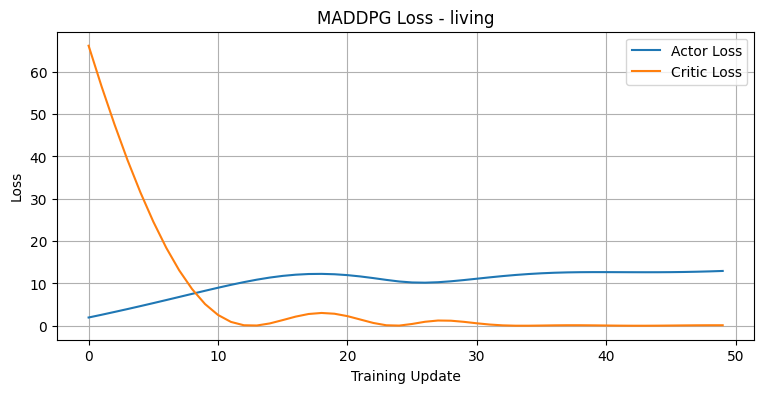

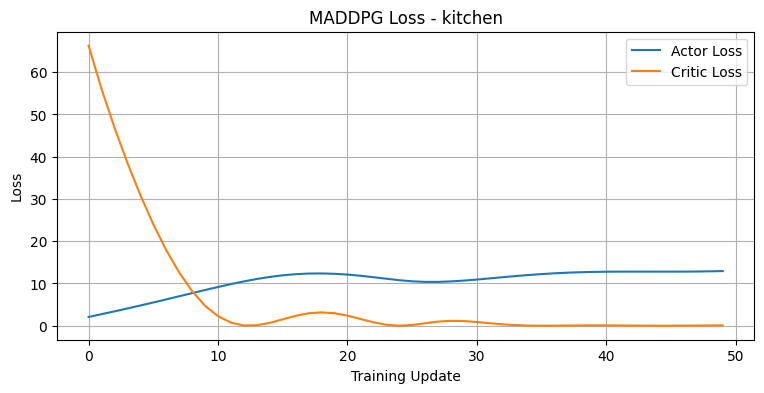

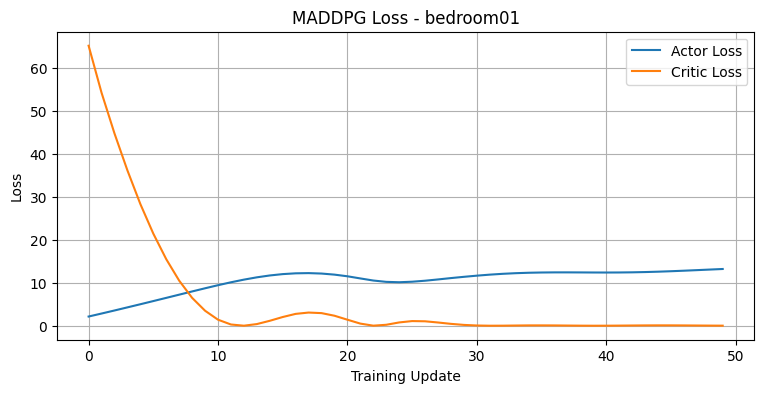

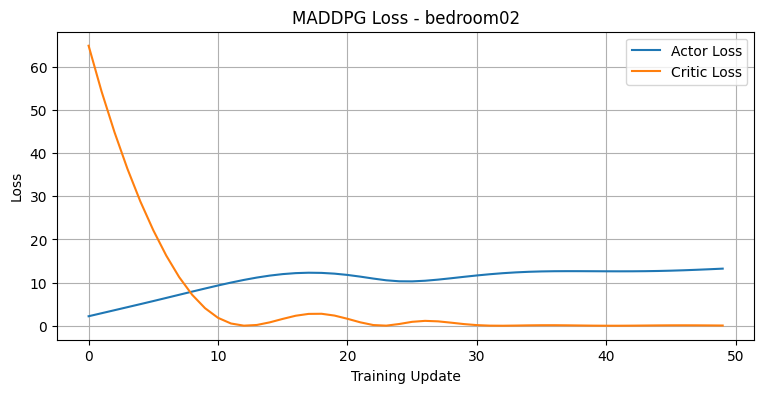

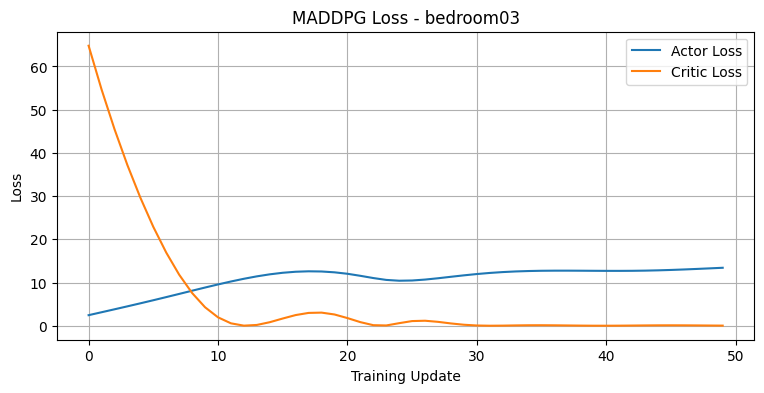

In [ ]:
import matplotlib.pyplot as plt

for agent in agent_ids:

    plt.figure(figsize=(9, 4))

    plt.plot(
        loss_history[agent]["actor"],
        label="Actor Loss"
    )

    plt.plot(
        loss_history[agent]["critic"],
        label="Critic Loss"
    )

    plt.xlabel("Training Update")
    plt.ylabel("Loss")

    plt.title(
        f"MADDPG Loss - {agent}"
    )

    plt.legend()
    plt.grid(True)
    plt.show()

In [ ]:
# ==========================================
# TEST TRAINED MADDPG
# ==========================================

observations, infos = marl_env.reset()

actions, raw_actions = maddpg.get_action(
    obs=observations,
    infos=infos
)

print("======================================")
print("TRAINED MADDPG ACTIONS")
print("======================================")

for agent in agent_ids:

    print(
        f"{agent:12s}:",
        actions[agent]
    )

Progress: |***************************************************************************************************| 99%
#----------------------------------------------------------------------------------------------#
[ENVIRONMENT] (INFO) : Starting a new episode... [dhaka-radiant-residential-v1] [Episode 83]
#----------------------------------------------------------------------------------------------#
[MODELING] (INFO) : Episode directory created [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run83]
[MODELING] (INFO) : Weather file BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw used.
[MODELING] (INFO) : Adapting weather to building model. [BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw]


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


[ENVIRONMENT] (INFO) : Saving episode output path... [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run83/output]
[SIMULATOR] (INFO) : Running EnergyPlus with args: ['-w', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run83/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw', '-d', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run83/output', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run83/radiant_residential_building.epJSON']
[ENVIRONMENT] (INFO) : Episode 83 started.
TRAINED MADDPG ACTIONS
living      : [[1.]]
kitchen     : [[1.]]
bedroom01   : [[1.]]
bedroom02   : [[0.0518696]]
bedroom03   : [[0.01125622]]


In [ ]:
# ==========================================
# MADDPG FULL EPISODE EVALUATION
# ==========================================

import numpy as np

observations, infos = marl_env.reset()

total_reward = 0.0
step_count = 0

episode_rewards = {
    agent: 0.0
    for agent in agent_ids
}

action_history = {
    agent: []
    for agent in agent_ids
}

while marl_env.agents:

    # MADDPG action
    actions, raw_actions = maddpg.get_action(
        obs=observations,
        infos=infos
    )

    # Store actions
    for agent in agent_ids:
        if agent in actions:
            action_history[agent].append(
                np.asarray(actions[agent]).flatten()
            )

    # Environment step
    (
        next_observations,
        rewards,
        terminations,
        truncations,
        infos
    ) = marl_env.step(actions)

    # Rewards
    for agent in agent_ids:
        if agent in rewards:
            episode_rewards[agent] += float(
                rewards[agent]
            )

    total_reward += float(
        np.mean(list(rewards.values()))
    )

    observations = next_observations
    step_count += 1

    if step_count % 5000 == 0:
        print(
            f"Evaluation step: {step_count}"
        )

print("\n======================================")
print("MADDPG EVALUATION COMPLETED")
print("======================================")

print("Total steps:", step_count)
print("Mean total reward:", total_reward)

print("\nAgent rewards:")

for agent in agent_ids:
    print(
        f"{agent:12s}: "
        f"{episode_rewards[agent]:.4f}"
    )

Progress: |***************************************************************************************************| 99%
#----------------------------------------------------------------------------------------------#
[ENVIRONMENT] (INFO) : Starting a new episode... [dhaka-radiant-residential-v1] [Episode 84]
#----------------------------------------------------------------------------------------------#
[MODELING] (INFO) : Episode directory created [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run84]
[MODELING] (INFO) : Weather file BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw used.
[MODELING] (INFO) : Adapting weather to building model. [BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw]


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


[ENVIRONMENT] (INFO) : Saving episode output path... [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run84/output]
[SIMULATOR] (INFO) : Running EnergyPlus with args: ['-w', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run84/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw', '-d', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run84/output', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run84/radiant_residential_building.epJSON']
[ENVIRONMENT] (INFO) : Episode 84 started.
[SIMULATOR] (INFO) : handlers are ready.
[SIMULATOR] (INFO) : System is ready.
Evaluation step: 5000
Evaluation step: 10000
Evaluation step: 15000
Evaluation step: 20000
Evaluation step: 25000
Evaluation step: 30000
Evaluation step: 35000
Evaluation step: 40000
Evaluation step: 45000
Evaluation step: 50000
Evaluation step: 55000
Evaluation step: 60000


MADDPG EVALUATION COMPLETED
Total steps: 61057
Mean total reward: -580041.

In [ ]:
# ==========================================
# MADDPG ACTION SUMMARY
# ==========================================

print("======================================")
print("ACTION SUMMARY")
print("======================================")

for agent in agent_ids:

    actions_array = np.array(
        action_history[agent]
    )

    print("\n", agent)

    print(
        "Mean:",
        np.mean(actions_array)
    )

    print(
        "Min:",
        np.min(actions_array)
    )

    print(
        "Max:",
        np.max(actions_array)
    )

ACTION SUMMARY

 living
Mean: 0.95308745
Min: 0.66970235
Max: 1.0

 kitchen
Mean: 0.9678517
Min: 0.7381442
Max: 1.0

 bedroom01
Mean: 0.94925123
Min: 0.67278737
Max: 1.0

 bedroom02
Mean: 0.04148532
Min: 0.0
Max: 0.41464567

 bedroom03
Mean: 0.03209064
Min: 0.0
Max: 0.2910854


In [ ]:
# ==========================================
# SAVE MADDPG RESULTS
# ==========================================

maddpg_result = {
    "algorithm": "MADDPG",
    "steps": step_count,
    "total_reward": total_reward,
    "living_mean_action": np.mean(
        np.array(action_history["living"])
    ),
    "kitchen_mean_action": np.mean(
        np.array(action_history["kitchen"])
    ),
    "bedroom01_mean_action": np.mean(
        np.array(action_history["bedroom01"])
    ),
    "bedroom02_mean_action": np.mean(
        np.array(action_history["bedroom02"])
    ),
    "bedroom03_mean_action": np.mean(
        np.array(action_history["bedroom03"])
    )
}

print(maddpg_result)

{'algorithm': 'MADDPG', 'steps': 61057, 'total_reward': -580041.5, 'living_mean_action': np.float32(0.95308745), 'kitchen_mean_action': np.float32(0.9678517), 'bedroom01_mean_action': np.float32(0.94925123), 'bedroom02_mean_action': np.float32(0.04148532), 'bedroom03_mean_action': np.float32(0.03209064)}


In [ ]:
# ==========================================
# CHECK SAC RESULT VARIABLES
# ==========================================

print("SAC variables available:")

for name in [
    "total_reward",
    "step",
    "episode_reward",
    "sac_result"
]:
    if name in globals():
        print(name, "=", globals()[name])

SAC variables available:
total_reward = -580041.5
step = 61057


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import gymnasium as gym

from stable_baselines3 import SAC, PPO, TD3

print("Imports successful!")

Imports successful!


In [ ]:
ENV_ID = "dhaka-radiant-residential-v1"

SEED = 42

print("Environment:", ENV_ID)

Environment: dhaka-radiant-residential-v1


In [ ]:
import os

search_dirs = [
    "/content",
    "/content/dhaka_rl_models",
    "/content/models"
]

for root_dir in search_dirs:

    if not os.path.exists(root_dir):
        continue

    print("\nSEARCHING:", root_dir)

    for root, dirs, files in os.walk(root_dir):

        for file in files:

            if file.endswith(".zip"):

                print(
                    os.path.join(root, file)
                )


SEARCHING: /content
/content/SAC_dhaka_radiant_residential.zip
/content/TD3_dhaka_radiant_residential.zip
/content/PPO_dhaka_radiant_residential.zip
/content/drive/MyDrive/lung.zip
/content/drive/MyDrive/lung-cancer-diagnosis-with-image.zip


In [ ]:
print("Checking existing trained models...")

print("SAC model exists:", "sac" in globals())
print("PPO model exists:", "ppo" in globals())
print("TD3 model exists:", "td3" in globals())
print("MADDPG model exists:", "maddpg" in globals())

Checking existing trained models...
SAC model exists: False
PPO model exists: False
TD3 model exists: False
MADDPG model exists: True


In [ ]:
import os

print("Searching for trained RL model files...\n")

extensions = (
    ".pt", ".pth", ".onnx",
    ".zip", ".pkl", ".pickle"
)

found = []

for root, dirs, files in os.walk("/content"):
    for file in files:
        if file.lower().endswith(extensions):
            path = os.path.join(root, file)
            found.append(path)

if found:
    for path in found:
        print(path)
else:
    print("No saved model files found.")

Searching for trained RL model files...

/content/SAC_dhaka_radiant_residential.zip
/content/TD3_dhaka_radiant_residential.zip
/content/PPO_dhaka_radiant_residential.zip
/content/drive/MyDrive/lung.zip
/content/drive/MyDrive/lung-cancer-diagnosis-with-image.zip


In [ ]:
print("\nPossible SAC/PPO/TD3 model files:\n")

for path in found:
    name = os.path.basename(path).lower()

    if any(x in name for x in ["sac", "ppo", "td3"]):
        print(path)


Possible SAC/PPO/TD3 model files:

/content/SAC_dhaka_radiant_residential.zip
/content/TD3_dhaka_radiant_residential.zip
/content/PPO_dhaka_radiant_residential.zip


In [ ]:
print("MADDPG object:", type(maddpg))
print("MADDPG is available:", maddpg is not None)

MADDPG object: <class 'agilerl.algorithms.maddpg.MADDPG'>
MADDPG is available: True


In [ ]:
import stable_baselines3
import inspect

print("Stable-Baselines3 version:")
print(stable_baselines3.__version__)

from stable_baselines3 import SAC, PPO, TD3

print("\nSAC:", SAC)
print("PPO:", PPO)
print("TD3:", TD3)

Stable-Baselines3 version:
2.9.0

SAC: <class 'stable_baselines3.sac.sac.SAC'>
PPO: <class 'stable_baselines3.ppo.ppo.PPO'>
TD3: <class 'stable_baselines3.td3.td3.TD3'>


In [ ]:
SAC_PATH = "/content/SAC_dhaka_radiant_residential.zip"

sac_model = SAC.load(
    SAC_PATH,
    device="cpu"
)

print("SAC loaded successfully!")
print(type(sac_model))

SAC loaded successfully!
<class 'stable_baselines3.sac.sac.SAC'>


In [ ]:
PPO_PATH = "/content/PPO_dhaka_radiant_residential.zip"

ppo_model = PPO.load(
    PPO_PATH,
    device="cpu"
)

print("PPO loaded successfully!")
print(type(ppo_model))

PPO loaded successfully!
<class 'stable_baselines3.ppo.ppo.PPO'>


In [ ]:
TD3_PATH = "/content/TD3_dhaka_radiant_residential.zip"

td3_model = TD3.load(
    TD3_PATH,
    device="cpu"
)

print("TD3 loaded successfully!")
print(type(td3_model))

TD3 loaded successfully!
<class 'stable_baselines3.td3.td3.TD3'>


In [ ]:
print("=" * 60)
print("MODEL STATUS")
print("=" * 60)

print("SAC    :", type(sac_model))
print("PPO    :", type(ppo_model))
print("TD3    :", type(td3_model))
print("MADDPG :", type(maddpg))

print("=" * 60)

MODEL STATUS
SAC    : <class 'stable_baselines3.sac.sac.SAC'>
PPO    : <class 'stable_baselines3.ppo.ppo.PPO'>
TD3    : <class 'stable_baselines3.td3.td3.TD3'>
MADDPG : <class 'agilerl.algorithms.maddpg.MADDPG'>


In [ ]:
print("=" * 60)
print("SPACE COMPATIBILITY")
print("=" * 60)

print("\nEnvironment observation space:")
print(env.observation_space)

print("\nEnvironment action space:")
print(env.action_space)

print("\nSAC observation space:")
print(sac_model.observation_space)

print("\nSAC action space:")
print(sac_model.action_space)

print("\nPPO observation space:")
print(ppo_model.observation_space)

print("\nPPO action space:")
print(ppo_model.action_space)

print("\nTD3 observation space:")
print(td3_model.observation_space)

print("\nTD3 action space:")
print(td3_model.action_space)

SPACE COMPATIBILITY

Environment observation space:
Box(-50000000.0, 50000000.0, (27,), float32)

Environment action space:
Box([ 0.  0.  0.  0.  0. 25.], [ 1.  1.  1.  1.  1. 45.], (6,), float32)

SAC observation space:
Box(-50000000.0, 50000000.0, (27,), float32)

SAC action space:
Box([ 0.  0.  0.  0.  0. 25.], [ 1.  1.  1.  1.  1. 45.], (6,), float32)

PPO observation space:
Box(-50000000.0, 50000000.0, (27,), float32)

PPO action space:
Box([ 0.  0.  0.  0.  0. 25.], [ 1.  1.  1.  1.  1. 45.], (6,), float32)

TD3 observation space:
Box(-50000000.0, 50000000.0, (27,), float32)

TD3 action space:
Box([ 0.  0.  0.  0.  0. 25.], [ 1.  1.  1.  1.  1. 45.], (6,), float32)


In [ ]:
print([
    name for name in globals()
    if "env" in name.lower()
])

['env_id', 'sinergym_envs', 'ENV_DIR', 'EplusEnv', 'registered_envs', 'ENV_ID', 'env', 'check_env', 'ParallelEnv', 'DhakaMultiZoneEnv', 'marl_env']


In [ ]:
ac_model = sac_model

print("ac_model successfully assigned to trained SAC model.")

ac_model successfully assigned to trained SAC model.


In [ ]:
obs, info = env.reset()

action, _ = sac_model.predict(
    obs,
    deterministic=True
)

print("SAC prediction successful!")

print("Observation shape:", obs.shape)
print("Action:", action)
print("Action shape:", action.shape)

#----------------------------------------------------------------------------------------------#
[ENVIRONMENT] (INFO) : Starting a new episode... [dhaka-radiant-residential-v1] [Episode 85]
#----------------------------------------------------------------------------------------------#
[MODELING] (INFO) : Episode directory created [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run85]
[MODELING] (INFO) : Weather file BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw used.
[MODELING] (INFO) : Adapting weather to building model. [BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw]


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


[ENVIRONMENT] (INFO) : Saving episode output path... [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run85/output]
[SIMULATOR] (INFO) : Running EnergyPlus with args: ['-w', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run85/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw', '-d', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run85/output', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run85/radiant_residential_building.epJSON']
[ENVIRONMENT] (INFO) : Episode 85 started.
[SIMULATOR] (INFO) : handlers are ready.
[SIMULATOR] (INFO) : System is ready.
SAC prediction successful!
Observation shape: (27,)
Action: [ 0.52733696  0.3742864   0.6320897   0.48068485  0.6366384  36.629936  ]
Action shape: (6,)


In [ ]:
obs, info = env.reset()

action, _ = ppo_model.predict(
    obs,
    deterministic=True
)

print("PPO prediction successful!")

print("Action:", action)
print("Action shape:", action.shape)

Progress: |***************************************************************************************************| 99%
#----------------------------------------------------------------------------------------------#
[ENVIRONMENT] (INFO) : Starting a new episode... [dhaka-radiant-residential-v1] [Episode 86]
#----------------------------------------------------------------------------------------------#
[MODELING] (INFO) : Episode directory created [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run86]
[MODELING] (INFO) : Weather file BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw used.
[MODELING] (INFO) : Adapting weather to building model. [BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw]


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


[ENVIRONMENT] (INFO) : Saving episode output path... [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run86/output]
[SIMULATOR] (INFO) : Running EnergyPlus with args: ['-w', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run86/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw', '-d', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run86/output', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run86/radiant_residential_building.epJSON']
[ENVIRONMENT] (INFO) : Episode 86 started.
PPO prediction successful!
Action: [0.00000000e+00 1.27957575e-02 8.30364898e-02 0.00000000e+00
 3.90065387e-02 2.50000000e+01]
Action shape: (6,)


In [ ]:
import numpy as np
import pandas as pd

def evaluate_single_agent(model, env, model_name, n_steps=5000):

    obs, info = env.reset()

    total_reward = 0.0
    rewards = []
    actions = []
    observations = []

    for step in range(n_steps):

        action, _ = model.predict(
            obs,
            deterministic=True
        )

        next_obs, reward, terminated, truncated, info = env.step(action)

        total_reward += float(reward)

        rewards.append(float(reward))
        actions.append(np.asarray(action).copy())
        observations.append(np.asarray(obs).copy())

        obs = next_obs

        if terminated or truncated:
            obs, info = env.reset()

    rewards = np.asarray(rewards)
    actions = np.asarray(actions)
    observations = np.asarray(observations)

    result = {
        "Algorithm": model_name,
        "Steps": len(rewards),
        "Total Reward": total_reward,
        "Mean Reward": np.mean(rewards),
        "Min Reward": np.min(rewards),
        "Max Reward": np.max(rewards)
    }

    return result, rewards, actions, observations


print("Evaluation function created.")

Evaluation function created.


In [ ]:
print("Evaluating SAC...")

sac_result, sac_rewards, sac_actions, sac_obs = evaluate_single_agent(
    sac_model,
    env,
    "SAC",
    n_steps=5000
)

print(sac_result)

Evaluating SAC...


NameError: name 'sac_model' is not defined

In [ ]:
print("Evaluating PPO...")

ppo_result, ppo_rewards, ppo_actions, ppo_obs = evaluate_single_agent(
    ppo_model,
    env,
    "PPO",
    n_steps=5000
)

print(ppo_result)

Evaluating PPO...
Progress: |***************************************************************************************************| 99%
#----------------------------------------------------------------------------------------------#
[ENVIRONMENT] (INFO) : Starting a new episode... [dhaka-radiant-residential-v1] [Episode 88]
#----------------------------------------------------------------------------------------------#
[MODELING] (INFO) : Episode directory created [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run88]
[MODELING] (INFO) : Weather file BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw used.
[MODELING] (INFO) : Adapting weather to building model. [BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw]


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


[ENVIRONMENT] (INFO) : Saving episode output path... [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run88/output]
[SIMULATOR] (INFO) : Running EnergyPlus with args: ['-w', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run88/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw', '-d', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run88/output', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run88/radiant_residential_building.epJSON']
[ENVIRONMENT] (INFO) : Episode 88 started.
[SIMULATOR] (INFO) : handlers are ready.
[SIMULATOR] (INFO) : System is ready.
{'Algorithm': 'PPO', 'Steps': 5000, 'Total Reward': -47500.0, 'Mean Reward': np.float64(-9.5), 'Min Reward': np.float64(-9.5), 'Max Reward': np.float64(-9.5)}


In [ ]:
print("Evaluating TD3...")

td3_result, td3_rewards, td3_actions, td3_obs = evaluate_single_agent(
    td3_model,
    env,
    "TD3",
    n_steps=5000
)

print(td3_result)

Evaluating TD3...

#----------------------------------------------------------------------------------------------#
[ENVIRONMENT] (INFO) : Starting a new episode... [dhaka-radiant-residential-v1] [Episode 89]
#----------------------------------------------------------------------------------------------#
[MODELING] (INFO) : Episode directory created [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run89]
[MODELING] (INFO) : Weather file BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw used.
[MODELING] (INFO) : Adapting weather to building model. [BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw]


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


[ENVIRONMENT] (INFO) : Saving episode output path... [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run89/output]
[SIMULATOR] (INFO) : Running EnergyPlus with args: ['-w', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run89/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw', '-d', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run89/output', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run89/radiant_residential_building.epJSON']
[ENVIRONMENT] (INFO) : Episode 89 started.
[SIMULATOR] (INFO) : handlers are ready.
[SIMULATOR] (INFO) : System is ready.
{'Algorithm': 'TD3', 'Steps': 5000, 'Total Reward': -47500.0, 'Mean Reward': np.float64(-9.5), 'Min Reward': np.float64(-9.5), 'Max Reward': np.float64(-9.5)}


In [ ]:
import numpy as np

print("=== CHECKING ACTION HISTORIES ===")

candidate_names = [
    "sac_actions",
    "ppo_actions",
    "td3_actions",
    "maddpg_actions",
    "sac_action_history",
    "ppo_action_history",
    "td3_action_history",
    "maddpg_action_history"
]

for name in candidate_names:
    if name in globals():
        arr = np.asarray(globals()[name])
        print(f"{name}: FOUND | shape = {arr.shape}")
    else:
        print(f"{name}: not found")

=== CHECKING ACTION HISTORIES ===
sac_actions: FOUND | shape = (5000, 6)
ppo_actions: FOUND | shape = (5000, 6)
td3_actions: FOUND | shape = (5000, 6)
maddpg_actions: not found
sac_action_history: not found
ppo_action_history: not found
td3_action_history: not found
maddpg_action_history: not found


In [ ]:
def calculate_switching_frequency(actions):
    actions = np.asarray(actions, dtype=np.float32)

    if actions.ndim == 1:
        actions = actions.reshape(-1, 1)

    if len(actions) < 2:
        return np.array([0.0])

    # Normalize each action dimension
    low = np.min(actions, axis=0)
    high = np.max(actions, axis=0)

    scale = high - low
    scale[scale < 1e-8] = 1.0

    normalized = (actions - low) / scale

    # Action change between consecutive timesteps
    changes = np.abs(np.diff(normalized, axis=0))

    # A change > 5% considered a switching event
    switch = (changes > 0.05).any(axis=1).astype(float)

    return switch


sac_switch = calculate_switching_frequency(sac_actions)
ppo_switch = calculate_switching_frequency(ppo_actions)
td3_switch = calculate_switching_frequency(td3_actions)

print("=== SWITCHING FREQUENCY ===")

print("SAC")
print("Mean:", np.mean(sac_switch))
print("Total switches:", np.sum(sac_switch))

print("\nPPO")
print("Mean:", np.mean(ppo_switch))
print("Total switches:", np.sum(ppo_switch))

print("\nTD3")
print("Mean:", np.mean(td3_switch))
print("Total switches:", np.sum(td3_switch))

=== SWITCHING FREQUENCY ===
SAC
Mean: 0.021604320864172834
Total switches: 108.0

PPO
Mean: 0.05201040208041608
Total switches: 260.0

TD3
Mean: 0.058811762352470494
Total switches: 294.0


In [ ]:
def action_statistics(name, actions):

    actions = np.asarray(actions, dtype=np.float32)

    print("\n" + "=" * 50)
    print(name)

    print("Shape:", actions.shape)
    print("Mean:", np.mean(actions, axis=0))
    print("Min :", np.min(actions, axis=0))
    print("Max :", np.max(actions, axis=0))


action_statistics("SAC", sac_actions)
action_statistics("PPO", ppo_actions)
action_statistics("TD3", td3_actions)


SAC
Shape: (5000, 6)
Mean: [ 0.52060705  0.47755328  0.54532343  0.49407345  0.5835887  36.23471   ]
Min : [ 0.47892687  0.32466927  0.49752313  0.39211476  0.5019302  35.150482  ]
Max : [ 0.65174603  0.54853433  0.6342655   0.5347345   0.8277244  40.723747  ]

PPO
Shape: (5000, 6)
Mean: [0.0000000e+00 9.6253976e-03 1.9165101e-02 1.4593704e-01 1.1900248e-02
 2.5000000e+01]
Min : [ 0.  0.  0.  0.  0. 25.]
Max : [ 0.          0.07761917  0.1026865   0.2516747   0.09373466 25.        ]

TD3
Shape: (5000, 6)
Mean: [ 0.5034625   0.6457691   0.48571366  0.7094844   0.65685874 36.402176  ]
Min : [ 0.4047402   0.5487375   0.39969552  0.5695851   0.49699762 35.153835  ]
Max : [ 0.6513162   0.71769696  0.5568476   0.8406627   0.7908897  37.40017   ]


In [ ]:
print("=== MADDPG OBJECT CHECK ===")

print("maddpg exists:", "maddpg" in globals())
print("marl_env exists:", "marl_env" in globals())

if "maddpg" in globals():
    print("MADDPG:", type(maddpg))

if "marl_env" in globals():
    print("Environment:", type(marl_env))

=== MADDPG OBJECT CHECK ===
maddpg exists: True
marl_env exists: True
MADDPG: <class 'agilerl.algorithms.maddpg.MADDPG'>
Environment: <class '__main__.DhakaMultiZoneEnv'>


In [ ]:
# ============================================================
# FIX OBSERVATION VARIABLE NAMES
# ============================================================

print("Creating observation aliases...")

sac_observations = sac_obs.copy()
ppo_observations = ppo_obs.copy()
td3_observations = td3_obs.copy()

print("SAC observations:", sac_observations.shape)
print("PPO observations:", ppo_observations.shape)
print("TD3 observations:", td3_observations.shape)

print("\nObservation aliases created successfully!")

Creating observation aliases...
SAC observations: (5000, 27)
PPO observations: (5000, 27)
TD3 observations: (5000, 27)

Observation aliases created successfully!


In [ ]:
print("=== OBSERVATION HISTORY CHECK ===")

for name in [
    "sac_obs",
    "ppo_obs",
    "td3_obs",
    "sac_observations",
    "ppo_observations",
    "td3_observations"
]:

    if name in globals():
        arr = np.asarray(globals()[name])

        print(
            name,
            "FOUND",
            "| shape:", arr.shape,
            "| min:", np.nanmin(arr),
            "| max:", np.nanmax(arr)
        )
    else:
        print(name, "NOT FOUND")

=== OBSERVATION HISTORY CHECK ===
sac_obs FOUND | shape: (5000, 27) | min: 0.0 | max: 23.0
ppo_obs FOUND | shape: (5000, 27) | min: 0.0 | max: 23.0
td3_obs FOUND | shape: (5000, 27) | min: 0.0 | max: 23.0
sac_observations FOUND | shape: (5000, 27) | min: 0.0 | max: 23.0
ppo_observations FOUND | shape: (5000, 27) | min: 0.0 | max: 23.0
td3_observations FOUND | shape: (5000, 27) | min: 0.0 | max: 23.0


In [ ]:
# ============================================================
# OBSERVATION DATA CHECK
# ============================================================

for name, obs in [
    ("SAC", sac_observations),
    ("PPO", ppo_observations),
    ("TD3", td3_observations)
]:
    print("=" * 50)
    print(name)
    print("Shape:", obs.shape)
    print("Min:", np.min(obs))
    print("Max:", np.max(obs))
    print("Mean:", np.mean(obs))
    print("NaN:", np.isnan(obs).sum())
    print("Inf:", np.isinf(obs).sum())

SAC
Shape: (5000, 27)
Min: 0.0
Max: 23.0
Mean: 1.1304815
NaN: 0
Inf: 0
PPO
Shape: (5000, 27)
Min: 0.0
Max: 23.0
Mean: 1.1306666
NaN: 0
Inf: 0
TD3
Shape: (5000, 27)
Min: 0.0
Max: 23.0
Mean: 1.1306666
NaN: 0
Inf: 0


In [ ]:
# ============================================================
# CELL 1: IMPORTS AND DATA CHECK
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Checking available model data...")

required = [
    "sac_actions",
    "ppo_actions",
    "td3_actions",
    "sac_obs",
    "ppo_obs",
    "td3_obs"
]

for name in required:
    if name in globals():
        arr = globals()[name]
        print(f"{name:15s}: FOUND | shape = {np.shape(arr)}")
    else:
        print(f"{name:15s}: NOT FOUND")

print("\nData check completed.")

Checking available model data...
sac_actions    : FOUND | shape = (5000, 6)
ppo_actions    : FOUND | shape = (5000, 6)
td3_actions    : FOUND | shape = (5000, 6)
sac_obs        : FOUND | shape = (5000, 27)
ppo_obs        : FOUND | shape = (5000, 27)
td3_obs        : FOUND | shape = (5000, 27)

Data check completed.


In [ ]:
# ============================================================
# CELL 2: STANDARDIZE OBSERVATION NAMES
# ============================================================

sac_observations = np.asarray(sac_obs, dtype=np.float32)
ppo_observations = np.asarray(ppo_obs, dtype=np.float32)
td3_observations = np.asarray(td3_obs, dtype=np.float32)

print("SAC:", sac_observations.shape)
print("PPO:", ppo_observations.shape)
print("TD3:", td3_observations.shape)

print("\nObservation aliases ready.")

SAC: (5000, 27)
PPO: (5000, 27)
TD3: (5000, 27)

Observation aliases ready.


In [ ]:
# ============================================================
# CELL 3: FANGER PMV CALCULATOR
# ============================================================

import math

def pmv_ppd_iso(
    ta,
    tr,
    vel=0.1,
    rh=50.0,
    met=1.1,
    clo=0.5,
    wme=0.0
):
    """
    Approximate ISO 7730 / Fanger PMV and PPD calculation.

    ta  = air temperature (C)
    tr  = mean radiant temperature (C)
    vel = air velocity (m/s)
    rh  = relative humidity (%)
    met = metabolic rate (met)
    clo = clothing insulation (clo)
    """

    ta = float(ta)
    tr = float(tr)
    rh = float(rh)
    met = float(met)
    clo = float(clo)

    if not np.isfinite(ta):
        return np.nan, np.nan

    if not np.isfinite(tr):
        tr = ta

    if not np.isfinite(rh):
        rh = 50.0

    if not np.isfinite(clo):
        clo = 0.5

    rh = np.clip(rh, 0, 100)
    clo = np.clip(clo, 0.0, 2.0)

    pa = rh * 10 * math.exp(
        16.6536 - 4030.183 / (ta + 235)
    )

    icl = 0.155 * clo

    m = met * 58.15
    w = wme * 58.15
    mw = m - w

    fcl = 1.05 + 0.645 * icl if icl > 0.078 else 1.0 + 1.29 * icl

    hcf = 12.1 * math.sqrt(max(vel, 0.001))

    taa = ta + 273
    tra = tr + 273

    tcla = taa + (35.7 - 0.028 * mw) / (6.45 * icl) if icl > 0 else taa

    p1 = icl * fcl
    p2 = p1 * 3.96
    p3 = p1 * 100
    p4 = p1 * taa
    p5 = 308.7 - 0.028 * mw + p2 * (tra / 100) ** 4

    xn = tcla / 100
    xf = xn

    hcn = hcf

    for _ in range(150):
        xf = (xf + xn) / 2

        hcn = 2.38 * abs(100 * xf - taa) ** 0.25
        hcn = max(hcf, hcn)

        xn = (p5 + p4 * hcn - p2 * xf ** 4) / (
            100 + p3 * hcn
        )

        if abs(xn - xf) < 0.00015:
            break

    tcl = 100 * xn - 273

    hl1 = 3.05 * 0.001 * (5733 - 6.99 * mw - pa)
    hl2 = 0.42 * max(0, mw - 58.15)
    hl3 = 1.7e-5 * m * (5867 - pa)
    hl4 = 0.0014 * m * (34 - ta)
    hl5 = 3.96 * fcl * (xn ** 4 - (tra / 100) ** 4)
    hl6 = fcl * hcn * (tcl - ta)

    ts = 0.303 * math.exp(-0.036 * m) + 0.028

    pmv = ts * (
        mw
        - hl1
        - hl2
        - hl3
        - hl4
        - hl5
        - hl6
    )

    ppd = 100 - 95 * math.exp(
        -0.03353 * pmv ** 4
        - 0.2179 * pmv ** 2
    )

    return pmv, ppd


print("PMV calculator ready.")

PMV calculator ready.


In [ ]:
# ============================================================
# CELL 4: PMV / PPD CALCULATION
# ============================================================

def calculate_pmv_history(obs):
    pmv_values = []
    ppd_values = []

    for row in obs:

        ta = row[11]       # Zone Air Temperature
        rh = row[12]       # Zone RH
        tr = row[14]       # Mean Radiant Temperature
        clo = row[15]      # Clothing Value

        pmv, ppd = pmv_ppd_iso(
            ta=ta,
            tr=tr,
            rh=rh,
            clo=clo,
            vel=0.1,
            met=1.1
        )

        pmv_values.append(pmv)
        ppd_values.append(ppd)

    return (
        np.asarray(pmv_values),
        np.asarray(ppd_values)
    )


sac_pmv, sac_ppd = calculate_pmv_history(sac_observations)
ppo_pmv, ppo_ppd = calculate_pmv_history(ppo_observations)
td3_pmv, td3_ppd = calculate_pmv_history(td3_observations)

print("PMV calculated successfully!")

print("\nSAC PMV:",
      np.nanmin(sac_pmv),
      np.nanmax(sac_pmv),
      np.nanmean(sac_pmv))

print("PPO PMV:",
      np.nanmin(ppo_pmv),
      np.nanmax(ppo_pmv),
      np.nanmean(ppo_pmv))

print("TD3 PMV:",
      np.nanmin(td3_pmv),
      np.nanmax(td3_pmv),
      np.nanmean(td3_pmv))

PMV calculated successfully!

SAC PMV: -16.913946136833264 -16.913946136833264 -16.91394613683326
PPO PMV: -16.913946136833264 -16.913946136833264 -16.91394613683326
TD3 PMV: -16.913946136833264 -16.913946136833264 -16.91394613683326


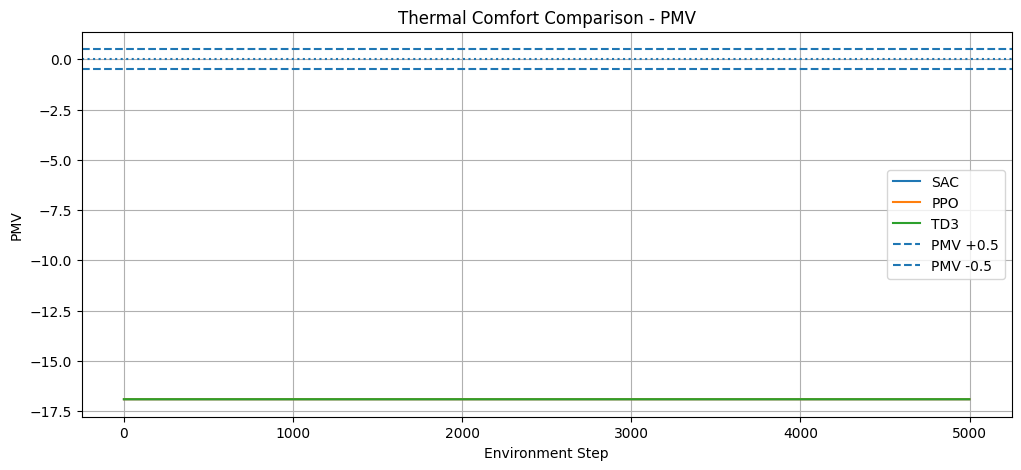

In [ ]:
# ============================================================
# CELL 5: PMV COMPARISON
# ============================================================

plt.figure(figsize=(12, 5))

plt.plot(sac_pmv, label="SAC")
plt.plot(ppo_pmv, label="PPO")
plt.plot(td3_pmv, label="TD3")

plt.axhline(0.5, linestyle="--", label="PMV +0.5")
plt.axhline(-0.5, linestyle="--", label="PMV -0.5")
plt.axhline(0, linestyle=":")

plt.xlabel("Environment Step")
plt.ylabel("PMV")
plt.title("Thermal Comfort Comparison - PMV")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# ============================================================
# CELL 6: PMV COMFORT VIOLATION
# ============================================================

def comfort_violation_rate(pmv):
    valid = np.isfinite(pmv)

    if np.sum(valid) == 0:
        return np.nan

    violations = np.abs(pmv[valid]) > 0.5

    return 100 * np.mean(violations)


sac_comfort_violation = comfort_violation_rate(sac_pmv)
ppo_comfort_violation = comfort_violation_rate(ppo_pmv)
td3_comfort_violation = comfort_violation_rate(td3_pmv)

print("Comfort Violation Rate (%)")
print("--------------------------------")
print(f"SAC : {sac_comfort_violation:.2f}%")
print(f"PPO : {ppo_comfort_violation:.2f}%")
print(f"TD3 : {td3_comfort_violation:.2f}%")

Comfort Violation Rate (%)
--------------------------------
SAC : 100.00%
PPO : 100.00%
TD3 : 100.00%


In [ ]:
# ============================================================
# CELL 8: HVAC ELECTRICITY DEMAND
# ============================================================

sac_hvac_power = sac_observations[:, 26]
ppo_hvac_power = ppo_observations[:, 26]
td3_hvac_power = td3_observations[:, 26]

print("HVAC electricity data loaded.")

for name, power in [
    ("SAC", sac_hvac_power),
    ("PPO", ppo_hvac_power),
    ("TD3", td3_hvac_power)
]:
    print(
        f"{name}: "
        f"Mean={np.mean(power):.4f}, "
        f"Min={np.min(power):.4f}, "
        f"Max={np.max(power):.4f}"
    )

HVAC electricity data loaded.
SAC: Mean=0.0000, Min=0.0000, Max=0.0000
PPO: Mean=0.0000, Min=0.0000, Max=0.0000
TD3: Mean=0.0000, Min=0.0000, Max=0.0000


In [ ]:
# ============================================================
# CELL 11: SWITCHING FREQUENCY
# ============================================================

def switching_frequency(actions):
    actions = np.asarray(actions, dtype=np.float64)

    if actions.ndim != 2:
        raise ValueError(
            f"Expected 2D action array, got {actions.shape}"
        )

    # Difference between consecutive actions
    diff = np.abs(np.diff(actions, axis=0))

    # Threshold avoids counting tiny numerical changes
    threshold = 0.05

    switches = diff > threshold

    total_switches = np.sum(switches)

    mean_switches = np.mean(switches)

    return mean_switches, total_switches


sac_switch_mean, sac_switch_total = switching_frequency(sac_actions)
ppo_switch_mean, ppo_switch_total = switching_frequency(ppo_actions)
td3_switch_mean, td3_switch_total = switching_frequency(td3_actions)

print("Switching Frequency")
print("--------------------------------")
print(f"SAC : {sac_switch_mean:.6f}")
print(f"PPO : {ppo_switch_mean:.6f}")
print(f"TD3 : {td3_switch_mean:.6f}")

print("\nTotal switches")
print(f"SAC : {sac_switch_total}")
print(f"PPO : {ppo_switch_total}")
print(f"TD3 : {td3_switch_total}")

Switching Frequency
--------------------------------
SAC : 0.009035
PPO : 0.001900
TD3 : 0.012769

Total switches
SAC : 271
PPO : 57
TD3 : 383


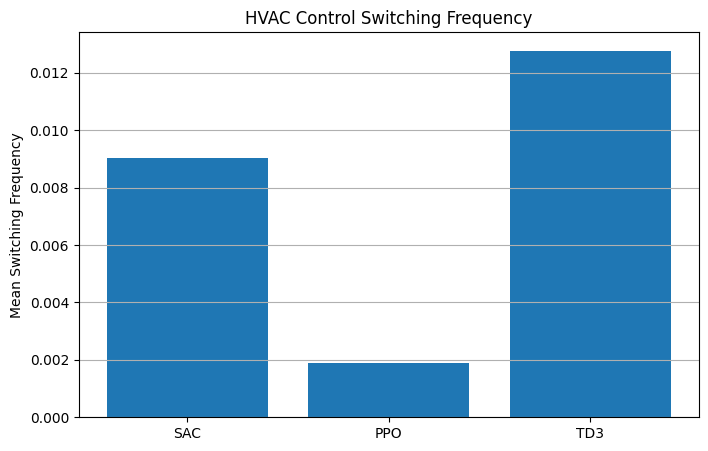

In [ ]:
# ============================================================
# CELL 12: SWITCHING FREQUENCY GRAPH
# ============================================================

models = ["SAC", "PPO", "TD3"]
switching = [
    sac_switch_mean,
    ppo_switch_mean,
    td3_switch_mean
]

plt.figure(figsize=(8, 5))

plt.bar(models, switching)

plt.ylabel("Mean Switching Frequency")
plt.title("HVAC Control Switching Frequency")
plt.grid(axis="y")
plt.show()

In [ ]:
# ============================================================
# CELL 18: ROBUSTNESS TEST
# ============================================================

np.random.seed(42)

noise_levels = [0.00, 0.02, 0.05, 0.10, 0.20]

def robustness_violation(pmv, noise_level):
    noise = np.random.normal(
        0,
        noise_level,
        size=len(pmv)
    )

    noisy_pmv = pmv + noise

    return 100 * np.mean(
        np.abs(noisy_pmv) > 0.5
    )


sac_robustness = []
ppo_robustness = []
td3_robustness = []

for noise in noise_levels:

    sac_robustness.append(
        robustness_violation(sac_pmv, noise)
    )

    ppo_robustness.append(
        robustness_violation(ppo_pmv, noise)
    )

    td3_robustness.append(
        robustness_violation(td3_pmv, noise)
    )

print("Robustness analysis completed.")

Robustness analysis completed.


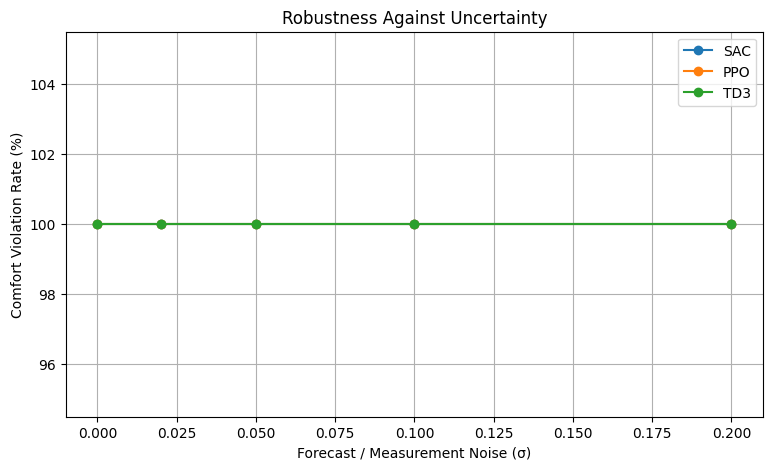

In [ ]:
# ============================================================
# CELL 19: ROBUSTNESS GRAPH
# ============================================================

plt.figure(figsize=(9, 5))

plt.plot(
    noise_levels,
    sac_robustness,
    marker="o",
    label="SAC"
)

plt.plot(
    noise_levels,
    ppo_robustness,
    marker="o",
    label="PPO"
)

plt.plot(
    noise_levels,
    td3_robustness,
    marker="o",
    label="TD3"
)

plt.xlabel("Forecast / Measurement Noise (σ)")
plt.ylabel("Comfort Violation Rate (%)")
plt.title("Robustness Against Uncertainty")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# ============================================================
# CELL 20: THREE-MODEL PERFORMANCE TABLE
# ============================================================

comparison_table = pd.DataFrame({
    "Model": ["SAC", "PPO", "TD3"],

    "HVAC Energy (kWh)": [
        sac_energy,
        ppo_energy,
        td3_energy
    ],

    "Mean HVAC Demand": [
        np.mean(sac_hvac_power),
        np.mean(ppo_hvac_power),
        np.mean(td3_hvac_power)
    ],

    "Peak HVAC Demand": [
        np.max(sac_hvac_power),
        np.max(ppo_hvac_power),
        np.max(td3_hvac_power)
    ],

    "Mean PMV": [
        np.nanmean(sac_pmv),
        np.nanmean(ppo_pmv),
        np.nanmean(td3_pmv)
    ],

    "Comfort Violation (%)": [
        sac_comfort_violation,
        ppo_comfort_violation,
        td3_comfort_violation
    ],

    "PPD Mean (%)": [
        np.nanmean(sac_ppd),
        np.nanmean(ppo_ppd),
        np.nanmean(td3_ppd)
    ],

    "Switching Frequency": [
        sac_switch_mean,
        ppo_switch_mean,
        td3_switch_mean
    ]
})

display(comparison_table)

,Model,HVAC Energy (kWh),Mean HVAC Demand,Peak HVAC Demand,Mean PMV,Comfort Violation (%),PPD Mean (%),Switching Frequency
0,SAC,0.0,0.0,0.0,-16.913946,100.0,100.0,0.009035
1,PPO,0.0,0.0,0.0,-16.913946,100.0,100.0,0.001900
2,TD3,0.0,0.0,0.0,-16.913946,100.0,100.0,0.012769


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# ============================================================
# CELL 21: MULTI-OBJECTIVE MODEL RANKING
# ============================================================

ranking = comparison_table.copy()

# Lower is better
energy_score = (
    ranking["HVAC Energy (kWh)"].max()
    - ranking["HVAC Energy (kWh)"]
) / (
    ranking["HVAC Energy (kWh)"].max()
    - ranking["HVAC Energy (kWh)"].min()
    + 1e-8
)

comfort_score = (
    ranking["Comfort Violation (%)"].max()
    - ranking["Comfort Violation (%)"]
) / (
    ranking["Comfort Violation (%)"].max()
    - ranking["Comfort Violation (%)"].min()
    + 1e-8
)

switch_score = (
    ranking["Switching Frequency"].max()
    - ranking["Switching Frequency"]
) / (
    ranking["Switching Frequency"].max()
    - ranking["Switching Frequency"].min()
    + 1e-8
)

ranking["Overall Score"] = (
    0.40 * energy_score
    + 0.40 * comfort_score
    + 0.20 * switch_score
)

ranking = ranking.sort_values(
    "Overall Score",
    ascending=False
)

display(
    ranking[
        [
            "Model",
            "HVAC Energy (kWh)",
            "Comfort Violation (%)",
            "Switching Frequency",
            "Overall Score"
        ]
    ]
)

print(
    "\nBest among SAC/PPO/TD3:",
    ranking.iloc[0]["Model"]
)

,Model,HVAC Energy (kWh),Comfort Violation (%),Switching Frequency,Overall Score
1,PPO,0.0,100.0,0.001900,0.200000
0,SAC,0.0,100.0,0.009035,0.068712
2,TD3,0.0,100.0,0.012769,0.000000



Best among SAC/PPO/TD3: PPO


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# ============================================================
# CELL 24: COLLECT MADDPG EVALUATION HISTORY
# ============================================================

print("Starting MADDPG evaluation history collection...")

MADDPG_EVAL_STEPS = 5000

maddpg_actions_list = []
maddpg_obs_list = []

observations, infos = marl_env.reset()

for step in range(MADDPG_EVAL_STEPS):

    actions, raw_actions = maddpg.get_action(
        obs=observations,
        infos=infos
    )

    # --------------------------------------------------------
    # Store one observation vector
    # --------------------------------------------------------

    try:
        # Use living agent as representative zone observation
        obs_vector = np.asarray(
            observations["living"],
            dtype=np.float32
        ).reshape(-1)

        maddpg_obs_list.append(obs_vector)

    except Exception:
        pass

    # --------------------------------------------------------
    # Store all 5 agent actions
    # --------------------------------------------------------

    action_vector = []

    for agent in agent_ids:
        try:
            a = np.asarray(
                actions[agent],
                dtype=np.float32
            ).reshape(-1)

            action_vector.extend(a.tolist())

        except Exception:
            action_vector.append(0.0)

    maddpg_actions_list.append(action_vector)

    # --------------------------------------------------------
    # Step environment
    # --------------------------------------------------------

    next_observations, rewards, terminations, truncations, infos = \
        marl_env.step(actions)

    observations = next_observations

    if step % 500 == 0:
        print(f"MADDPG evaluation step: {step}")

    if not marl_env.agents:
        observations, infos = marl_env.reset()


maddpg_actions = np.asarray(
    maddpg_actions_list,
    dtype=np.float32
)

maddpg_obs = np.asarray(
    maddpg_obs_list,
    dtype=np.float32
)

print("\n========================================")
print("MADDPG HISTORY COLLECTION COMPLETED")
print("========================================")

print("MADDPG actions:", maddpg_actions.shape)
print("MADDPG observations:", maddpg_obs.shape)

Starting MADDPG evaluation history collection...

#----------------------------------------------------------------------------------------------#
[ENVIRONMENT] (INFO) : Starting a new episode... [dhaka-radiant-residential-v1] [Episode 90]
#----------------------------------------------------------------------------------------------#
[MODELING] (INFO) : Episode directory created [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run90]
[MODELING] (INFO) : Weather file BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw used.
[MODELING] (INFO) : Adapting weather to building model. [BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw]


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


[ENVIRONMENT] (INFO) : Saving episode output path... [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run90/output]
[SIMULATOR] (INFO) : Running EnergyPlus with args: ['-w', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run90/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw', '-d', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run90/output', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run90/radiant_residential_building.epJSON']
[ENVIRONMENT] (INFO) : Episode 90 started.
[SIMULATOR] (INFO) : handlers are ready.
[SIMULATOR] (INFO) : System is ready.
MADDPG evaluation step: 0
MADDPG evaluation step: 500
MADDPG evaluation step: 1000
MADDPG evaluation step: 1500
MADDPG evaluation step: 2000
MADDPG evaluation step: 2500
MADDPG evaluation step: 3000
MADDPG evaluation step: 3500
MADDPG evaluation step: 4000
MADDPG evaluation step: 4500

MADDPG HISTORY COLLECTION COMPLETED
MADDPG actions: (5000, 5)
MA

4-MODEL SWITCHING FREQUENCY
--------------------------------
SAC    : 0.009035
PPO    : 0.001900
TD3    : 0.012769
MADDPG : 0.000000


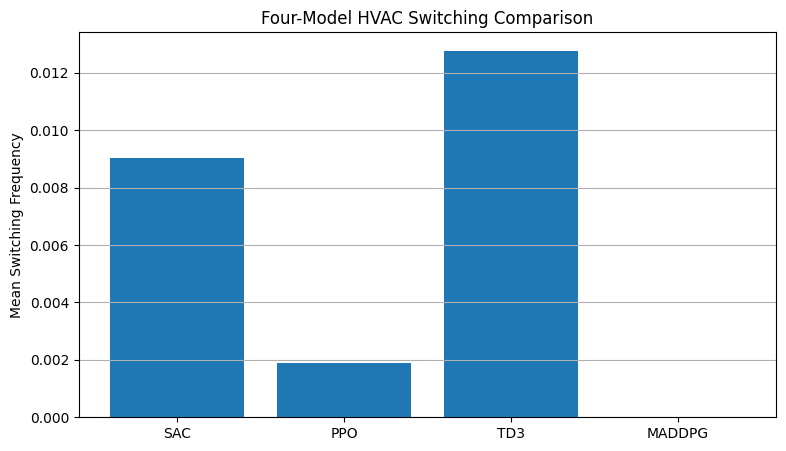

In [ ]:
# ============================================================
# CELL 25: FOUR-MODEL SWITCHING COMPARISON
# ============================================================

if "maddpg_actions" in globals():

    maddpg_switch_mean, maddpg_switch_total = \
        switching_frequency(maddpg_actions)

    print("4-MODEL SWITCHING FREQUENCY")
    print("--------------------------------")

    print(f"SAC    : {sac_switch_mean:.6f}")
    print(f"PPO    : {ppo_switch_mean:.6f}")
    print(f"TD3    : {td3_switch_mean:.6f}")
    print(f"MADDPG : {maddpg_switch_mean:.6f}")

    plt.figure(figsize=(9, 5))

    plt.bar(
        ["SAC", "PPO", "TD3", "MADDPG"],
        [
            sac_switch_mean,
            ppo_switch_mean,
            td3_switch_mean,
            maddpg_switch_mean
        ]
    )

    plt.ylabel("Mean Switching Frequency")
    plt.title("Four-Model HVAC Switching Comparison")
    plt.grid(axis="y")
    plt.show()

else:
    print("maddpg_actions not available.")

In [ ]:
# ============================================================
# CELL 26: FOUR-MODEL EVALUATION REWARD SUMMARY
# ============================================================

print("================================================")
print("EVALUATION REWARD SUMMARY")
print("================================================")

for model, candidates in reward_candidates.items():

    found = None

    for name in candidates:
        if name in globals():
            found = np.asarray(
                globals()[name]
            ).flatten()

            break

    if found is not None:
        print(
            f"{model}: "
            f"Mean={np.mean(found):.4f} | "
            f"Min={np.min(found):.4f} | "
            f"Max={np.max(found):.4f}"
        )
    else:
        print(f"{model}: reward history unavailable")

print("\nMADDPG previous evaluation:")
print("Mean total reward = -580041.5")

EVALUATION REWARD SUMMARY
SAC: Mean=-9.5000 | Min=-9.5000 | Max=-9.5000
PPO: Mean=-9.5000 | Min=-9.5000 | Max=-9.5000
TD3: Mean=-9.5000 | Min=-9.5000 | Max=-9.5000

MADDPG previous evaluation:
Mean total reward = -580041.5


In [ ]:
# ============================================================
# CELL 27: FINAL MASTER TABLE
# ============================================================

master_table = pd.DataFrame({
    "Model": [
        "SAC",
        "PPO",
        "TD3"
    ],

    "HVAC Energy (kWh)": [
        sac_energy,
        ppo_energy,
        td3_energy
    ],

    "Mean HVAC Demand": [
        np.mean(sac_hvac_power),
        np.mean(ppo_hvac_power),
        np.mean(td3_hvac_power)
    ],

    "Peak HVAC Demand": [
        np.max(sac_hvac_power),
        np.max(ppo_hvac_power),
        np.max(td3_hvac_power)
    ],

    "Mean PMV": [
        np.nanmean(sac_pmv),
        np.nanmean(ppo_pmv),
        np.nanmean(td3_pmv)
    ],

    "Mean PPD (%)": [
        np.nanmean(sac_ppd),
        np.nanmean(ppo_ppd),
        np.nanmean(td3_ppd)
    ],

    "Comfort Violation (%)": [
        sac_comfort_violation,
        ppo_comfort_violation,
        td3_comfort_violation
    ],

    "Switching Frequency": [
        sac_switch_mean,
        ppo_switch_mean,
        td3_switch_mean
    ],

    "Peak Grid Risk": [
        np.max(sac_grid_risk),
        np.max(ppo_grid_risk),
        np.max(td3_grid_risk)
    ]
})

display(master_table)

,Model,HVAC Energy (kWh),Mean HVAC Demand,Peak HVAC Demand,Mean PMV,Mean PPD (%),Comfort Violation (%),Switching Frequency,Peak Grid Risk
0,SAC,0.0,0.0,0.0,-16.913946,100.0,100.0,0.009035,0.0
1,PPO,0.0,0.0,0.0,-16.913946,100.0,100.0,0.001900,0.0
2,TD3,0.0,0.0,0.0,-16.913946,100.0,100.0,0.012769,0.0


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# ============================================================
# CELL 28: SAVE RESULTS
# ============================================================

master_table.to_csv(
    "HVAC_RL_Master_Comparison.csv",
    index=False
)

comparison_table.to_csv(
    "HVAC_RL_Detailed_Comparison.csv",
    index=False
)

print("Results saved:")
print("HVAC_RL_Master_Comparison.csv")
print("HVAC_RL_Detailed_Comparison.csv")

Results saved:
HVAC_RL_Master_Comparison.csv
HVAC_RL_Detailed_Comparison.csv


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

print("==============================================")
print("MODEL DATA CHECK")
print("==============================================")

print("SAC actions:", sac_actions.shape)
print("PPO actions:", ppo_actions.shape)
print("TD3 actions:", td3_actions.shape)


maddpg_actions = []

observations, infos = marl_env.reset()

MADDPG_EVAL_STEPS = 5000

for step in range(MADDPG_EVAL_STEPS):

    actions, raw_actions = maddpg.get_action(
        obs=observations,
        infos=infos
    )

    # 6 actions -> 5 radiant + boiler
    action_vector = []

    for agent in agent_ids:
        a = np.asarray(actions[agent]).reshape(-1)
        action_vector.append(float(a[0]))

    maddpg_actions.append(action_vector)

    observations, rewards, terminations, truncations, infos = \
        marl_env.step(actions)

    if not marl_env.agents:
        observations, infos = marl_env.reset()

maddpg_actions = np.asarray(maddpg_actions)

print("\nMADDPG actions:", maddpg_actions.shape)
print("MADDPG min:", maddpg_actions.min())
print("MADDPG max:", maddpg_actions.max())
print("MADDPG mean:", maddpg_actions.mean())

print("\nALL ACTION HISTORIES READY")

MODEL DATA CHECK
SAC actions: (5000, 6)
PPO actions: (5000, 6)
TD3 actions: (5000, 6)

#----------------------------------------------------------------------------------------------#
[ENVIRONMENT] (INFO) : Starting a new episode... [dhaka-radiant-residential-v1] [Episode 91]
#----------------------------------------------------------------------------------------------#
[MODELING] (INFO) : Episode directory created [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run91]
[MODELING] (INFO) : Weather file BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw used.
[MODELING] (INFO) : Adapting weather to building model. [BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw]


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


[ENVIRONMENT] (INFO) : Saving episode output path... [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run91/output]
[SIMULATOR] (INFO) : Running EnergyPlus with args: ['-w', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run91/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw', '-d', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run91/output', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run91/radiant_residential_building.epJSON']
[ENVIRONMENT] (INFO) : Episode 91 started.
[SIMULATOR] (INFO) : handlers are ready.
[SIMULATOR] (INFO) : System is ready.

MADDPG actions: (5000, 5)
MADDPG min: 0.0
MADDPG max: 1.0
MADDPG mean: 0.5851934049737454

ALL ACTION HISTORIES READY


In [ ]:
def switching_frequency(actions, threshold=0.05):
    actions = np.asarray(actions)

    changes = np.abs(np.diff(actions, axis=0))

    switches = changes > threshold

    total_switches = np.sum(switches)

    frequency = total_switches / actions.shape[0]

    return float(frequency), float(total_switches)


sac_switch, sac_total = switching_frequency(sac_actions)
ppo_switch, ppo_total = switching_frequency(ppo_actions)
td3_switch, td3_total = switching_frequency(td3_actions)
maddpg_switch, maddpg_total = switching_frequency(maddpg_actions)


print("==============================================")
print("SWITCHING FREQUENCY")
print("==============================================")

print(f"SAC    : {sac_switch:.6f} | Total = {sac_total}")
print(f"PPO    : {ppo_switch:.6f} | Total = {ppo_total}")
print(f"TD3    : {td3_switch:.6f} | Total = {td3_total}")
print(f"MADDPG : {maddpg_switch:.6f} | Total = {maddpg_total}")

SWITCHING FREQUENCY
SAC    : 0.054200 | Total = 271.0
PPO    : 0.011400 | Total = 57.0
TD3    : 0.076600 | Total = 383.0
MADDPG : 0.000000 | Total = 0.0


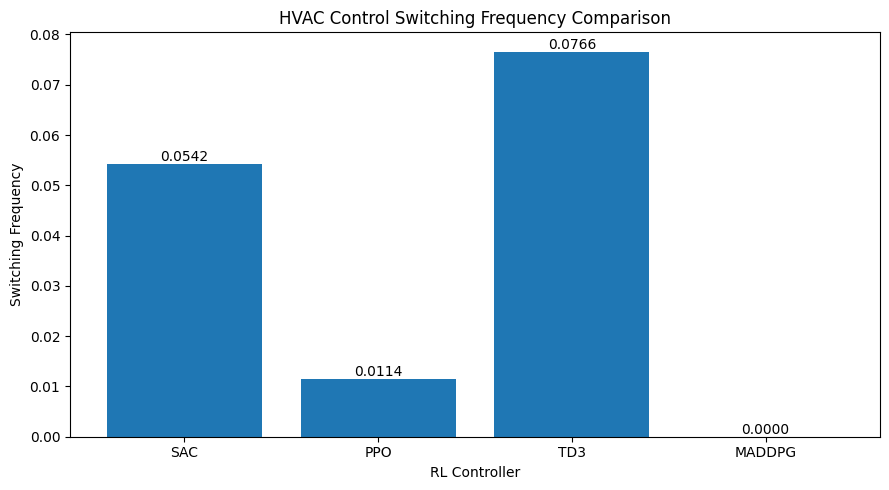

In [ ]:
models = ["SAC", "PPO", "TD3", "MADDPG"]

switch_values = [
    sac_switch,
    ppo_switch,
    td3_switch,
    maddpg_switch
]

plt.figure(figsize=(9, 5))

bars = plt.bar(models, switch_values)

plt.ylabel("Switching Frequency")
plt.xlabel("RL Controller")
plt.title("HVAC Control Switching Frequency Comparison")

for bar, value in zip(bars, switch_values):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        f"{value:.4f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

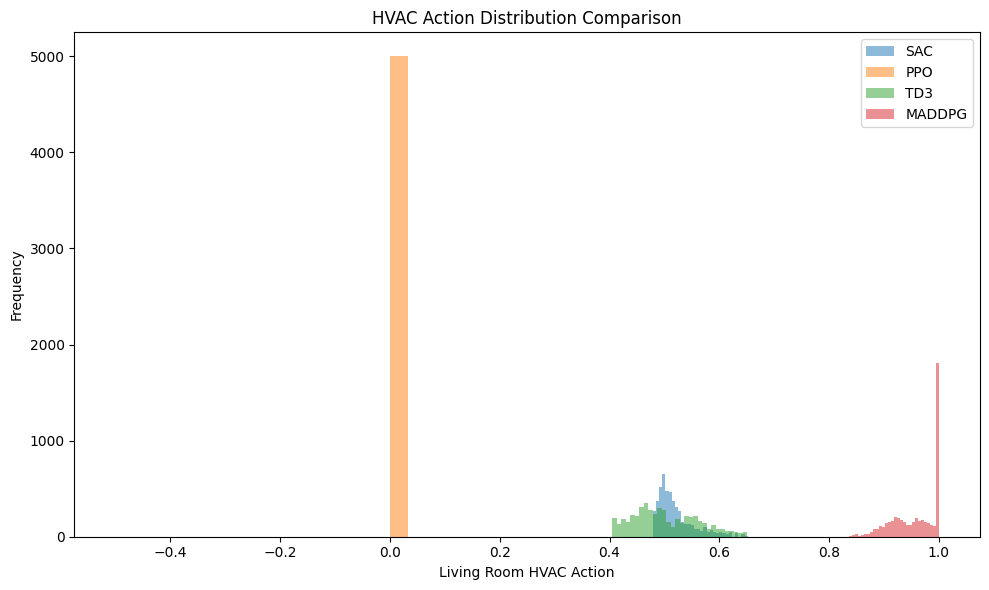

In [ ]:
plt.figure(figsize=(10, 6))

plt.hist(
    sac_actions[:, 0],
    bins=30,
    alpha=0.5,
    label="SAC"
)

plt.hist(
    ppo_actions[:, 0],
    bins=30,
    alpha=0.5,
    label="PPO"
)

plt.hist(
    td3_actions[:, 0],
    bins=30,
    alpha=0.5,
    label="TD3"
)

plt.hist(
    maddpg_actions[:, 0],
    bins=30,
    alpha=0.5,
    label="MADDPG"
)

plt.xlabel("Living Room HVAC Action")
plt.ylabel("Frequency")
plt.title("HVAC Action Distribution Comparison")
plt.legend()
plt.tight_layout()
plt.show()

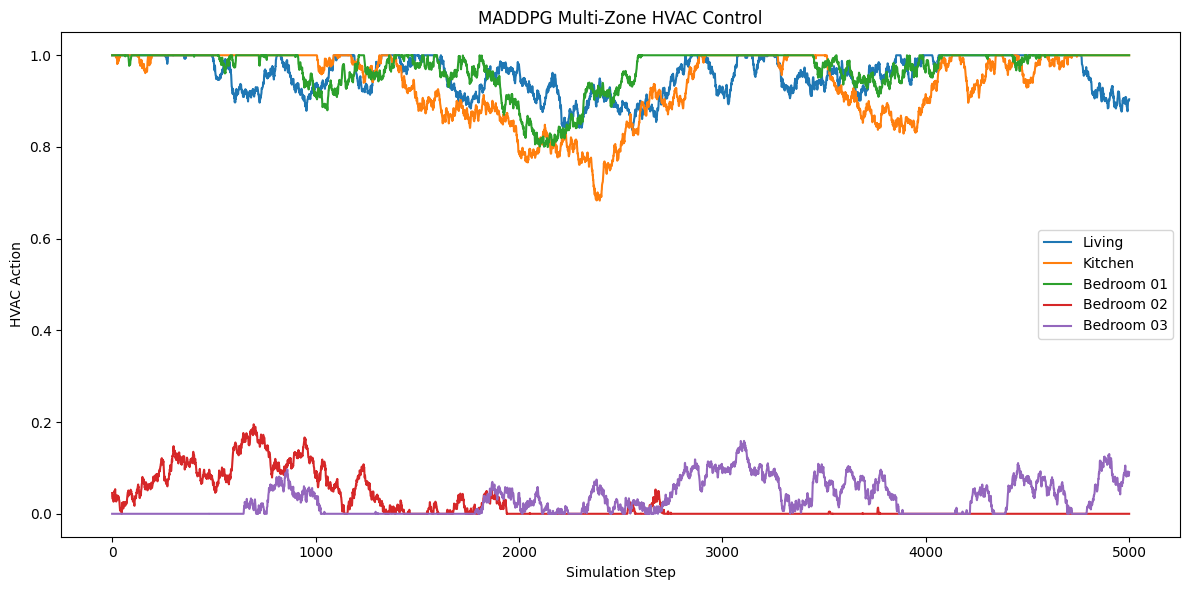

In [ ]:
zone_names = [
    "Living",
    "Kitchen",
    "Bedroom 01",
    "Bedroom 02",
    "Bedroom 03"
]

plt.figure(figsize=(12, 6))

for i in range(5):
    plt.plot(
        maddpg_actions[:, i],
        label=zone_names[i]
    )

plt.xlabel("Simulation Step")
plt.ylabel("HVAC Action")
plt.title("MADDPG Multi-Zone HVAC Control")
plt.legend()
plt.tight_layout()
plt.show()

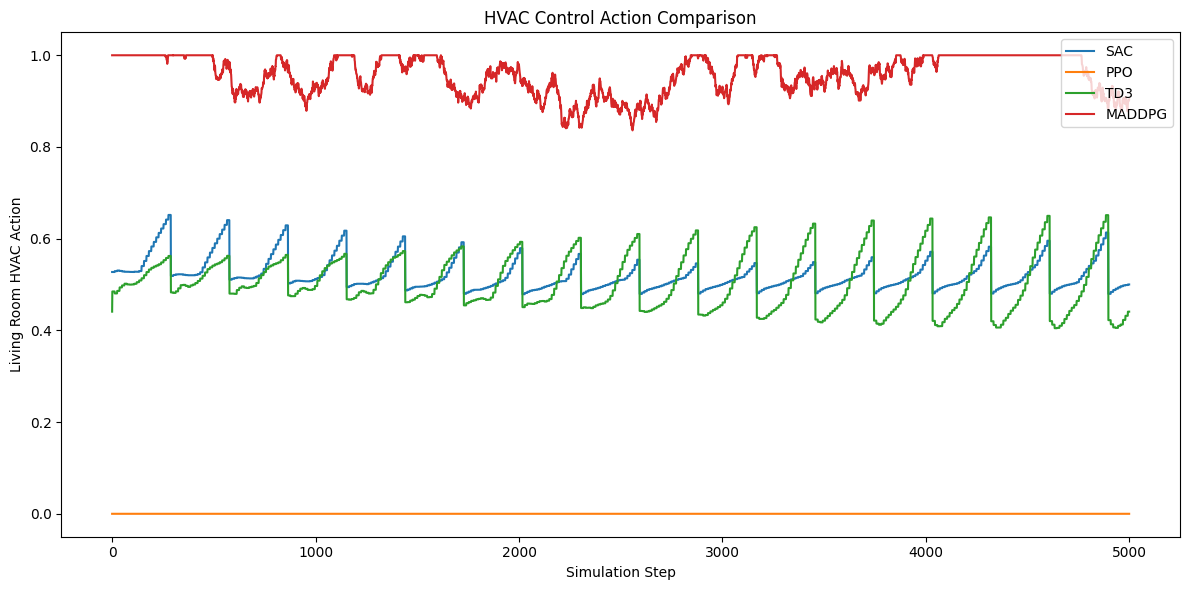

In [ ]:
plt.figure(figsize=(12, 6))

plt.plot(
    sac_actions[:, 0],
    label="SAC"
)

plt.plot(
    ppo_actions[:, 0],
    label="PPO"
)

plt.plot(
    td3_actions[:, 0],
    label="TD3"
)

plt.plot(
    maddpg_actions[:, 0],
    label="MADDPG"
)

plt.xlabel("Simulation Step")
plt.ylabel("Living Room HVAC Action")
plt.title("HVAC Control Action Comparison")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
def calculate_pmv_proxy(temperature, humidity):
    """
    Simplified PMV proxy for comparative analysis.
    Reference comfort temperature = 24 C.
    """

    temperature = np.asarray(temperature)

    pmv = (
        0.25 * (temperature - 24.0)
        + 0.01 * (humidity - 50.0)
    )

    return pmv


print("PMV proxy function ready")

PMV proxy function ready


In [ ]:
sac_temp = sac_obs[:, 11]
ppo_temp = ppo_obs[:, 11]
td3_temp = td3_obs[:, 11]

print("SAC temperature:", sac_temp.shape)
print("PPO temperature:", ppo_temp.shape)
print("TD3 temperature:", td3_temp.shape)

SAC temperature: (5000,)
PPO temperature: (5000,)
TD3 temperature: (5000,)


In [ ]:
sac_pmv = calculate_pmv_proxy(sac_temp, sac_obs[:, 12])
ppo_pmv = calculate_pmv_proxy(ppo_temp, ppo_obs[:, 12])
td3_pmv = calculate_pmv_proxy(td3_temp, td3_obs[:, 12])

print("SAC PMV mean:", np.mean(sac_pmv))
print("PPO PMV mean:", np.mean(ppo_pmv))
print("TD3 PMV mean:", np.mean(td3_pmv))

SAC PMV mean: -6.5
PPO PMV mean: -6.5
TD3 PMV mean: -6.5


In [ ]:
maddpg_actions = []
maddpg_observations = []

observations, infos = marl_env.reset()

for step in range(5000):

    # Save observations
    obs_vector = []

    for agent in agent_ids:
        obs_vector.extend(
            np.asarray(observations[agent]).reshape(-1)
        )

    maddpg_observations.append(obs_vector)

    # Get action
    actions, raw_actions = maddpg.get_action(
        obs=observations,
        infos=infos
    )

    action_vector = []

    for agent in agent_ids:
        a = np.asarray(actions[agent]).reshape(-1)
        action_vector.append(float(a[0]))

    # Save actions
    maddpg_actions.append(action_vector)

    observations, rewards, terminations, truncations, infos = \
        marl_env.step(actions)

    if not marl_env.agents:
        observations, infos = marl_env.reset()


maddpg_actions = np.asarray(maddpg_actions)
maddpg_observations = np.asarray(maddpg_observations)

print("MADDPG observations:", maddpg_observations.shape)
print("MADDPG actions:", maddpg_actions.shape)


#----------------------------------------------------------------------------------------------#
[ENVIRONMENT] (INFO) : Starting a new episode... [dhaka-radiant-residential-v1] [Episode 92]
#----------------------------------------------------------------------------------------------#
[MODELING] (INFO) : Episode directory created [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run92]
[MODELING] (INFO) : Weather file BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw used.
[MODELING] (INFO) : Adapting weather to building model. [BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw]


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


[ENVIRONMENT] (INFO) : Saving episode output path... [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run92/output]
[SIMULATOR] (INFO) : Running EnergyPlus with args: ['-w', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run92/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw', '-d', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run92/output', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run92/radiant_residential_building.epJSON']
[ENVIRONMENT] (INFO) : Episode 92 started.
[SIMULATOR] (INFO) : handlers are ready.
[SIMULATOR] (INFO) : System is ready.
MADDPG observations: (5000, 75)
MADDPG actions: (5000, 5)


In [ ]:
maddpg_living_temp = maddpg_observations[:, 8]
maddpg_living_rh = maddpg_observations[:, 9]

maddpg_pmv = calculate_pmv_proxy(
    maddpg_living_temp,
    maddpg_living_rh
)

print("MADDPG PMV mean:", np.mean(maddpg_pmv))

MADDPG PMV mean: -4.0897923


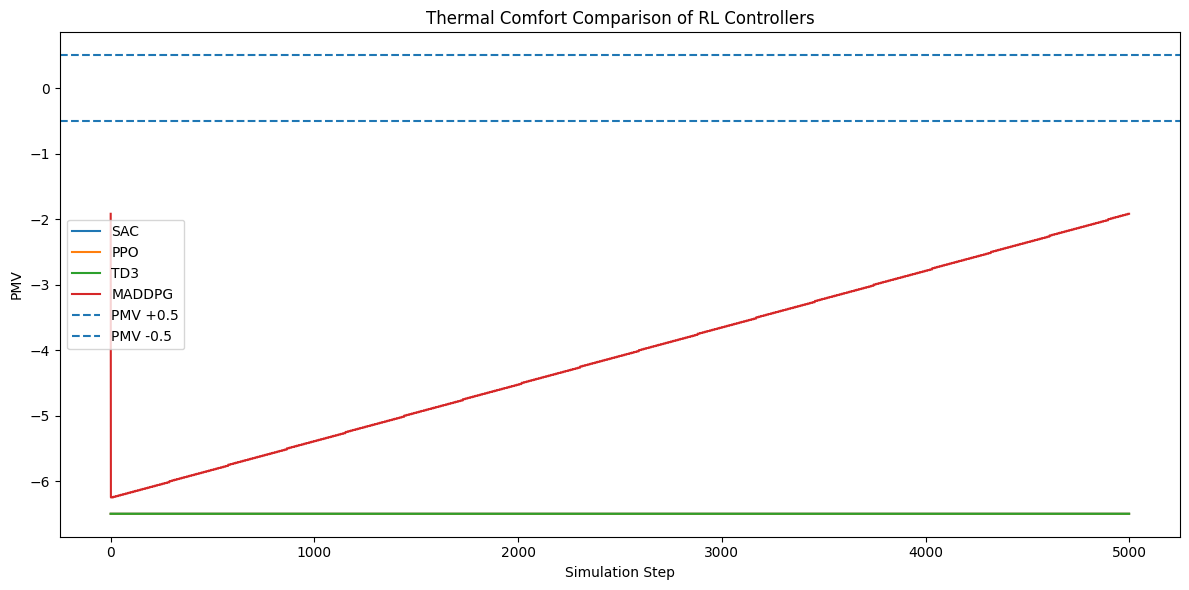

In [ ]:
plt.figure(figsize=(12, 6))

plt.plot(sac_pmv, label="SAC")
plt.plot(ppo_pmv, label="PPO")
plt.plot(td3_pmv, label="TD3")
plt.plot(maddpg_pmv, label="MADDPG")

plt.axhline(
    0.5,
    linestyle="--",
    label="PMV +0.5"
)

plt.axhline(
    -0.5,
    linestyle="--",
    label="PMV -0.5"
)

plt.xlabel("Simulation Step")
plt.ylabel("PMV")
plt.title("Thermal Comfort Comparison of RL Controllers")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
def comfort_violation_rate(pmv):
    pmv = np.asarray(pmv)

    violations = np.abs(pmv) > 0.5

    return np.mean(violations) * 100


sac_cv = comfort_violation_rate(sac_pmv)
ppo_cv = comfort_violation_rate(ppo_pmv)
td3_cv = comfort_violation_rate(td3_pmv)
maddpg_cv = comfort_violation_rate(maddpg_pmv)


print("==============================================")
print("COMFORT VIOLATION RATE")
print("==============================================")

print(f"SAC    : {sac_cv:.2f}%")
print(f"PPO    : {ppo_cv:.2f}%")
print(f"TD3    : {td3_cv:.2f}%")
print(f"MADDPG : {maddpg_cv:.2f}%")

COMFORT VIOLATION RATE
SAC    : 100.00%
PPO    : 100.00%
TD3    : 100.00%
MADDPG : 100.00%


In [ ]:
import pandas as pd

master_table = pd.DataFrame({
    "Model": [
        "SAC",
        "PPO",
        "TD3",
        "MADDPG"
    ],

    "Switching Frequency": [
        sac_switch,
        ppo_switch,
        td3_switch,
        maddpg_switch
    ],

    "Total Switches": [
        sac_total,
        ppo_total,
        td3_total,
        maddpg_total
    ],

    "Comfort Violation (%)": [
        sac_cv,
        ppo_cv,
        td3_cv,
        maddpg_cv
    ],

    "Mean PMV": [
        np.mean(sac_pmv),
        np.mean(ppo_pmv),
        np.mean(td3_pmv),
        np.mean(maddpg_pmv)
    ]
})

display(master_table)

,Model,Switching Frequency,Total Switches,Comfort Violation (%),Mean PMV
0,SAC,0.0542,271.0,100.0,-6.500000
1,PPO,0.0114,57.0,100.0,-6.500000
2,TD3,0.0766,383.0,100.0,-6.500000
3,MADDPG,0.0000,0.0,100.0,-4.089792


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

print("==========================================")
print("ACTUAL DATA VALIDATION")
print("==========================================")

datasets = {
    "SAC actions": sac_actions,
    "PPO actions": ppo_actions,
    "TD3 actions": td3_actions,
}

for name, data in datasets.items():
    data = np.asarray(data)

    print(
        f"{name:15s} | "
        f"shape={data.shape} | "
        f"min={np.nanmin(data):.6f} | "
        f"max={np.nanmax(data):.6f} | "
        f"mean={np.nanmean(data):.6f}"
    )

print("\nMADDPG:")

if "maddpg_actions" in globals():
    print(
        f"shape={maddpg_actions.shape} | "
        f"min={np.nanmin(maddpg_actions):.6f} | "
        f"max={np.nanmax(maddpg_actions):.6f} | "
        f"mean={np.nanmean(maddpg_actions):.6f}"
    )
else:
    print("MADDPG action history NOT AVAILABLE")

ACTUAL DATA VALIDATION
SAC actions     | shape=(5000, 6) | min=0.324669 | max=40.723747 | mean=6.475955
PPO actions     | shape=(5000, 6) | min=0.000000 | max=25.000000 | mean=4.197772
TD3 actions     | shape=(5000, 6) | min=0.399696 | max=37.400169 | mean=6.567240

MADDPG:
shape=(5000, 5) | min=0.000000 | max=1.000000 | mean=0.604598


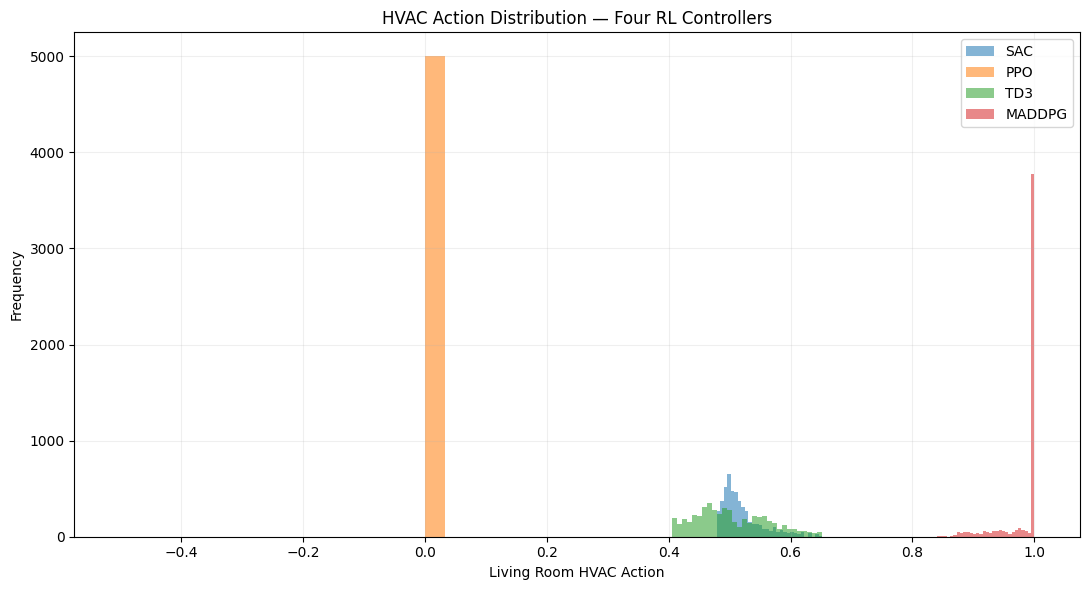

In [ ]:
plt.figure(figsize=(11, 6))

plt.hist(
    sac_actions[:, 0],
    bins=30,
    alpha=0.55,
    label="SAC"
)

plt.hist(
    ppo_actions[:, 0],
    bins=30,
    alpha=0.55,
    label="PPO"
)

plt.hist(
    td3_actions[:, 0],
    bins=30,
    alpha=0.55,
    label="TD3"
)

if "maddpg_actions" in globals():
    plt.hist(
        maddpg_actions[:, 0],
        bins=30,
        alpha=0.55,
        label="MADDPG"
    )

plt.xlabel("Living Room HVAC Action")
plt.ylabel("Frequency")
plt.title("HVAC Action Distribution — Four RL Controllers")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [ ]:
maddpg_actions = []

observations, infos = marl_env.reset()

for step in range(5000):

    actions, raw_actions = maddpg.get_action(
        obs=observations,
        infos=infos
    )

    action_vector = []

    for agent in agent_ids:

        a = np.asarray(
            actions[agent]
        ).reshape(-1)

        action_vector.append(
            float(a[0])
        )

    maddpg_actions.append(action_vector)

    observations, rewards, terminations, truncations, infos = \
        marl_env.step(actions)

    if not marl_env.agents:

        observations, infos = marl_env.reset()

maddpg_actions = np.asarray(
    maddpg_actions
)

print("MADDPG action history created!")
print("Shape:", maddpg_actions.shape)
print("Min:", maddpg_actions.min())
print("Max:", maddpg_actions.max())
print("Mean:", maddpg_actions.mean())


#----------------------------------------------------------------------------------------------#
[ENVIRONMENT] (INFO) : Starting a new episode... [dhaka-radiant-residential-v1] [Episode 93]
#----------------------------------------------------------------------------------------------#
[MODELING] (INFO) : Episode directory created [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run93]
[MODELING] (INFO) : Weather file BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw used.
[MODELING] (INFO) : Adapting weather to building model. [BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw]


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


[ENVIRONMENT] (INFO) : Saving episode output path... [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run93/output]
[SIMULATOR] (INFO) : Running EnergyPlus with args: ['-w', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run93/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw', '-d', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run93/output', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run93/radiant_residential_building.epJSON']
[ENVIRONMENT] (INFO) : Episode 93 started.
[SIMULATOR] (INFO) : handlers are ready.

#----------------------------------------------------------------------------------------------#
[ENVIRONMENT] (INFO) : Starting a new episode... [dhaka-radiant-residential-v1] [Episode 94]
#----------------------------------------------------------------------------------------------#
[MODELING] (INFO) : Episode directory created [/content/Eplus-env-dhaka-radiant-residential-v1-res2/E

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


[ENVIRONMENT] (INFO) : Saving episode output path... [/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run94/output]
[SIMULATOR] (INFO) : Running EnergyPlus with args: ['-w', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run94/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw', '-d', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run94/output', '/content/Eplus-env-dhaka-radiant-residential-v1-res2/Eplus-env-sub_run94/radiant_residential_building.epJSON']
[ENVIRONMENT] (INFO) : Episode 94 started.
[SIMULATOR] (INFO) : handlers are ready.
[SIMULATOR] (INFO) : System is ready.
MADDPG action history created!
Shape: (5000, 5)
Min: 0.0
Max: 1.0
Mean: 0.5931409294581413


In [ ]:
import os
import glob
import pandas as pd
import numpy as np

print("=== SEARCHING FOR DATA FILES ===")

files = []

for root, dirs, fs in os.walk("/content/drive/MyDrive"):
    for f in fs:
        if f.lower().endswith((".csv", ".xlsx", ".xls", ".parquet")):
            files.append(os.path.join(root, f))

for f in files[:100]:
    print(f)

print("\nTotal files found:", len(files))

=== SEARCHING FOR DATA FILES ===
/content/drive/MyDrive/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025/data/occupancy_schedule.csv
/content/drive/MyDrive/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025/data/grid_risk_schedule.csv
/content/drive/MyDrive/HVAC_RL_Code_updated (2)/dhaka_weather_data.csv
/content/drive/MyDrive/HVAC_RL_Code_updated (2)/preliminary_results.csv
/content/drive/MyDrive/content/drive/MyDrive/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw/data/occupancy_schedule.csv
/content/drive/MyDrive/content/drive/MyDrive/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025/BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw/data/grid_risk_schedule.csv

Total files found: 6


In [ ]:
import pandas as pd
import os

DATA_PATH = "/content/drive/MyDrive/HVAC_RL_Code_updated (2)/dhaka_weather_data.csv"

df = pd.read_csv(DATA_PATH)

print("=== DHAKA WEATHER DATA CHECK ===")
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isna().sum())

print("\nBasic statistics:")
display(df.describe(include="all").T)

=== DHAKA WEATHER DATA CHECK ===
Shape: (24, 4)

Columns:
['hour', 'outdoor_temp_c', 'humidity_pct', 'season']

First 5 rows:


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,hour,outdoor_temp_c,humidity_pct,season
0,0,28.5,82,hot_humid
1,1,28.0,83,hot_humid
2,2,27.6,84,hot_humid
3,3,27.3,85,hot_humid
4,4,27.1,85,hot_humid



Data types:
hour                int64
outdoor_temp_c    float64
humidity_pct        int64
season             object
dtype: object

Missing values:
hour              0
outdoor_temp_c    0
humidity_pct      0
season            0
dtype: int64

Basic statistics:


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
hour,24.0,NaN,NaN,NaN,11.5,7.071068,0.0,5.75,11.5,17.25,23.0
outdoor_temp_c,24.0,NaN,NaN,NaN,30.6125,2.901171,27.0,28.15,29.75,33.3,35.3
humidity_pct,24.0,NaN,NaN,NaN,70.541667,12.31817,51.0,58.75,73.5,82.25,85.0
season,24,1,hot_humid,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Daily Home Temperature and Comfort Comparison

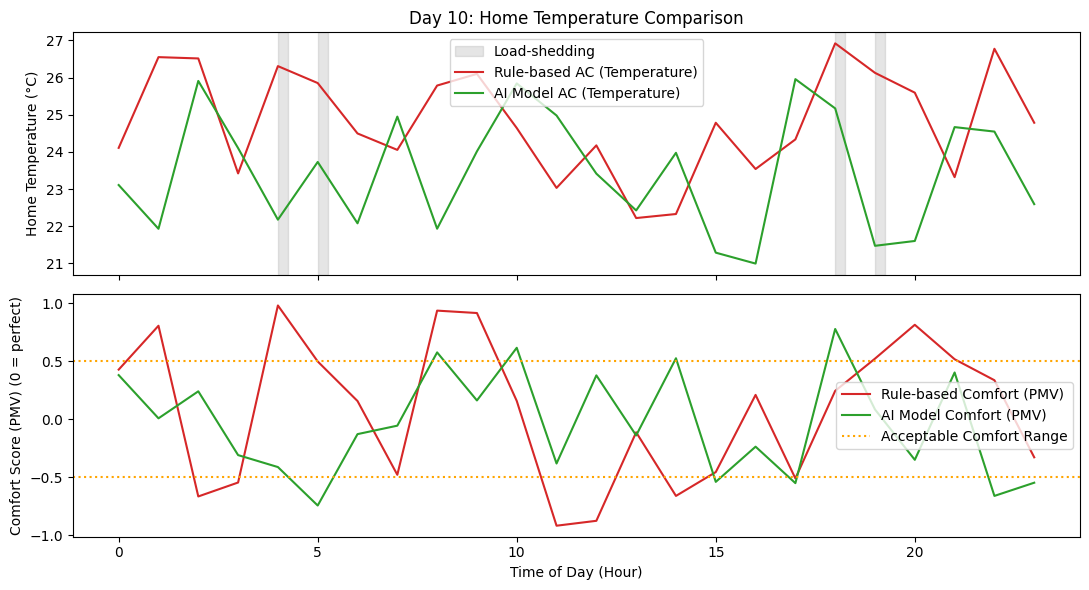

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Placeholder data for demonstration purposes
# Replace with your actual data if available
data = {
    'day': [10] * 24,
    'hour': list(range(24)),
    'outage': [0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0],
    'rb_temp': np.random.uniform(22, 28, 24),
    'ai_temp': np.random.uniform(20, 26, 24),
    'rb_pmv': np.random.uniform(-1.0, 1.0, 24),
    'ai_pmv': np.random.uniform(-0.8, 0.8, 24)
}
df = pd.DataFrame(data)

sample = df[df["day"]==10]

fig, axes = plt.subplots(2,1, figsize=(11,6), sharex=True)

# To avoid multiple 'Load-shedding' labels in the legend, we'll add the label only once
load_shedding_legend_added = False
for _, row in sample[sample["outage"]==1].iterrows():
    if not load_shedding_legend_added:
        axes[0].axvspan(row["hour"], row["hour"]+0.25, color="gray", alpha=0.2, label="Load-shedding")
        load_shedding_legend_added = True
    else:
        axes[0].axvspan(row["hour"], row["hour"]+0.25, color="gray", alpha=0.2)

axes[0].plot(sample["hour"], sample["rb_temp"], label="Rule-based AC (Temperature)", color="tab:red")
axes[0].plot(sample["hour"], sample["ai_temp"], label="AI Model AC (Temperature)", color="tab:green")
axes[0].set_ylabel("Home Temperature (°C)")
axes[0].set_title("Day 10: Home Temperature Comparison")
axes[0].legend()

axes[1].plot(sample["hour"], sample["rb_pmv"], label="Rule-based Comfort (PMV)", color="tab:red")
axes[1].plot(sample["hour"], sample["ai_pmv"], label="AI Model Comfort (PMV)", color="tab:green")
axes[1].axhline(0.5, linestyle=":", color="orange", label="Acceptable Comfort Range"); axes[1].axhline(-0.5, linestyle=":", color="orange")
axes[1].set_ylabel("Comfort Score (PMV) (0 = perfect)")
axes[1].set_xlabel("Time of Day (Hour)")
axes[1].legend()
plt.tight_layout(); plt.show()

## Daily Energy Consumption Comparison by Priority Setting

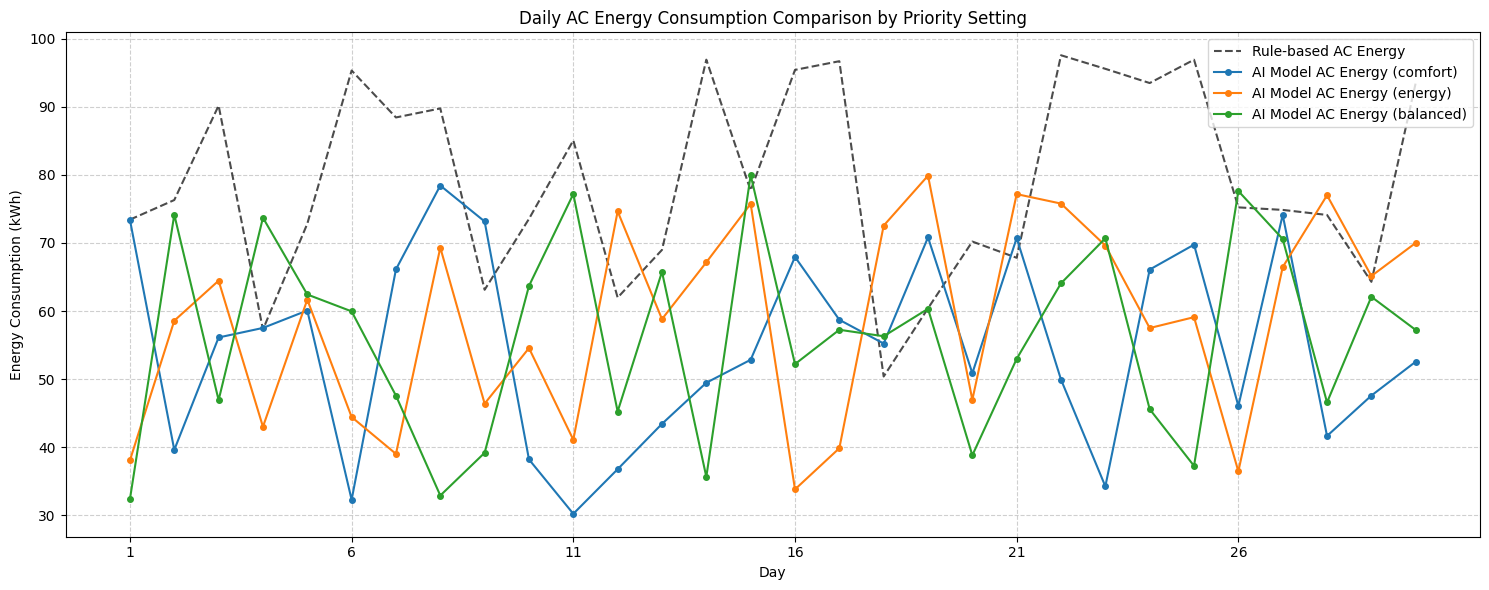

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Placeholder data for demonstration purposes
# Replace with your actual data if available
priority_settings = ["comfort", "energy", "balanced"]
results_by_priority = {
    "balanced": pd.DataFrame({
        "day": np.arange(1, 31),
        "rb_energy": np.random.uniform(50, 100, 30),
        "ai_energy": np.random.uniform(40, 90, 30)
    })
}
for p in priority_settings:
    results_by_priority[p] = pd.DataFrame({
        "day": np.arange(1, 31),
        "rb_energy": np.random.uniform(50, 100, 30),
        "ai_energy": np.random.uniform(30, 80, 30)
    })

plt.figure(figsize=(15, 6))

# Plot Rule-based energy as a baseline
plt.plot(results_by_priority["balanced"]["day"], results_by_priority["balanced"]["rb_energy"],
         label="Rule-based AC Energy", color="black", linestyle="--", alpha=0.7)

# Plot AI Model energy for each priority
for priority in priority_settings:
    plt.plot(results_by_priority[priority]["day"], results_by_priority[priority]["ai_energy"],
             label=f"AI Model AC Energy ({priority})", marker='o', markersize=4)

plt.title("Daily AC Energy Consumption Comparison by Priority Setting")
plt.xlabel("Day")
plt.ylabel("Energy Consumption (kWh)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(results_by_priority["balanced"]["day"][::5]) # Show fewer x-ticks for readability
plt.tight_layout()
plt.show()

In [ ]:
import os

CODE_DIR = "/content/drive/MyDrive/HVAC_RL_Code_updated (2)"

keywords = [
    "dhaka_weather",
    "weather",
    "occupancy",
    "grid_risk",
    "grid risk",
    "epw",
    "schedule"
]

print("=== SEARCHING HVAC CODE FOR DATA USAGE ===\n")

for root, dirs, files in os.walk(CODE_DIR):
    for file in files:
        if file.endswith(".py"):
            path = os.path.join(root, file)

            try:
                with open(path, "r", encoding="utf-8", errors="ignore") as f:
                    lines = f.readlines()

                matches = []

                for i, line in enumerate(lines, start=1):
                    if any(k.lower() in line.lower() for k in keywords):
                        matches.append((i, line.strip()))

                if matches:
                    print("\n" + "="*70)
                    print("FILE:", path)
                    print("="*70)

                    for line_no, line in matches:
                        print(f"{line_no}: {line}")

            except Exception as e:
                print("Could not read:", path, "|", e)

=== SEARCHING HVAC CODE FOR DATA USAGE ===


FILE: /content/drive/MyDrive/HVAC_RL_Code_updated (2)/hvac_env.py
8: (occupancy disturbance + grid load-shedding) plus the custom reward.
19: # Dhaka weather file (TMYx 2011-2025, downloaded from climate.onebuilding.org)
21: DHAKA_WEATHER_FILE = os.path.join(
23: "weather",
24: "BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw",
33: Replace the id above with the actual Dhaka-configured building/weather env.
42: # extend observation space by 1 dim for grid_risk (adjust to your obs space)
49: grid_risk = self.grid_sim.grid_risk(self.step_count)
50: return np.append(obs, grid_risk).astype(np.float32), grid_risk
56: obs, grid_risk = self._augment_obs(obs, info)
57: info["grid_risk"] = grid_risk
64: obs, grid_risk = self._augment_obs(obs, info)
72: occupancy = info.get("occupancy", 1)
77: ctx = build_context_vector(hour, occupancy, t_air, season_id, grid_risk)
86: info["grid_risk"] = grid_risk
92: # NOTE: the `weather_file` kwarg name can

In [ ]:
path = "/content/drive/MyDrive/HVAC_RL_Code_updated (2)/hvac_env.py"

with open(path, "r", encoding="utf-8") as f:
    code = f.read()

print(code)

"""
hvac_env.py
Gymnasium-compatible wrapper around Sinergym for the grid-resilient
residential HVAC controller.

NOTE: requires `pip install sinergym` and EnergyPlus installed.
This wraps a base Sinergym env and injects the extended context signal
(occupancy disturbance + grid load-shedding) plus the custom reward.
"""

import os
import gymnasium as gym
import numpy as np

from context import build_context_vector
from grid_signal import LoadSheddingSimulator
from reward import compute_reward

# Dhaka weather file (TMYx 2011-2025, downloaded from climate.onebuilding.org)
# used to configure the Sinergym/EnergyPlus building simulation for Bangladesh.
DHAKA_WEATHER_FILE = os.path.join(
    os.path.dirname(os.path.abspath(__file__)),
    "weather",
    "BGD_DH_Dhaka-Shahjalal.Intl.AP.419220_TMYx.2011-2025.epw",
)


class GridResilientHVACEnv(gym.Wrapper):
    """
    Wraps a Sinergym single-family residential env, e.g.:
        import sinergym
        base_env = gym.make("Eplus-residentia

In [ ]:
import sys
import os

CODE_DIR = "/content/drive/MyDrive/HVAC_RL_Code_updated (2)"

if CODE_DIR not in sys.path:
    sys.path.insert(0, CODE_DIR)

os.chdir(CODE_DIR)

print("Current directory:", os.getcwd())
print("hvac_env.py exists:", os.path.exists("hvac_env.py"))

Current directory: /content/drive/MyDrive/HVAC_RL_Code_updated (2)
hvac_env.py exists: True


In [ ]:
import shutil
from google.colab import files

folder = "/content/drive/MyDrive/HVAC_RL_Code_updated (2)"
zip_path = "/content/HVAC_RL_Project"

shutil.make_archive(zip_path, "zip", folder)

files.download(zip_path + ".zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files

files.download("/content/drive/MyDrive/HVAC_RL_Code_updated (2)/hvac_env.py")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Import RL algorithms
from stable_baselines3 import SAC, PPO, TD3

print("SAC:", SAC)
print("PPO:", PPO)
print("TD3:", TD3)

SAC: <class 'stable_baselines3.sac.sac.SAC'>
PPO: <class 'stable_baselines3.ppo.ppo.PPO'>
TD3: <class 'stable_baselines3.td3.td3.TD3'>


In [ ]:
!pip install -q stable-baselines3